# Cryptocurrency Market Behaviour: Statistical Analysis, Hypothesis Testing & Regression-Based Volume Prediction

**Course:** 23CSE351 – Foundations of Data Science (Case Study)
**Dataset:** `https://www.kaggle.com/datasets/adrianjuliusaluoch/hourly-crypto-stocks-market-data` — time-stamped market snapshots of the largest cryptocurrencies by market capitalisation
**Scope:** 109,130 records × 11 attributes, 71 distinct assets, 26 Jan 2026 → 08 Aug 2026

---

## Problem Statement

Crypto-assets trade 24×7 across hundreds of venues, and their prices, trading volumes and market capitalisations move far more violently than traditional assets. Investors, exchanges and risk teams need evidence-based answers to questions such as: *How concentrated is the market? Which assets are actually volatile and which are not? Do assets move together? Is trading activity different at weekends? Can we estimate how much an asset "should" trade given its size and price movement?*

## Objectives

1. **Pre-process** the raw snapshot data: verify column meanings, detect anomalies (rounded prices, zero volumes, extreme returns), handle changes in collection coverage, and build an analysis-ready daily panel.
2. **Explore** the market with summary statistics and visualisations (distributions, concentration, correlations, CLT, confidence intervals).
3. **Answer 15 analysis questions** with suitable methods, plots, interpretation and justification.
4. **Formulate and test hypotheses** (including **A/B tests**) with assumption checks, p-values and effect sizes.
5. **Build and evaluate a regression model** that predicts an asset's (log) 24-hour trading volume, with assumption checks, coefficients and test-set metrics.
6. Summarise **findings, conclusions, limitations and future enhancements**.

## 1. Dataset Description

Each row is one **snapshot** of one asset at one moment in time. The snapshot list is the set of top assets ranked by market capitalisation at collection time.

| Column | Type | Meaning (verified in Section 5) |
|:---|:---|:---|
| `timestamp` | datetime | Time at which the snapshot was collected |
| `name` | categorical | Asset name (e.g. Bitcoin, Ethereum, Tether) |
| `symbol` | categorical | Asset ticker in lower case (e.g. `btc`, `eth`) |
| `price_usd` | float | Price in US dollars, **rounded to 2 decimals** |
| `vol_24h` | float | Trading volume in USD over the previous 24 hours |
| `total_vol` | float | The asset's **share (%) of the combined 24h volume** of all assets in the same snapshot (shown in §5.2: shares sum to 100% per timestamp) |
| `chg_24h` | float | % price change over the previous 24 hours |
| `chg_7d` | float | % price change over the previous 7 days |
| `market_cap` | float | Market capitalisation in USD |
| `name_encoded` | int | Label-encoded `name` (0–70) |
| `symbol_encoded` | int | Label-encoded `symbol` (0–70) |

> **Dataset source:** https://www.kaggle.com/datasets/adrianjuliusaluoch/hourly-crypto-stocks-market-data

## 2. Analysis Questions

### Theme A – Market structure & concentration
* **Q1.** How concentrated is total market capitalisation among the tracked assets?
* **Q2.** How did Bitcoin's dominance (share of tracked market cap) evolve over time?
* **Q3.** Is trading volume concentrated in the same assets that dominate market cap?
* **Q4.** How liquid are assets relative to their size (turnover = 24h volume ÷ market cap)?

### Theme B – Returns & risk
* **Q5.** What does the distribution of daily (24h) returns look like — is it normal?
* **Q6.** Which assets are the most and least volatile?
* **Q7.** How different is the volatility of stable-value tokens and volatile tokens? *(A/B)*
* **Q8.** Are larger assets less volatile than smaller ones?
* **Q9.** How did Bitcoin's price evolve over the full period, and what was its worst drawdown?

### Theme C – Co-movement & time effects
* **Q10.** How strongly do the daily returns of major assets move together?
* **Q11.** How sensitive is each major asset to Bitcoin's moves (beta)?
* **Q12.** Does market activity or Bitcoin's return differ by day of the week?
* **Q13.** Is total market trading volume lower on weekends than on weekdays? *(A/B)*
* **Q14.** Is trading activity related to the size of price moves (volume–volatility relation)?
* **Q15.** When Bitcoin moves, does the rest of the market move in the same direction (market breadth)?

## 3. Libraries and Environment Configuration

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import scipy
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 100

BLUE, ORANGE, LIGHT = '#2b5c8f', '#d95f02', '#4a7bb0'
PALETTE_TYPE = {'Stable-value': BLUE, 'Volatile': ORANGE}
ALPHA = 0.05
np.random.seed(42)

print(f"Pandas {pd.__version__} | NumPy {np.__version__} | SciPy {scipy.__version__} | statsmodels {sm.__version__ if hasattr(sm,'__version__') else ''}")

Pandas 3.0.5 | NumPy 2.5.3 | SciPy 1.18.1 | statsmodels 0.15.0


## 4. Data Loading and Structural Inspection
Place `cleaned_crypto.csv` in the same folder as this notebook.

In [2]:
file_path = "cleaned_crypto.csv"
if not os.path.exists(file_path):
    raise FileNotFoundError(f"'{file_path}' not found in the current directory.")

df_raw = pd.read_csv(file_path)
df = df_raw.copy()

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print(f"Memory: {df.memory_usage(deep=True).sum()/1024**2:.2f} MB")
display(df.head())

Rows: 109,130 | Columns: 11


Memory: 25.20 MB


,timestamp,name,symbol,price_usd,vol_24h,total_vol,chg_24h,chg_7d,market_cap,name_encoded,symbol_encoded
0,2026-02-04 06:29:01,Aave,aave,127.2900,"449,760,372.0000",0.1500,0.8900,-19.8400,"1,934,683,301.0000",0,0
1,2026-02-04 07:55:28,Aave,aave,127.5400,"433,696,272.0000",0.1500,-0.9200,-19.3900,"1,938,336,206.0000",0,0
2,2026-02-04 08:39:57,Aave,aave,127.5000,"429,968,987.0000",0.1400,-0.1500,-19.4100,"1,936,521,801.0000",0,0
3,2026-02-04 09:30:25,Aave,aave,126.9300,"434,924,191.0000",0.1500,-0.1100,-19.5500,"1,927,322,302.0000",0,0
4,2026-02-04 10:27:32,Aave,aave,127.4400,"430,671,128.0000",0.1500,-0.3900,-19.1700,"1,935,764,343.0000",0,0


In [3]:
schema = pd.DataFrame({
    'Column': df.columns,
    'Dtype': df.dtypes.astype(str).values,
    'Non-Null': df.count().values,
    'Nulls': df.isnull().sum().values,
    'Unique': [df[c].nunique() for c in df.columns],
    'Sample values': [df[c].unique()[:3].tolist() for c in df.columns]
})
display(schema)
print("Numerical summary (raw):")
display(df.describe().T)

,Column,Dtype,Non-Null,Nulls,Unique,Sample values
0,timestamp,str,109130,0,2573,"[2026-02-04 06:29:01, 2026-02-04 07:55:28, 202..."
1,name,str,109130,0,71,"[Aave, Aster, Avalanche]"
2,symbol,str,109130,0,71,"[aave, aster, avax]"
3,price_usd,float64,109130,0,26471,"[127.29, 127.54, 127.5]"
4,vol_24h,float64,109130,0,104207,"[449760372.0, 433696272.0, 429968987.0]"
5,total_vol,float64,109130,0,2860,"[0.15, 0.14, 0.16]"
6,chg_24h,float64,109130,0,3582,"[0.89, -0.92, -0.15]"
7,chg_7d,float64,109130,0,6675,"[-19.84, -19.39, -19.41]"
8,market_cap,float64,109130,0,104495,"[1934683301.0, 1938336206.0, 1936521801.0]"
9,name_encoded,int64,109130,0,71,"[0, 1, 2]"


Numerical summary (raw):


,count,mean,std,min,25%,50%,75%,max
price_usd,"109,130.0000","2,415.1549","12,277.5017",0.0000,0.7100,1.1000,68.9075,"90,117.0000"
vol_24h,"109,130.0000","3,946,300,510.5312","14,864,231,009.5159",0.0000,"42,254,354.0000","173,921,349.5000","594,353,061.5000","340,480,486,199.0000"
total_vol,"109,130.0000",2.3577,7.9634,0.0000,0.0300,0.1100,0.3400,74.0000
chg_24h,"109,130.0000",-0.0561,4.5657,-60.0500,-1.4700,-0.0000,0.9800,265.3600
chg_7d,"109,130.0000",0.3948,67.8543,-44.8400,-4.0200,-0.0100,1.8000,"6,153.5300"
market_cap,"109,130.0000","55,654,403,407.8185","217,571,063,729.1743","1,441,562,894.0000","2,662,458,858.7500","4,529,303,266.0000","11,618,179,708.2500","1,800,863,283,261.0000"
name_encoded,"109,130.0000",33.4533,20.3597,0.0000,16.0000,32.0000,52.0000,70.0000
symbol_encoded,"109,130.0000",33.8132,21.0414,0.0000,15.0000,33.0000,51.0000,70.0000


## 5. Data Preprocessing

The file is described as "cleaned", but a cleaned file still has to be **verified** before analysis. Steps:

1. Type conversion, missing values, duplicate rows and duplicate (timestamp, asset) pairs.
2. Verify the meaning of `total_vol`.
3. Check redundancy of the encoded columns.
4. Detect changes in **collection coverage** over time.
5. Audit anomalies: zero prices, zero volumes, extreme returns, IQR outliers.
6. Feature engineering (asset type, turnover, log transforms, calendar features).
7. Build a **daily panel** (one end-of-day snapshot per asset per day) for statistical testing.

### 5.1 Types, missing values and duplicates

In [4]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['timestamp', 'name']).reset_index(drop=True)

print("Missing values per column:")
display(df.isnull().sum().to_frame('Missing').T)
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print(f"Duplicate (timestamp, name) pairs: {df.duplicated(['timestamp','name']).sum()}")
print(f"Time span: {df['timestamp'].min()}  ->  {df['timestamp'].max()}")
print(f"Distinct snapshots (timestamps): {df['timestamp'].nunique():,}")
print(f"Distinct assets: {df['name'].nunique()}")

Missing values per column:


,timestamp,name,symbol,price_usd,vol_24h,total_vol,chg_24h,chg_7d,market_cap,name_encoded,symbol_encoded
Missing,0,0,0,0,0,0,0,0,0,0,0


Exact duplicate rows: 0
Duplicate (timestamp, name) pairs: 0
Time span: 2026-01-26 16:54:46  ->  2026-08-08 18:00:38
Distinct snapshots (timestamps): 2,573
Distinct assets: 71


### 5.2 Verifying the meaning of `total_vol`
Hypothesis about the column: `total_vol` = asset's 24h volume ÷ sum of 24h volume of all assets in that snapshot × 100. If true, (a) it should sum to ≈100 in every snapshot and (b) it should equal the recomputed share up to rounding (2 decimals ⇒ max error 0.005).

In [5]:
recomputed_share = df['vol_24h'] / df.groupby('timestamp')['vol_24h'].transform('sum') * 100
sum_per_ts = df.groupby('timestamp')['total_vol'].sum()

print(f"Sum of total_vol per snapshot: min={sum_per_ts.min():.2f}, max={sum_per_ts.max():.2f}")
print(f"Correlation(total_vol, recomputed share) = {np.corrcoef(df['total_vol'], recomputed_share)[0,1]:.6f}")
print(f"Max |total_vol - recomputed share| = {(df['total_vol'] - recomputed_share).abs().max():.4f}")

Sum of total_vol per snapshot: min=99.94, max=100.07
Correlation(total_vol, recomputed share) = 1.000000
Max |total_vol - recomputed share| = 0.0050


**Result:** the shares sum to 99.94–100.07 % in every snapshot, correlate 1.000000 with the recomputed share, and differ from it by at most 0.005 (exactly the 2-decimal rounding limit). `total_vol` is therefore **each asset's % share of the snapshot's combined 24h volume**, not a volume in USD. It is used as such in Q3.

### 5.3 Redundancy of encoded columns

In [6]:
one_to_one_name = df.groupby('name')['name_encoded'].nunique().max() == 1 and df.groupby('name_encoded')['name'].nunique().max() == 1
one_to_one_sym  = df.groupby('symbol')['symbol_encoded'].nunique().max() == 1 and df.groupby('symbol_encoded')['symbol'].nunique().max() == 1
one_to_one_ns   = df.groupby('name')['symbol'].nunique().max() == 1 and df.groupby('symbol')['name'].nunique().max() == 1
print(f"name <-> name_encoded is one-to-one: {one_to_one_name}")
print(f"symbol <-> symbol_encoded is one-to-one: {one_to_one_sym}")
print(f"name <-> symbol is one-to-one: {one_to_one_ns}")

# Arbitrary integer labels carry no numeric meaning -> drop them (data reduction)
df = df.drop(columns=['name_encoded', 'symbol_encoded'])
print("Dropped name_encoded, symbol_encoded. New shape:", df.shape)

name <-> name_encoded is one-to-one: True
symbol <-> symbol_encoded is one-to-one: True
name <-> symbol is one-to-one: True
Dropped name_encoded, symbol_encoded. New shape: (109130, 9)


**Result:** `name`, `symbol`, `name_encoded` and `symbol_encoded` all map one-to-one, so the two encoded columns carry no extra information. Label codes (0–70) are arbitrary integers — using them as numbers would imply a false ordering — so they are dropped (**data reduction: 11 → 9 columns**).

### 5.4 Collection coverage over time
A snapshot dataset can silently change how many assets it tracks. Mixing periods with different coverage would bias market-wide totals, so we check the number of assets per snapshot.

Assets per snapshot – frequency:


,Snapshots
Assets in snapshot,
50,2085
10,488


First snapshot with fewer than 50 assets: 2026-05-20 09:37:07
Last snapshot with 50 assets: 2026-05-20 07:56:56


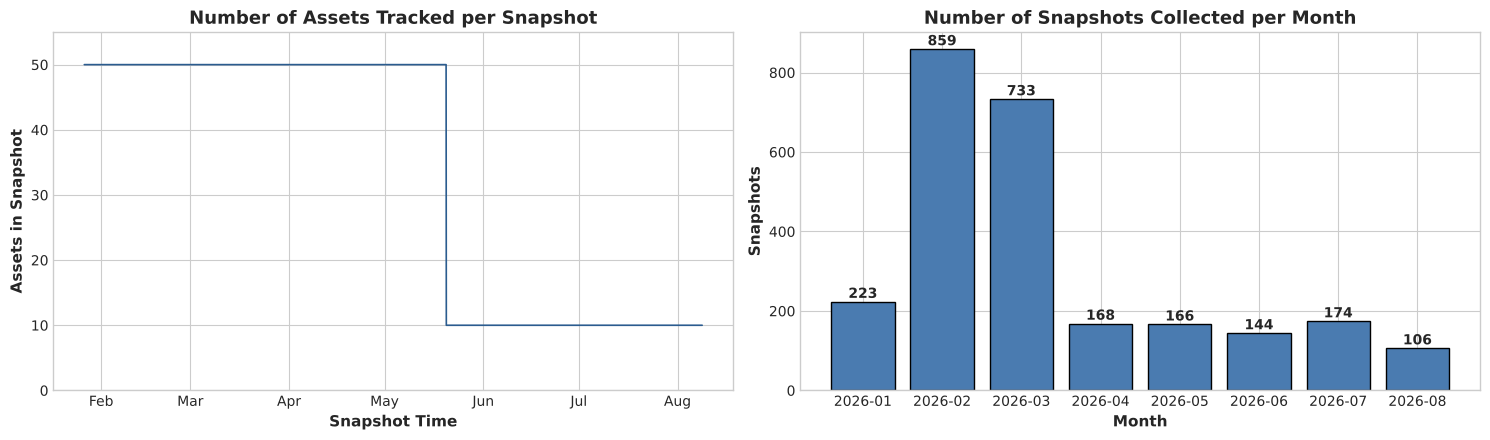

Assets tracked in the 10-asset period: ['BNB', 'Bitcoin', 'Dogecoin', 'Ethereum', 'Figure Heloc', 'Hyperliquid', 'Solana', 'TRON', 'Tether', 'USDC', 'WhiteBIT Coin', 'XRP']


In [7]:
assets_per_ts = df.groupby('timestamp')['name'].nunique()
print("Assets per snapshot – frequency:")
display(assets_per_ts.value_counts().rename_axis('Assets in snapshot').to_frame('Snapshots'))

regime_change = assets_per_ts[assets_per_ts < 50].index.min()
print(f"First snapshot with fewer than 50 assets: {regime_change}")
print(f"Last snapshot with 50 assets: {assets_per_ts[assets_per_ts == 50].index.max()}")

snaps_per_month = df.groupby(df['timestamp'].dt.to_period('M'))['timestamp'].nunique()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(assets_per_ts.index, assets_per_ts.values, color=BLUE, lw=1.2)
axes[0].set_title("Number of Assets Tracked per Snapshot")
axes[0].set_xlabel("Snapshot Time"); axes[0].set_ylabel("Assets in Snapshot")
axes[0].set_ylim(0, 55)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b'))

bars = axes[1].bar(snaps_per_month.index.astype(str), snaps_per_month.values, color=LIGHT, edgecolor='black')
for b in bars:
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+10, f"{int(b.get_height())}", ha='center', fontweight='bold')
axes[1].set_title("Number of Snapshots Collected per Month")
axes[1].set_xlabel("Month"); axes[1].set_ylabel("Snapshots")
plt.tight_layout(); plt.show()

last10 = df[df['timestamp'] > assets_per_ts[assets_per_ts == 50].index.max()]['name'].unique()
print("Assets tracked in the 10-asset period:", sorted(last10))

**Result — two collection regimes:**
* **26 Jan → 20 May 2026 (07:56):** 2,085 snapshots, each with exactly **50 assets** (top 50 by market cap).
* **20 May (09:37) → 08 Aug 2026:** 488 snapshots with only **10 assets** (12 distinct assets appear over this period because membership changed, but never more than 10 at a time).
* Collection was much denser in February (859 snapshots) and March (733) than in April–August (106–174 per month).

**Decision:** market-wide analyses (totals, shares, cross-asset comparisons) use **only the 50-asset period**, otherwise totals would drop artificially on 20 May. Bitcoin is present in every snapshot, so Bitcoin-only analyses use the full period.

### 5.5 Anomaly audit: zero prices, zero volumes, extreme returns

In [8]:
zero_price = df[df['price_usd'] == 0].groupby('name').size().rename('Rows with price = 0')
zero_price = zero_price.to_frame().join(df.groupby('name').size().rename('Total rows'))
zero_price['Max market cap (USD)'] = df[df['name'].isin(zero_price.index)].groupby('name')['market_cap'].max()
print("Assets with price_usd == 0:")
display(zero_price)

zero_vol = df[df['vol_24h'] == 0].groupby('name').size().rename('Rows with vol_24h = 0')
zero_vol = zero_vol.to_frame().join(df.groupby('name').size().rename('Total rows'))
print("Assets with vol_24h == 0:")
display(zero_vol)

print("Most extreme 24h changes:")
display(pd.concat([df.nlargest(4, 'chg_24h'), df.nsmallest(3, 'chg_24h')])[['timestamp','name','price_usd','chg_24h','chg_7d','market_cap']])
print("Most extreme 7d changes:")
display(df.nlargest(3, 'chg_7d')[['timestamp','name','price_usd','chg_24h','chg_7d','market_cap']])
print("Records per asset for the extreme movers:")
display(df[df['name'].isin(['RaveDAO','Siren'])].groupby('name').agg(rows=('timestamp','size'), first=('timestamp','min'), last=('timestamp','max')))

Assets with price_usd == 0:


,Rows with price = 0,Total rows,Max market cap (USD)
name,,,
HTX DAO,315,315,"1,809,278,456.0000"
Pepe,732,732,"2,097,777,009.0000"
Rain,1,2085,"4,900,610,977.0000"
Shiba Inu,2085,2085,"4,636,579,268.0000"


Assets with vol_24h == 0:


,Rows with vol_24h = 0,Total rows
name,,
BlackRock USD Institutional Digital Liquidity Fund,1802,1802


Most extreme 24h changes:


,timestamp,name,price_usd,chg_24h,chg_7d,market_cap
93982,2026-04-13 13:25:23,RaveDAO,9.4200,265.3600,"3,704.9600","2,321,497,767.0000"
85733,2026-03-22 20:49:34,Siren,3.2300,242.3500,447.5700,"2,438,053,574.0000"
94032,2026-04-13 17:27:15,RaveDAO,9.5000,235.8800,"3,698.4800","2,361,370,328.0000"
85683,2026-03-22 20:21:11,Siren,2.9100,210.3300,392.1100,"1,934,327,481.0000"
95532,2026-04-18 20:28:54,RaveDAO,8.3400,-60.0500,293.3900,"2,049,947,556.0000"
92182,2026-04-07 12:57:57,Rain,0.0000,-35.2400,-44.8400,"2,202,849,806.0000"
22775,2026-02-09 04:04:07,MemeCore,1.3000,-30.6300,0.2500,"2,254,981,756.0000"


Most extreme 7d changes:


,timestamp,name,price_usd,chg_24h,chg_7d,market_cap
94482,2026-04-15 06:55:44,RaveDAO,17.2800,84.2400,"6,153.5300","4,274,883,778.0000"
94332,2026-04-14 17:45:56,RaveDAO,15.9200,65.5600,"6,054.0500","3,947,179,246.0000"
94382,2026-04-14 20:57:20,RaveDAO,16.1200,38.5600,"6,037.7400","4,010,290,774.0000"


Records per asset for the extreme movers:


,rows,first,last
name,,,
RaveDAO,33,2026-04-13 10:08:28,2026-04-18 20:28:54
Siren,39,2026-03-22 18:47:32,2026-03-25 17:11:02


**Findings and decisions:**
* **`price_usd = 0`** for every row of Shiba Inu (2,085), Pepe (732) and HTX DAO (315), and for 1 row of Rain. These assets have market caps of about \$1.8–4.9 bn, so they are real assets whose price is below \$0.005 and is **rounded to 0** at 2 decimals. *Decision:* keep the rows, but **never compute returns from `price_usd`**; use `chg_24h` / `chg_7d`, which are stored as percentages and unaffected.
* **`vol_24h = 0`** on all 1,802 rows of the BlackRock USD Institutional Digital Liquidity Fund — it never reports exchange volume. *Decision:* keep it for market-cap analysis; exclude it where log volume is needed (regression).
* **Extreme moves:** RaveDAO (+265.36 % in 24h, +6,153.53 % over 7 days in April) and Siren (+242.35 % in 24h in March). Both appear only briefly (33 and 39 rows) when they entered the top 50, and their prices rise consistently across consecutive snapshots (e.g. RaveDAO \$9.42 → \$17.28), so these look like genuine events, not typing errors. *Decision:* **keep** them (deleting real crashes/spikes would understate crypto risk) and use robust statistics (medians, rank tests, log transforms) where they could dominate.

#### IQR (Tukey) outlier audit
$$\text{IQR}=Q_3-Q_1,\quad \text{Lower}=Q_1-1.5\,\text{IQR},\quad \text{Upper}=Q_3+1.5\,\text{IQR}$$

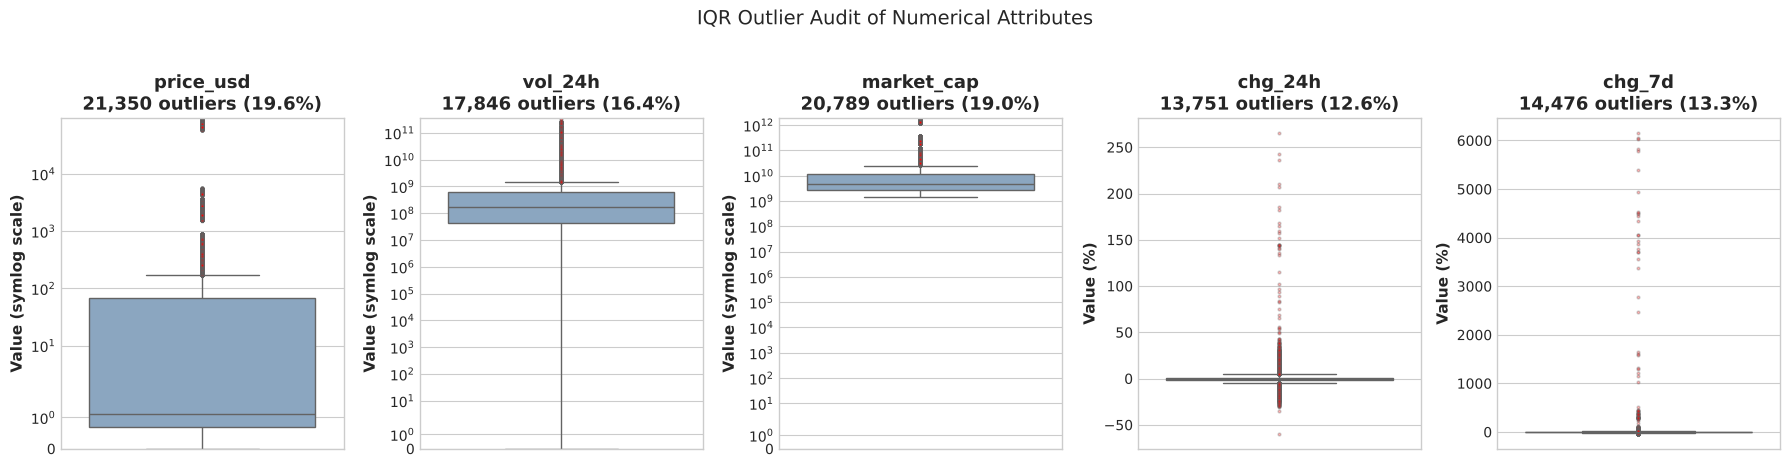

,Variable,Q1,Median,Q3,Lower,Upper,Outliers,Outlier %,Skewness
0,price_usd,0.7100,1.1000,68.9075,-101.5863,171.2038,21350,19.5638,5.6963
1,vol_24h,"42,254,354.0000","173,921,349.5000","594,353,061.5000","-785,893,707.2500","1,422,501,122.7500",17846,16.3530,6.3250
2,market_cap,"2,662,458,858.7500","4,529,303,266.0000","11,618,179,708.2500","-10,771,122,415.5000","25,051,760,982.5000",20789,19.0498,5.9026
3,chg_24h,-1.4700,0.0000,0.9800,-5.1450,4.6550,13751,12.6006,13.0819
4,chg_7d,-4.0200,-0.0100,1.8000,-12.7500,10.5300,14476,13.2649,68.5352


In [9]:
num_cols = ['price_usd', 'vol_24h', 'market_cap', 'chg_24h', 'chg_7d']
rows = []
fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))
for ax, col in zip(axes, num_cols):
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append({'Variable': col, 'Q1': q1, 'Median': df[col].median(), 'Q3': q3, 'Lower': lo, 'Upper': hi,
                 'Outliers': n_out, 'Outlier %': n_out/len(df)*100, 'Skewness': df[col].skew()})
    sns.boxplot(y=df[col], ax=ax, color='#82a6c9', flierprops=dict(marker='o', markersize=2, markerfacecolor='red', alpha=0.3))
    if col in ['price_usd', 'vol_24h', 'market_cap']:
        ax.set_yscale('symlog'); ax.set_ylim(bottom=0)
    ax.set_title(f"{col}\n{n_out:,} outliers ({n_out/len(df)*100:.1f}%)")
    ax.set_ylabel("Value" + (" (symlog scale)" if col in ['price_usd','vol_24h','market_cap'] else " (%)"))
plt.suptitle("IQR Outlier Audit of Numerical Attributes", y=1.03)
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows))

**Interpretation:** the IQR rule flags 12.6–19.6 % of rows in every variable, and all variables are strongly right-skewed (skewness 5.7–68.5). This is not a data-quality problem: the dataset mixes assets whose prices range from \$0.00 to \$90,117 and market caps from \$1.4 bn to \$1.8 tn, and crypto returns are genuinely heavy-tailed. **No rows are removed.** Instead we (1) analyse sizes on a **log scale**, (2) compare assets with **medians and rank-based tests**, and (3) treat extreme returns as signal.

### 5.6 Feature engineering
* **`asset_type`** – data-driven split: an asset is **Stable-value** if its price coefficient of variation (CV = std/mean) over all its snapshots is **below 1 %** *and* its median price is **at least \$0.50**; otherwise **Volatile**. The price floor is needed because prices are rounded to 2 decimals: for a \$0.01 asset the rounded price cannot register a 1 % move, so its CV would be ≈0 even if it is highly volatile. Assets whose rounded price is always 0 are Volatile for the same reason — their `chg_24h` shows they move.
* **`turnover_pct`** = `vol_24h` / `market_cap` × 100 (liquidity relative to size).
* **`log_mcap`, `log_vol`** = log10 transforms (both variables span many orders of magnitude).
* **`abs_chg_24h`, `abs_chg_7d`** – size of the move regardless of direction.
* Calendar features: `date`, `day_of_week`, `is_weekend`.

In [10]:
price_stats = df[df['price_usd'] > 0].groupby('name')['price_usd'].agg(['mean', 'std', 'median'])
price_stats['CV_pct'] = price_stats['std'] / price_stats['mean'] * 100
stable_assets = sorted(price_stats[(price_stats['CV_pct'] < 1) & (price_stats['median'] >= 0.5)].index)
fooled = price_stats[(price_stats['CV_pct'] < 1) & (price_stats['median'] < 0.5)]
print("Low CV only because of 2-decimal rounding (kept as Volatile):")
display(fooled.join(df.groupby('name')['chg_24h'].std().rename('chg_24h SD (%)')))
df['asset_type'] = np.where(df['name'].isin(stable_assets), 'Stable-value', 'Volatile')

print(f"Stable-value assets (price CV < 1%): {len(stable_assets)}")
display(price_stats.loc[stable_assets, ['median', 'CV_pct']].sort_values('CV_pct').rename(columns={'median':'Median price ($)', 'CV_pct':'Price CV (%)'}))
print(f"Volatile assets: {df.loc[df['asset_type']=='Volatile','name'].nunique()}")

df['turnover_pct'] = df['vol_24h'] / df['market_cap'] * 100
df['log_mcap'] = np.log10(df['market_cap'])
df['log_vol'] = np.log10(df['vol_24h'].where(df['vol_24h'] > 0))   # NaN where volume = 0
df['abs_chg_24h'] = df['chg_24h'].abs()
df['abs_chg_7d'] = df['chg_7d'].abs()
df['date'] = df['timestamp'].dt.normalize()
df['day_of_week'] = df['timestamp'].dt.day_name()
df['is_weekend'] = df['timestamp'].dt.dayofweek >= 5
display(df.head())

Low CV only because of 2-decimal rounding (kept as Volatile):


,mean,std,median,CV_pct,chg_24h SD (%)
name,,,,,
Rain,0.0100,0.0000,0.0100,0.0000,3.5941


Stable-value assets (price CV < 1%): 17


,Median price ($),Price CV (%)
name,,
Binance Bridged USDT (BNB Smart Chain),1.0000,0.0000
BlackRock USD Institutional Digital Liquidity Fund,1.0000,0.0000
Global Dollar,1.0000,0.0000
USDS,1.0000,0.0000
USD1,1.0000,0.0000
Tether,1.0000,0.0000
Ripple USD,1.0000,0.0000
PayPal USD,1.0000,0.0000
USDT0,1.0000,0.0000


Volatile assets: 54


,timestamp,name,symbol,price_usd,vol_24h,total_vol,chg_24h,chg_7d,market_cap,asset_type,turnover_pct,log_mcap,log_vol,abs_chg_24h,abs_chg_7d,date,day_of_week,is_weekend
0,2026-01-26 16:54:46,Avalanche,avax,11.7000,"340,079,800.0000",0.1600,-1.9400,-7.9200,"5,047,606,078.0000",Volatile,6.7374,9.7031,8.5316,1.9400,7.9200,2026-01-26,Monday,False
1,2026-01-26 16:54:46,BNB,bnb,872.9300,"1,528,006,211.0000",0.7000,-0.7100,-5.8000,"119,009,919,819.0000",Volatile,1.2839,11.0756,9.1841,0.7100,5.8000,2026-01-26,Monday,False
2,2026-01-26 16:54:46,Binance Bridged USDT (BNB Smart Chain),bsc-usd,1.0000,"1,221,905,587.0000",0.5600,0.0700,-0.0400,"8,975,564,261.0000",Stable-value,13.6137,9.9531,9.0870,0.0700,0.0400,2026-01-26,Monday,False
3,2026-01-26 16:54:46,Bitcoin,btc,"87,888.0000","54,024,532,785.0000",24.8300,-0.9700,-5.5500,"1,756,353,068,441.0000",Volatile,3.0759,12.2446,10.7326,0.9700,5.5500,2026-01-26,Monday,False
4,2026-01-26 16:54:46,Bitcoin Cash,bch,577.3900,"326,376,001.0000",0.1500,-1.4700,-2.0400,"11,540,691,240.0000",Volatile,2.8280,10.0622,8.5137,1.4700,2.0400,2026-01-26,Monday,False


**Result:** 17 assets are classed **Stable-value** (USD stablecoins such as Tether, USDC, Dai, plus yield-bearing dollar tokens such as sUSDS and Circle USYC whose price drifts slowly above \$1) and **54 Volatile**. Rain shows why the price floor is needed: its rounded price is always \$0.01 (CV = 0), yet its 24h change has a standard deviation of 3.59 %.

### 5.7 Building the daily analysis panel (data reduction)

**Why:** `vol_24h` and `chg_24h` are *rolling 24-hour* figures. Two snapshots of the same asset taken one hour apart share 23 hours of data, so the 109k rows are **not independent observations**. Feeding them directly into hypothesis tests would massively overstate the sample size and produce misleadingly tiny p-values. Also, February–March has ~30 snapshots/day while June–August has ~5, so raw rows over-weight some months.

**Rule:** for each calendar day keep the **complete end-of-day snapshot** (all assets at the day's last timestamp), and keep only days whose last snapshot is at or after **18:00**, so that the 24h window mostly belongs to that calendar day (needed for weekday/weekend comparisons). Taking one whole snapshot (rather than each asset's own last row) guarantees every day has a consistent cross-section — assets that drop out of the top 50 during a day do not create a 51st or 52nd row.

**Check:** for Bitcoin, the end-of-day `chg_24h` should closely match the day-over-day change in price.

In [11]:
def end_of_day_panel(frame):
    eod_ts = frame.groupby('date')['timestamp'].max()
    keep_ts = eod_ts[eod_ts.dt.hour >= 18]
    print(f"  calendar days: {len(eod_ts)} | end-of-day snapshot at/after 18:00: {len(keep_ts)} (dropped {len(eod_ts)-len(keep_ts)})")
    return frame[frame['timestamp'].isin(keep_ts.values)].copy()

print("Full period:")
daily = end_of_day_panel(df)

# Panel restricted to the 50-asset coverage period (used for market-wide analysis)
last50 = assets_per_ts[assets_per_ts == 50].index.max()
print("50-asset period:")
daily50 = end_of_day_panel(df[df['timestamp'] <= last50])
assert (daily50.groupby('date')['name'].nunique() == 50).all()

print(f"Full daily panel (all assets, all periods): {daily.shape[0]:,} asset-days, {daily['date'].nunique()} days")
print(f"50-asset daily panel: {daily50.shape[0]:,} asset-days, {daily50['date'].nunique()} days "
      f"({daily50['date'].min().date()} -> {daily50['date'].max().date()})")

# Validation with Bitcoin
btc_d = daily[daily['name'] == 'Bitcoin'].set_index('date').sort_index()
btc_price_ret = btc_d['price_usd'].pct_change() * 100
consecutive = btc_d.index.to_series().diff().dt.days == 1
r = np.corrcoef(btc_price_ret[consecutive], btc_d['chg_24h'][consecutive])[0, 1]
print(f"\nBitcoin: correlation between end-of-day chg_24h and day-over-day price change = {r:.4f} "
      f"(n = {consecutive.sum()} consecutive days)")

Full period:
  calendar days: 190 | end-of-day snapshot at/after 18:00: 183 (dropped 7)
50-asset period:
  calendar days: 113 | end-of-day snapshot at/after 18:00: 108 (dropped 5)
Full daily panel (all assets, all periods): 6,150 asset-days, 183 days
50-asset daily panel: 5,400 asset-days, 108 days (2026-01-26 -> 2026-05-19)

Bitcoin: correlation between end-of-day chg_24h and day-over-day price change = 0.9942 (n = 175 consecutive days)


**Result:** 183 of 190 days (full period) and 108 of 113 days (50-asset period) have an end-of-day snapshot at or after 18:00. The 50-asset panel has exactly 50 assets on every one of its 108 days (5,400 asset-days). For Bitcoin, end-of-day `chg_24h` and the day-over-day price change correlate at **r = 0.9942**, confirming that one end-of-day snapshot per day is a valid daily return series. From here on, statistical work uses `daily` / `daily50`.

## 6. Exploratory Data Analysis (EDA)
### 6.1 Summary statistics of the daily panel

In [12]:
eda_cols = ['price_usd', 'vol_24h', 'market_cap', 'turnover_pct', 'chg_24h', 'chg_7d']
summary = daily50.groupby('asset_type')[eda_cols].describe().T
display(summary)

print("Skewness & kurtosis (Volatile assets, 50-asset panel):")
vol_panel = daily50[daily50['asset_type'] == 'Volatile']
display(pd.DataFrame({'Skewness': vol_panel[eda_cols].skew(), 'Excess kurtosis': vol_panel[eda_cols].kurtosis()}))

asset_type                 Stable-value               Volatile
price_usd    count           1,184.0000             4,216.0000
             mean                1.0125             2,568.4483
             std                 0.0385            12,585.9704
             min                 0.9900                 0.0000
             25%                 1.0000                 0.2100
             50%                 1.0000                 2.0100
             75%                 1.0000               108.8100
             max                 1.2200            89,295.0000
vol_24h      count           1,184.0000             4,216.0000
             mean    7,998,952,166.5850     2,125,335,549.2951
             std    23,407,506,636.2087     8,591,380,717.6424
             min                 0.0000            28,914.0000
             25%         3,398,886.5000        49,127,520.5000
             50%        78,007,526.0000       173,636,709.0000
             75%     1,084,725,361.5000       463,017,440.7500
             max   231,006,250,394.0000   143,616,213,492.0000
market_cap   count           1,184.0000             4,216.0000
             mean   27,414,728,624.5389    55,196,147,399.2284
             std    54,330,561,525.5284   232,915,719,021.7875
             min     1,493,860,302.0000     1,503,186,828.0000
             25%     2,421,193,003.2500     2,588,118,972.5000
             50%     4,297,178,270.5000     4,298,099,271.5000
             75%     9,891,398,987.5000    10,259,069,597.2500
             max   189,842,351,372.0000 1,784,352,903,164.0000
turnover_pct count           1,184.0000             4,216.0000
             mean                9.1631                 5.2201
             std                15.5190                 6.6753
             min                 0.0000                 0.0002
             25%                 0.0895                 1.1893
             50%                 1.9103                 3.1297
             75%                10.6522                 7.0506
             max               124.4878                85.8928
chg_24h      count           1,184.0000             4,216.0000
             mean               -0.0010                 0.1183
             std                 0.0698                 5.6476
             min                -1.0600               -60.0500
             25%                -0.0100                -1.8000
             50%                 0.0000                -0.0800
             75%                 0.0100                 1.5500
             max                 1.0900               181.7900
chg_7d       count           1,184.0000             4,216.0000
             mean                0.0087                 4.8328
             std                 0.0854               141.6029
             min                -1.0600               -37.8700
             25%                -0.0100                -4.2925
             50%                 0.0000                -0.2250
             75%                 0.0300                 3.6200
             max                 0.9900             6,037.7400

Skewness & kurtosis (Volatile assets, 50-asset panel):


,Skewness,Excess kurtosis
price_usd,5.5782,29.6770
vol_24h,6.5415,56.2158
market_cap,5.7523,32.3956
turnover_pct,3.9298,26.3800
chg_24h,11.8495,350.2961
chg_7d,33.7000,"1,213.2721"


### 6.2 Distributions of key variables

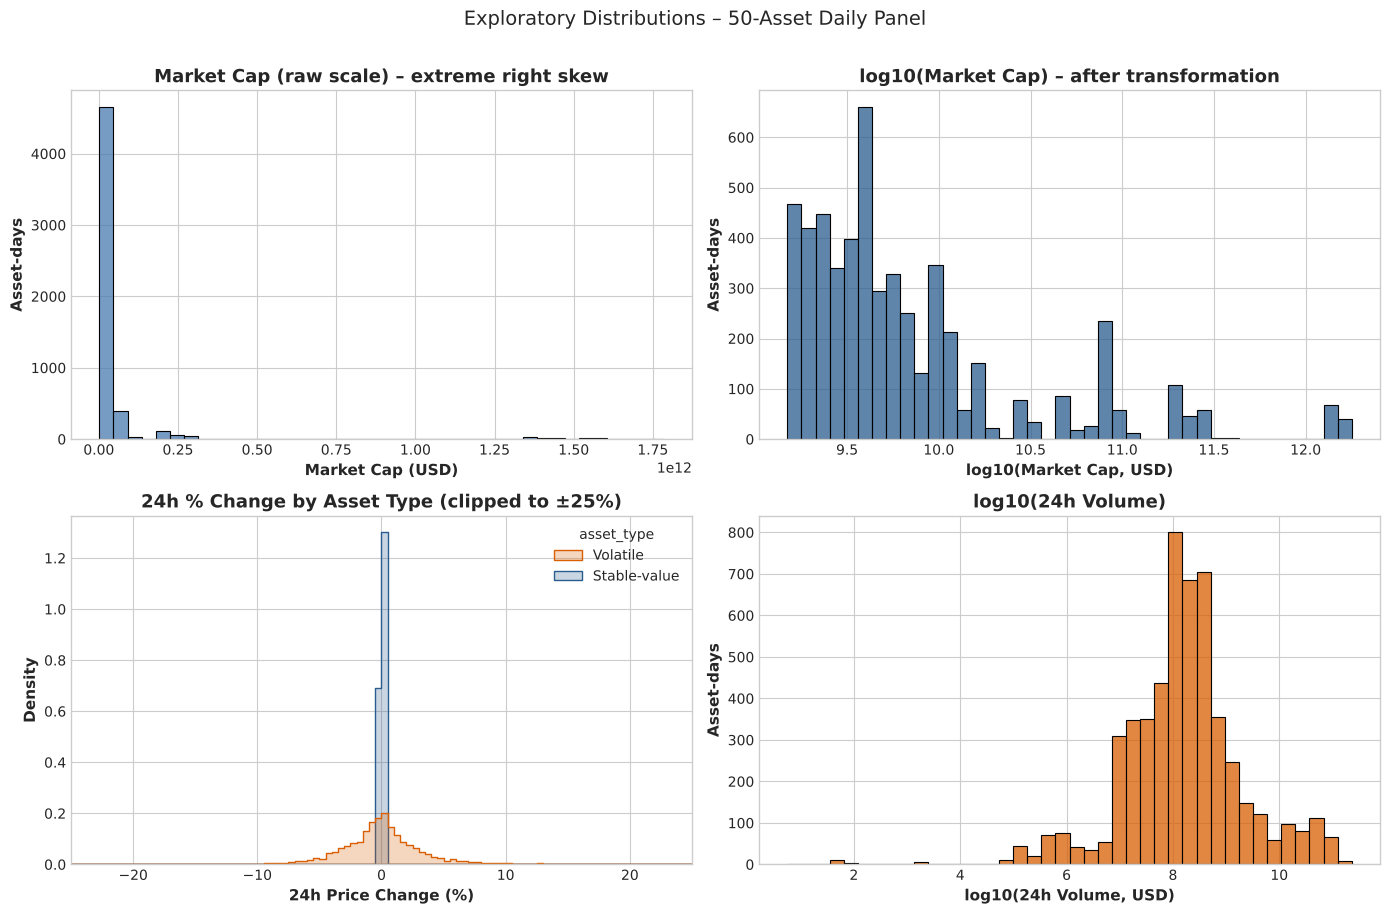

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(daily50['market_cap'], bins=40, ax=axes[0,0], color=LIGHT, edgecolor='black')
axes[0,0].set_title("Market Cap (raw scale) – extreme right skew")
axes[0,0].set_xlabel("Market Cap (USD)"); axes[0,0].set_ylabel("Asset-days")

sns.histplot(daily50['log_mcap'], bins=40, ax=axes[0,1], color=BLUE, edgecolor='black')
axes[0,1].set_title("log10(Market Cap) – after transformation")
axes[0,1].set_xlabel("log10(Market Cap, USD)"); axes[0,1].set_ylabel("Asset-days")

sns.histplot(data=daily50, x='chg_24h', hue='asset_type', palette=PALETTE_TYPE, bins=100, binrange=(-25, 25),
             stat='density', common_norm=False, ax=axes[1,0], element='step')
axes[1,0].set_xlim(-25, 25)
axes[1,0].set_title("24h % Change by Asset Type (clipped to ±25%)")
axes[1,0].set_xlabel("24h Price Change (%)"); axes[1,0].set_ylabel("Density")

sns.histplot(daily50.loc[daily50['vol_24h'] > 0, 'log_vol'], bins=40, ax=axes[1,1], color=ORANGE, edgecolor='black')
axes[1,1].set_title("log10(24h Volume)")
axes[1,1].set_xlabel("log10(24h Volume, USD)"); axes[1,1].set_ylabel("Asset-days")

plt.suptitle("Exploratory Distributions – 50-Asset Daily Panel", y=1.01)
plt.tight_layout(); plt.show()

**Interpretation:**
* Raw market cap is so skewed that almost all assets sit in the first bar; after a log10 transform the distribution is spread out and usable. The same holds for volume, which after log10 is roughly bell-shaped around 10^8 (≈ \$100 m) with a long left tail of thinly traded tokens.
* The 24h change of Stable-value tokens is a spike at 0 (SD 0.07 %), while Volatile tokens are spread out with heavy tails (SD 5.65 %, excess kurtosis 350 in §6.1). This motivates treating the two groups separately.

### 6.3 Correlation matrix of numerical features (Volatile assets)

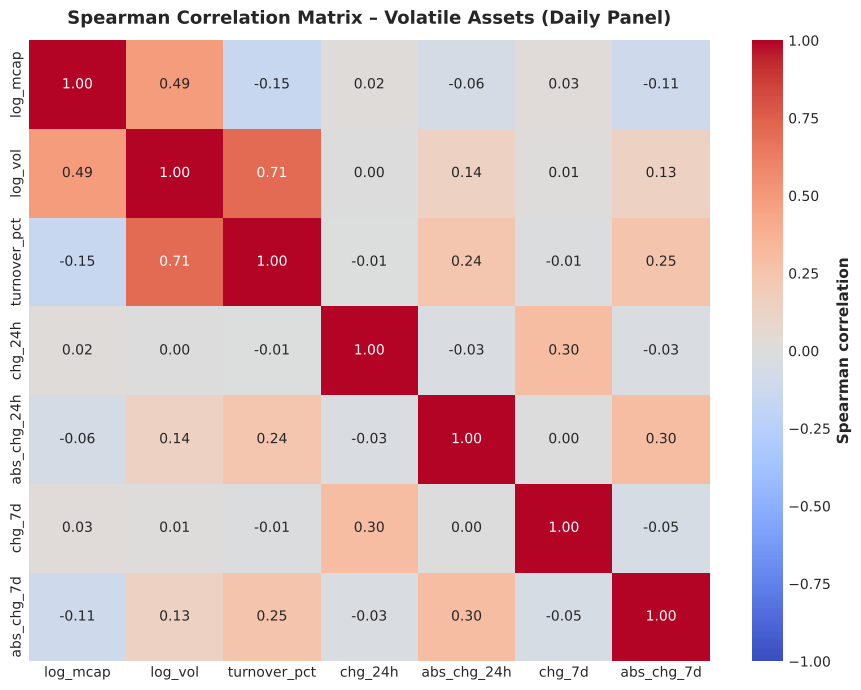

In [14]:
corr_cols = ['log_mcap', 'log_vol', 'turnover_pct', 'chg_24h', 'abs_chg_24h', 'chg_7d', 'abs_chg_7d']
corr_df = vol_panel[corr_cols].corr(method='spearman')

plt.figure(figsize=(9, 7))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            cbar_kws={'label': 'Spearman correlation'})
plt.title("Spearman Correlation Matrix – Volatile Assets (Daily Panel)", pad=12)
plt.tight_layout(); plt.show()

**Interpretation (Spearman, Volatile assets):**
* log volume rises with log market cap (ρ = 0.49) — bigger assets trade more — but **turnover** is slightly *negatively* related to size (ρ = −0.15): smaller assets trade a larger fraction of their value each day.
* Turnover and the size of the daily move are positively related (ρ = 0.24 with |24h change|): **bigger moves come with more trading** (examined formally in Q14 and Test 7).
* Direction does not predict activity: signed `chg_24h` is uncorrelated with volume (ρ = 0.00). The 24h and 7d signed changes correlate at 0.30 because the 7-day window contains the last 24 hours.

### 6.4 Central Limit Theorem (CLT) simulation
24h returns of volatile assets are heavy-tailed. The CLT says the **sample mean** $\bar X_n$ is still approximately $\mathcal N(\mu, \sigma^2/n)$ for large $n$. We draw 2,000 samples for $n \in \{5, 30, 100, 500\}$.

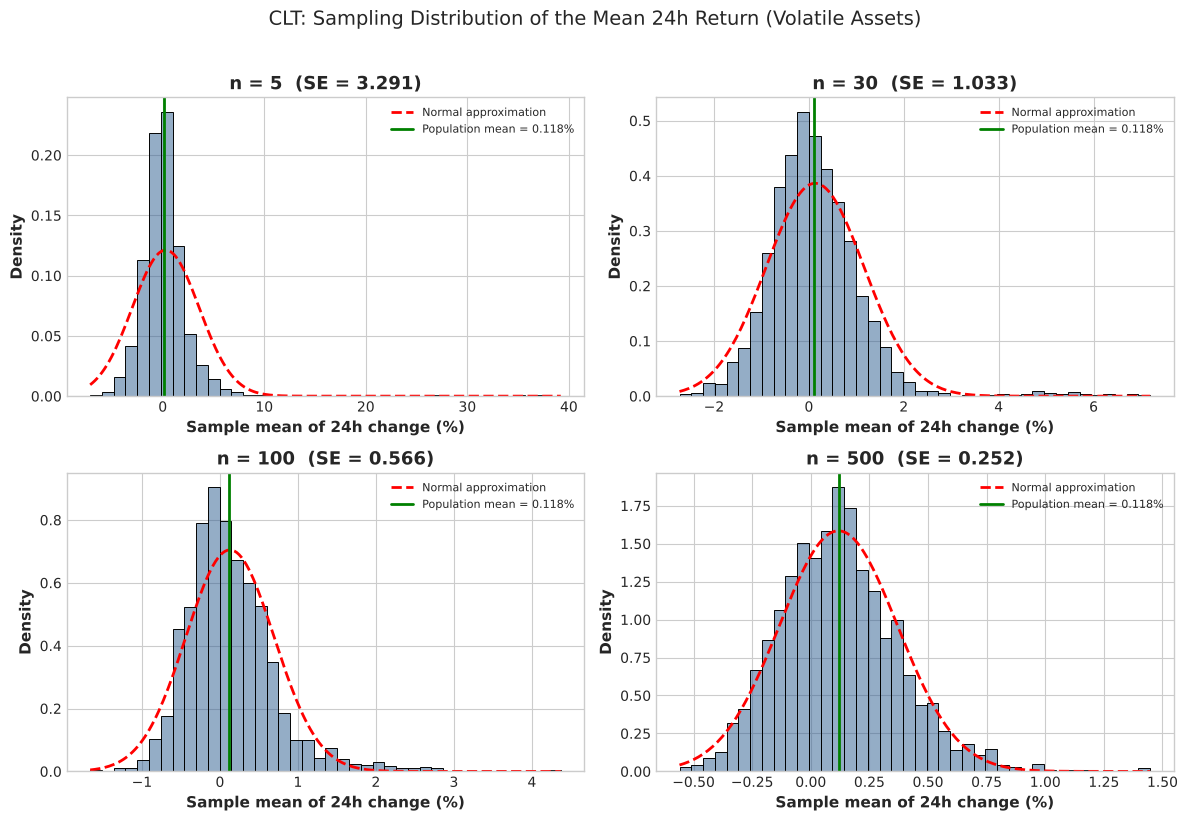

,n,Population mean,Mean of sample means,Empirical SE,Theoretical SE (σ/√n),Skewness of means
0,5,0.1183,0.2939,3.2914,2.5254,6.5216
1,30,0.1183,0.1309,1.0326,1.0310,1.8660
2,100,0.1183,0.1287,0.5661,0.5647,1.2708
3,500,0.1183,0.1180,0.2517,0.2525,0.5300


In [15]:
population = vol_panel['chg_24h'].values
pop_mean, pop_std = population.mean(), population.std()
rng = np.random.default_rng(42)
clt_rows = []
fig, axes = plt.subplots(2, 2, figsize=(12, 8)); axes = axes.flatten()
for ax, n in zip(axes, [5, 30, 100, 500]):
    means = rng.choice(population, size=(2000, n), replace=True).mean(axis=1)
    se_emp, se_th = means.std(ddof=1), pop_std/np.sqrt(n)
    clt_rows.append({'n': n, 'Population mean': pop_mean, 'Mean of sample means': means.mean(),
                     'Empirical SE': se_emp, 'Theoretical SE (σ/√n)': se_th, 'Skewness of means': stats.skew(means)})
    sns.histplot(means, bins=40, stat='density', ax=ax, color=BLUE, alpha=0.5, edgecolor='black')
    xs = np.linspace(means.min(), means.max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, means.mean(), se_emp), 'r--', lw=2, label='Normal approximation')
    ax.axvline(pop_mean, color='green', lw=2, label=f'Population mean = {pop_mean:.3f}%')
    ax.set_title(f"n = {n}  (SE = {se_emp:.3f})")
    ax.set_xlabel("Sample mean of 24h change (%)"); ax.set_ylabel("Density")
    ax.legend(fontsize=8)
plt.suptitle("CLT: Sampling Distribution of the Mean 24h Return (Volatile Assets)", y=1.02)
plt.tight_layout(); plt.show()
display(pd.DataFrame(clt_rows))

**Interpretation:** the empirical standard error closely matches σ/√n for n ≥ 30 (e.g. 0.2517 vs 0.2525 at n = 500), and the sample means centre on the population mean (0.118 %). However, because crypto returns have extreme tails, the sampling distribution is still visibly right-skewed at n = 30 (skewness 1.87) and n = 100 (1.27), and only becomes close to symmetric at n = 500 (0.53). **Lesson:** the CLT holds, but "n ≥ 30" is not enough for very heavy-tailed data — which is why non-parametric and permutation tests are used alongside t-tests in Section 8.

### 6.5 95% confidence interval for Bitcoin's mean daily return
$$\bar x \pm t_{\alpha/2,\,n-1}\frac{s}{\sqrt n}$$ plus a bootstrap percentile interval (no normality assumption).

In [16]:
btc_ret = daily[daily['name'] == 'Bitcoin']['chg_24h']
n_b = len(btc_ret); xbar = btc_ret.mean(); s = btc_ret.std(ddof=1); se = s/np.sqrt(n_b)
t_crit = stats.t.ppf(0.975, n_b - 1)
ci_t = (xbar - t_crit*se, xbar + t_crit*se)
boot = rng.choice(btc_ret.values, size=(10000, n_b), replace=True).mean(axis=1)
ci_boot = tuple(np.percentile(boot, [2.5, 97.5]))
print(f"n = {n_b} days | mean = {xbar:.4f}% | sd = {s:.4f}% | SE = {se:.4f}%")
print(f"95% t-interval:         [{ci_t[0]:.4f}%, {ci_t[1]:.4f}%]")
print(f"95% bootstrap interval: [{ci_boot[0]:.4f}%, {ci_boot[1]:.4f}%]")
print(f"Does the interval contain 0? {ci_t[0] <= 0 <= ci_t[1]}")

n = 183 days | mean = -0.1212% | sd = 2.6838% | SE = 0.1984%
95% t-interval:         [-0.5126%, 0.2702%]
95% bootstrap interval: [-0.5100%, 0.2543%]
Does the interval contain 0? True


**Interpretation:** Bitcoin's average daily return over 183 days was −0.12 %, but the 95 % confidence interval [−0.51 %, +0.27 %] contains 0 (the bootstrap interval agrees). Even though the price fell about 26 % over the period (Q9), daily noise (SD 2.68 %) is large relative to the drift, so the data **cannot** establish a reliable average daily direction. Formal test: Hypothesis Test 4.

## 7. Investigation of the 15 Analysis Questions
Each question follows: **research question → justification → variables → method → code & visualisation → interpretation → implication.**
Unless stated otherwise, the **50-asset daily panel** (`daily50`) is used so that every day contains the same number of assets.

### Q1. How concentrated is total market capitalisation?
* **Justification:** If a few assets hold most of the value, "the crypto market" is effectively those few assets; diversification across many coins gives less diversification than it appears.
* **Variables:** `market_cap`, `name`.
* **Method:** Average daily share of tracked market cap per asset, Pareto (cumulative) chart, Herfindahl-Hirschman Index $HHI=\sum s_i^2$ (shares in %; >2,500 = highly concentrated by the US DoJ convention).

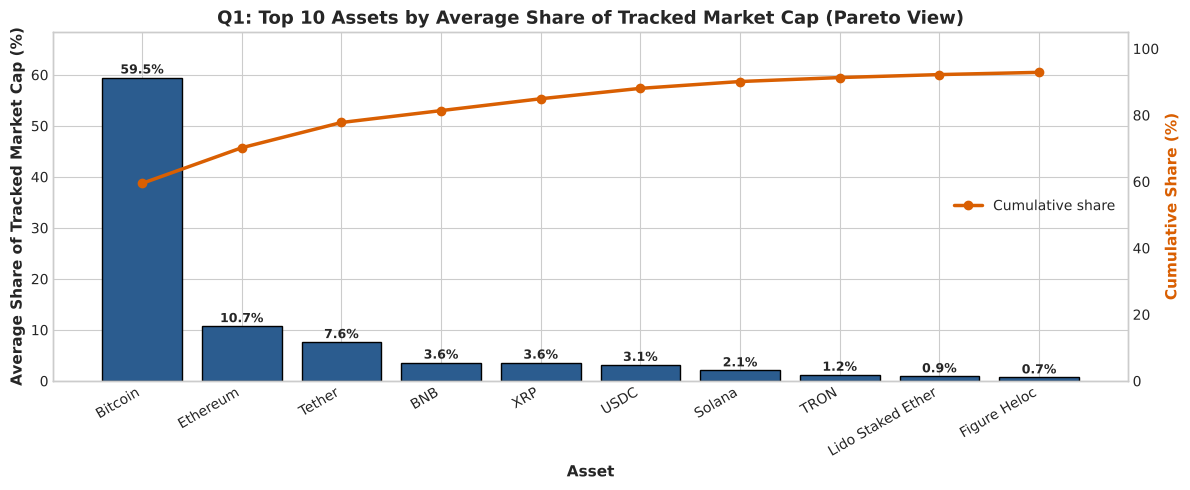

,Avg share (%),Cumulative (%)
name,,
Bitcoin,59.4563,59.4563
Ethereum,10.7252,70.1815
Tether,7.5960,77.7775
BNB,3.5788,81.3563
XRP,3.5707,84.9270
USDC,3.1287,88.0557
Solana,2.0543,90.1100
TRON,1.1945,91.3045
Lido Staked Ether,0.8914,92.1959


Top-1 share: 59.46% | Top-3: 77.78% | Top-5: 84.93% | Top-10: 92.87%
HHI (daily): mean = 3,753, min = 3,578, max = 3,971


In [17]:
daily50['mcap_share'] = daily50['market_cap'] / daily50.groupby('date')['market_cap'].transform('sum') * 100
share = daily50.groupby('name')['mcap_share'].mean().sort_values(ascending=False)
top = share.head(10)
cum = share.cumsum()

fig, ax1 = plt.subplots(figsize=(12, 5))
bars = ax1.bar(top.index, top.values, color=BLUE, edgecolor='black')
for b in bars:
    ax1.text(b.get_x()+b.get_width()/2, b.get_height()+0.8, f"{b.get_height():.1f}%", ha='center', fontweight='bold', fontsize=9)
ax1.set_ylabel("Average Share of Tracked Market Cap (%)")
ax1.set_xlabel("Asset")
ax1.set_ylim(0, top.max()*1.15)
plt.xticks(rotation=30, ha='right')
ax2 = ax1.twinx()
ax2.plot(top.index, cum.head(10).values, color=ORANGE, marker='o', lw=2.5, label='Cumulative share')
ax2.set_ylabel("Cumulative Share (%)", color=ORANGE); ax2.set_ylim(0, 105); ax2.grid(False)
ax2.legend(loc='center right')
plt.title("Q1: Top 10 Assets by Average Share of Tracked Market Cap (Pareto View)")
plt.tight_layout(); plt.show()

hhi = daily50.groupby('date')['mcap_share'].apply(lambda s: (s**2).sum())
q1_table = pd.DataFrame({'Avg share (%)': top, 'Cumulative (%)': cum.head(10)})
display(q1_table)
print(f"Top-1 share: {cum.iloc[0]:.2f}% | Top-3: {cum.iloc[2]:.2f}% | Top-5: {cum.iloc[4]:.2f}% | Top-10: {cum.iloc[9]:.2f}%")
print(f"HHI (daily): mean = {hhi.mean():,.0f}, min = {hhi.min():,.0f}, max = {hhi.max():,.0f}")

* **Interpretation:**
  - **Bitcoin alone averages 59.46 %** of the tracked market cap; the top 3 (Bitcoin, Ethereum, Tether) hold 77.78 %, the top 5 hold 84.93 %, and the top 10 hold **92.87 %**. The remaining 40 assets share about 7 %.
  - The daily HHI averages **3,753** (range 3,578–3,971), well above the 2,500 threshold conventionally used for a "highly concentrated" market.
* **Implication:** a "top-50 basket" is in practice mostly a Bitcoin position. Any market-wide index, risk limit or diversification claim must account for this concentration.

### Q2. How did Bitcoin's dominance evolve?
* **Justification:** Bitcoin dominance is a standard market-regime indicator: rising dominance usually signals a flight to the largest asset.
* **Variables:** `market_cap` (Bitcoin and total), `date`, Bitcoin `price_usd`.
* **Method:** Daily Bitcoin share of tracked market cap (50-asset period), plotted with Bitcoin's price; Spearman correlation between the two series.

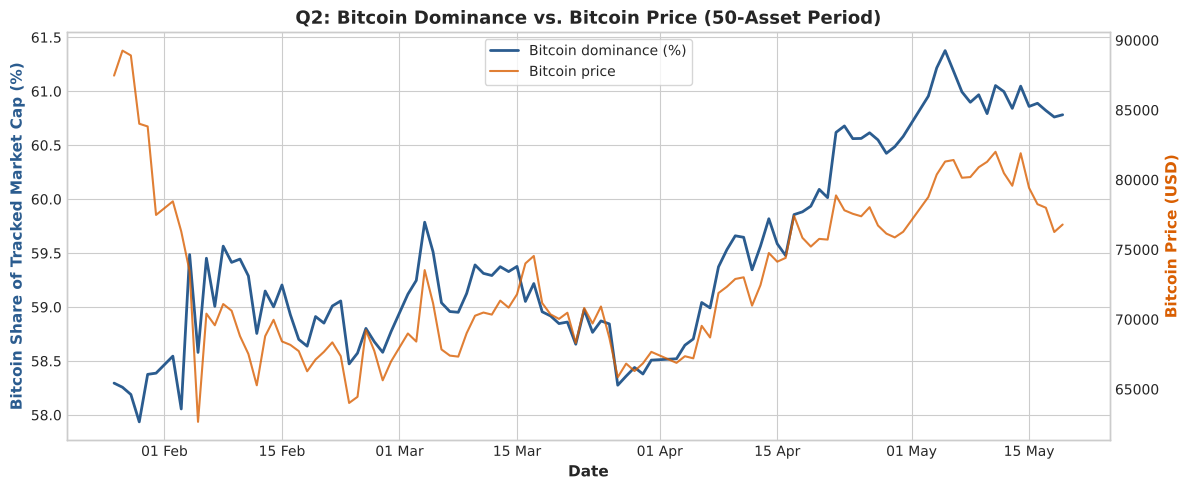

,count,mean,std,min,25%,50%,75%,max
BTC dominance (%),108.0000,59.4563,0.8912,57.9357,58.7946,59.2674,60.0330,61.3766


First day: 58.29% | Last day: 60.78%
Spearman rho(dominance, BTC price) = 0.597 (p = 8.925e-12)


In [18]:
btc_dom = daily50[daily50['name'] == 'Bitcoin'].set_index('date')[['mcap_share', 'price_usd']].sort_index()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(btc_dom.index, btc_dom['mcap_share'], color=BLUE, lw=2, label='Bitcoin dominance (%)')
ax1.set_ylabel("Bitcoin Share of Tracked Market Cap (%)", color=BLUE)
ax1.set_xlabel("Date")
ax2 = ax1.twinx()
ax2.plot(btc_dom.index, btc_dom['price_usd'], color=ORANGE, lw=1.5, alpha=0.8, label='Bitcoin price')
ax2.set_ylabel("Bitcoin Price (USD)", color=ORANGE); ax2.grid(False)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], loc='upper center', frameon=True)
plt.title("Q2: Bitcoin Dominance vs. Bitcoin Price (50-Asset Period)")
plt.tight_layout(); plt.show()

rho, p = stats.spearmanr(btc_dom['mcap_share'], btc_dom['price_usd'])
display(btc_dom['mcap_share'].describe().to_frame('BTC dominance (%)').T)
print(f"First day: {btc_dom['mcap_share'].iloc[0]:.2f}% | Last day: {btc_dom['mcap_share'].iloc[-1]:.2f}%")
print(f"Spearman rho(dominance, BTC price) = {rho:.3f} (p = {p:.3e})")

* **Interpretation:**
  - Bitcoin dominance stayed in a narrow band of **57.94 %–61.38 %** (mean 59.46 %) and ended the 50-asset period higher than it started (58.29 % → 60.78 %), with most of the rise occurring from April onwards.
  - Dominance and Bitcoin's price are positively related (**Spearman ρ = 0.597**, p ≈ 9 × 10⁻¹²): on days Bitcoin was priced higher, it also held a larger share of the market — i.e. the other assets did not keep pace with Bitcoin's recovery in April–May.
* **Implication:** in this period, rallies were Bitcoin-led; holding smaller assets did not add upside during Bitcoin's recovery. (Correlation over time does not establish cause.)

### Q3. Is trading volume concentrated in the same assets that dominate market cap?
* **Justification:** Market cap measures *value held*; volume measures *activity*. If they differ, the assets people hold are not the ones they trade.
* **Variables:** `total_vol` (volume share), `mcap_share`.
* **Method:** Average volume share vs. market-cap share per asset; log-log scatter with the 45° line (points above the line trade more than their size suggests).

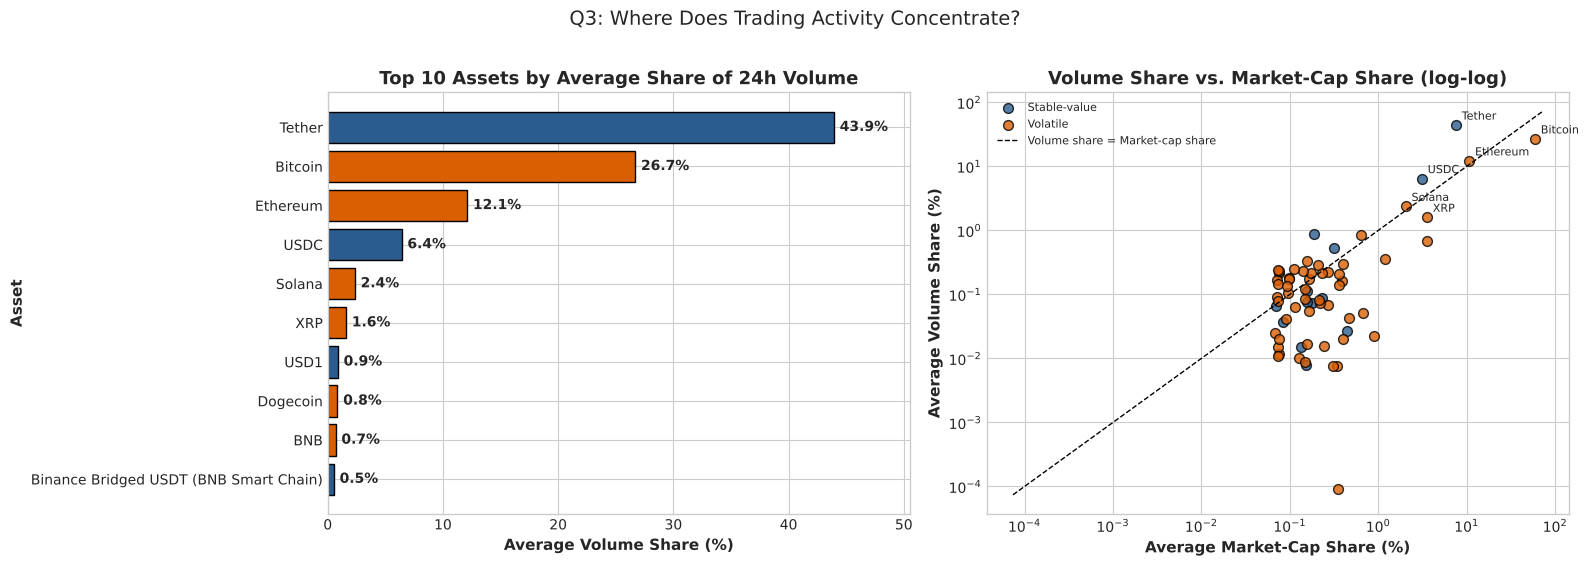

,name,asset_type,vol_share,mcap_share,vol_to_mcap_share_ratio
53,Tether,Stable-value,43.9430,7.5960,5.7850
5,Bitcoin,Volatile,26.6920,59.4560,0.4490
20,Ethereum,Volatile,12.1070,10.7250,1.1290
57,USDC,Stable-value,6.4150,3.1290,2.0500
49,Solana,Volatile,2.3570,2.0540,1.1470
68,XRP,Volatile,1.5930,3.5710,0.4460
56,USD1,Stable-value,0.8800,0.1890,4.6430
17,Dogecoin,Volatile,0.8420,0.6430,1.3090
3,BNB,Volatile,0.6890,3.5790,0.1930
4,Binance Bridged USDT (BNB Smart Chain),Stable-value,0.5320,0.3150,1.6880


Combined volume share of top 3 assets by volume: 82.74%


In [19]:
q3 = daily50.groupby(['name', 'asset_type']).agg(vol_share=('total_vol', 'mean'), mcap_share=('mcap_share', 'mean')).reset_index()
q3['vol_to_mcap_share_ratio'] = q3['vol_share'] / q3['mcap_share']

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
top_v = q3.sort_values('vol_share', ascending=False).head(10)
bars = axes[0].barh(top_v['name'][::-1], top_v['vol_share'][::-1],
                    color=[PALETTE_TYPE[t] for t in top_v['asset_type'][::-1]], edgecolor='black')
for b in bars:
    axes[0].text(b.get_width()+0.5, b.get_y()+b.get_height()/2, f"{b.get_width():.1f}%", va='center', fontweight='bold')
axes[0].set_title("Top 10 Assets by Average Share of 24h Volume")
axes[0].set_xlabel("Average Volume Share (%)"); axes[0].set_ylabel("Asset")
axes[0].set_xlim(0, top_v['vol_share'].max()*1.15)

pos = q3[q3['vol_share'] > 0]
for t, g in pos.groupby('asset_type'):
    axes[1].scatter(g['mcap_share'], g['vol_share'], color=PALETTE_TYPE[t], s=50, edgecolor='black', label=t, alpha=0.8)
lims = [pos[['mcap_share','vol_share']].min().min()*0.8, pos[['mcap_share','vol_share']].max().max()*1.2]
axes[1].plot(lims, lims, 'k--', lw=1, label='Volume share = Market-cap share')
for _, r_ in pos.nlargest(6, 'vol_share').iterrows():
    axes[1].annotate(r_['name'], (r_['mcap_share'], r_['vol_share']), fontsize=8, xytext=(4, 4), textcoords='offset points')
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_title("Volume Share vs. Market-Cap Share (log-log)")
axes[1].set_xlabel("Average Market-Cap Share (%)"); axes[1].set_ylabel("Average Volume Share (%)")
axes[1].legend(fontsize=8)
plt.suptitle("Q3: Where Does Trading Activity Concentrate?", y=1.02)
plt.tight_layout(); plt.show()

display(q3.sort_values('vol_share', ascending=False).head(10).round(3))
print("Combined volume share of top 3 assets by volume: "
      f"{q3.sort_values('vol_share', ascending=False)['vol_share'].head(3).sum():.2f}%")

* **Interpretation:**
  - **Tether** accounts for **43.94 %** of all 24h volume while holding only 7.60 % of market cap (5.8× its size share). USDC (6.42 % volume vs 3.13 % cap) and USD1 (4.6×) show the same pattern: **stablecoins are the medium of exchange** — most trades are quoted against them.
  - **Bitcoin** has 59.46 % of market cap but only **26.69 %** of volume (0.45×); BNB is even lower (0.19×). These assets are held more than traded.
  - The top 3 assets by volume (Tether, Bitcoin, Ethereum) carry **82.74 %** of all trading activity.
* **Implication:** market-cap rankings and volume rankings tell different stories; liquidity analysis should use volume, not size.

### Q4. How liquid are assets relative to their size (turnover)?
* **Justification:** Turnover = volume ÷ market cap tells how much of an asset changes hands per day. Low turnover means large orders move the price; very high turnover can signal speculation.
* **Variables:** `turnover_pct`, `asset_type`, `name`.
* **Method:** Median daily turnover per asset (median is robust to spikes); top/bottom 10 ranking; comparison by asset type.

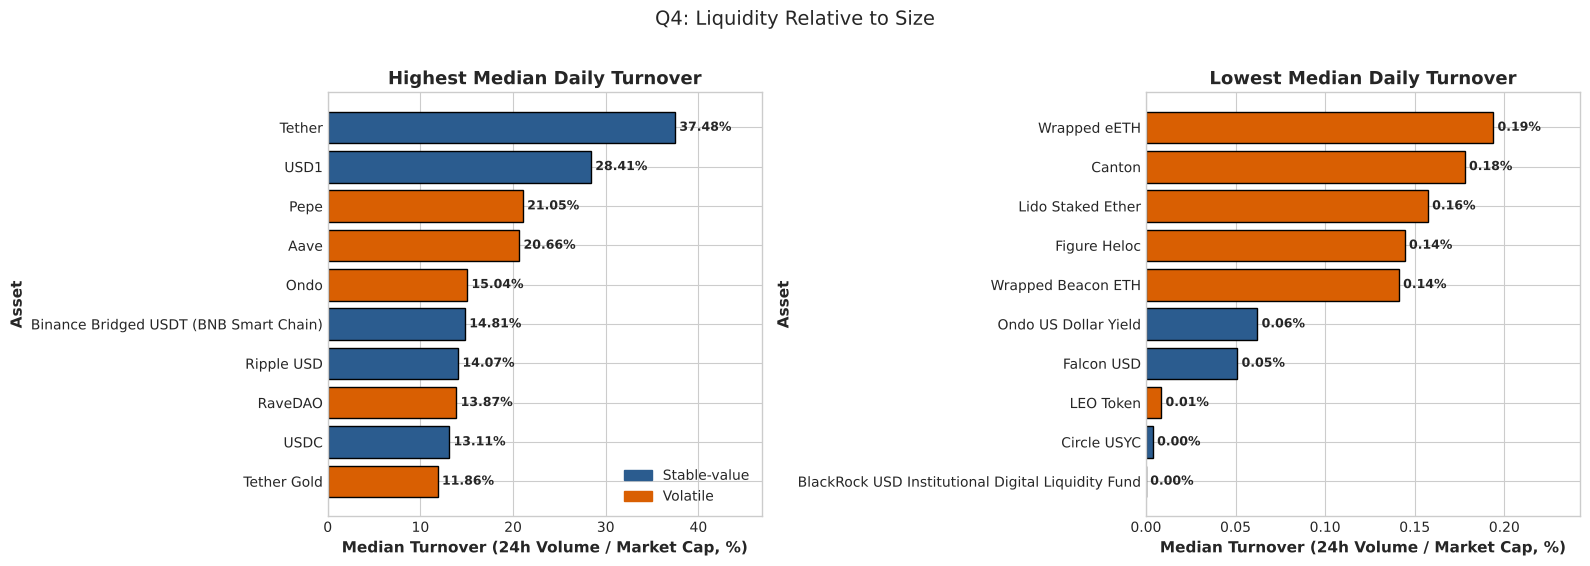

,count,mean,std,min,25%,50%,75%,max
asset_type,,,,,,,,
Stable-value,17.0000,7.3704,11.0367,0.0000,0.2267,2.0083,13.1052,37.4789
Volatile,54.0000,4.9405,5.0237,0.0085,1.0996,3.1100,7.8142,21.0540


,name,asset_type,turnover_pct
53,Tether,Stable-value,37.4789
56,USD1,Stable-value,28.4072
40,Pepe,Volatile,21.0540
0,Aave,Volatile,20.6638
36,Ondo,Volatile,15.0426
4,Binance Bridged USDT (BNB Smart Chain),Stable-value,14.8087
45,Ripple USD,Stable-value,14.0742
44,RaveDAO,Volatile,13.8738
57,USDC,Stable-value,13.1052
54,Tether Gold,Volatile,11.8617


In [20]:
turn = daily50.groupby(['name', 'asset_type'])['turnover_pct'].median().reset_index().sort_values('turnover_pct', ascending=False)
top_t, bot_t = turn.head(10), turn.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, d_, title in [(axes[0], top_t, "Highest Median Daily Turnover"), (axes[1], bot_t, "Lowest Median Daily Turnover")]:
    bars = ax.barh(d_['name'][::-1], d_['turnover_pct'][::-1], color=[PALETTE_TYPE[t] for t in d_['asset_type'][::-1]], edgecolor='black')
    for b in bars:
        ax.text(b.get_width(), b.get_y()+b.get_height()/2, f" {b.get_width():.2f}%", va='center', fontweight='bold', fontsize=9)
    ax.set_title(title); ax.set_xlabel("Median Turnover (24h Volume / Market Cap, %)"); ax.set_ylabel("Asset")
    ax.set_xlim(0, max(d_['turnover_pct'].max()*1.25, 0.1))
handles = [plt.Rectangle((0,0),1,1,color=c) for c in PALETTE_TYPE.values()]
axes[0].legend(handles, PALETTE_TYPE.keys(), loc='lower right')
plt.suptitle("Q4: Liquidity Relative to Size", y=1.02)
plt.tight_layout(); plt.show()

display(turn.groupby('asset_type')['turnover_pct'].describe())
display(pd.concat([top_t, bot_t]).round(4))

* **Interpretation:**
  - Highest median daily turnover: **Tether 37.48 %**, USD1 28.41 %, Pepe 21.05 %, Aave 20.66 % — roughly a fifth to a third of their value changes hands every day.
  - Lowest: BlackRock BUIDL (0, no exchange volume), **Circle USYC 0.0038 %**, LEO Token 0.0085 %, Falcon USD 0.05 %, Ondo US Dollar Yield 0.06 %, and the wrapped/staked ETH tokens (0.14–0.19 %).
  - The Stable-value group is **split in two**: trading stablecoins (Tether, USDC, USD1) are the most liquid assets in the dataset, while yield-bearing/institutional dollar tokens (USYC, BUIDL, Falcon, Ondo USDY) barely trade. Hence the group's mean turnover (7.37 %) is far above its median (2.01 %).
* **Implication:** "stablecoin" is not a single liquidity class. Assets with turnover far below 1 % would be expensive to exit in size.

### Q5. What does the distribution of daily returns look like?
* **Justification:** Most textbook risk models assume normal returns. If returns have fat tails, extreme moves happen far more often than such models predict.
* **Variables:** `chg_24h` of Volatile assets and of Bitcoin.
* **Method:** Histogram with fitted normal curve, Q-Q plot, skewness, excess kurtosis, and the observed vs. normal-expected frequency of moves beyond ±3σ.

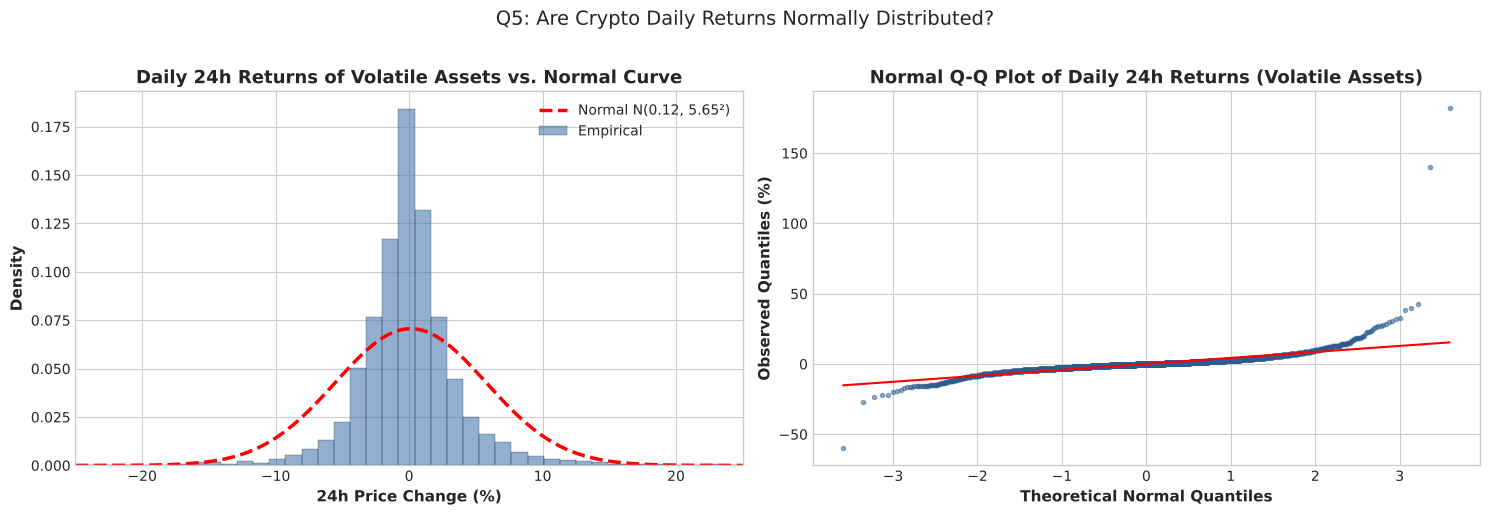

,Sample,n,Mean (%),Std (%),Skewness,Excess kurtosis,Min (%),Max (%)
0,All volatile assets,4216,0.1183,5.6476,11.8495,350.2961,-60.0500,181.7900
1,Bitcoin only,183,-0.1212,2.6838,-0.2281,7.0710,-14.6600,12.6400


Observed share of days beyond ±3σ: 0.93% vs. 0.27% expected under normality (≈3.4× more often)


In [21]:
x = vol_panel['chg_24h']; mu, sd = x.mean(), x.std()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(x, bins=200, stat='density', ax=axes[0], color=LIGHT, alpha=0.6, label='Empirical')
xs = np.linspace(-25, 25, 400)
axes[0].plot(xs, stats.norm.pdf(xs, mu, sd), 'r--', lw=2.5, label=f'Normal N({mu:.2f}, {sd:.2f}²)')
axes[0].set_xlim(-25, 25)
axes[0].set_title("Daily 24h Returns of Volatile Assets vs. Normal Curve")
axes[0].set_xlabel("24h Price Change (%)"); axes[0].set_ylabel("Density"); axes[0].legend()

stats.probplot(x, dist='norm', plot=axes[1])
axes[1].get_lines()[0].set(markersize=3, alpha=0.5, color=BLUE)
axes[1].set_title("Normal Q-Q Plot of Daily 24h Returns (Volatile Assets)")
axes[1].set_xlabel("Theoretical Normal Quantiles"); axes[1].set_ylabel("Observed Quantiles (%)")
plt.suptitle("Q5: Are Crypto Daily Returns Normally Distributed?", y=1.02)
plt.tight_layout(); plt.show()

beyond3 = (np.abs(x - mu) > 3*sd).mean()*100
expected3 = 2*(1 - stats.norm.cdf(3))*100
q5 = pd.DataFrame({
    'Sample': ['All volatile assets', 'Bitcoin only'],
    'n': [len(x), len(btc_ret)],
    'Mean (%)': [mu, btc_ret.mean()],
    'Std (%)': [sd, btc_ret.std()],
    'Skewness': [x.skew(), btc_ret.skew()],
    'Excess kurtosis': [x.kurtosis(), btc_ret.kurtosis()],
    'Min (%)': [x.min(), btc_ret.min()], 'Max (%)': [x.max(), btc_ret.max()]})
display(q5)
print(f"Observed share of days beyond ±3σ: {beyond3:.2f}% vs. {expected3:.2f}% expected under normality "
      f"(≈{beyond3/expected3:.1f}× more often)")

* **Interpretation:**
  - Daily returns of Volatile assets are **sharply peaked with very fat tails**: excess kurtosis 350 (a normal distribution has 0), min −60.05 %, max +181.79 %. The Q-Q plot bends away from the line at both ends.
  - Moves beyond ±3σ occur on **0.93 %** of asset-days versus 0.27 % expected under normality — about **3.4× more often**.
  - Even Bitcoin alone, the most mature asset, has excess kurtosis 7.07 (min −14.66 %, max +12.64 %).
* **Implication:** risk measures that assume normality (e.g. "a 3σ day happens once a year") understate crypto tail risk. Formal test: Hypothesis Test 3.

### Q6. Which assets are the most and least volatile?
* **Justification:** Volatility (standard deviation of daily returns) is the basic measure of risk used for position sizing.
* **Variables:** `chg_24h` per asset.
* **Method:** Standard deviation of end-of-day 24h returns per Volatile asset, restricted to assets with **≥ 30 daily observations** (short-lived assets give unreliable estimates); annualised volatility = daily σ × √365 (crypto trades every day).

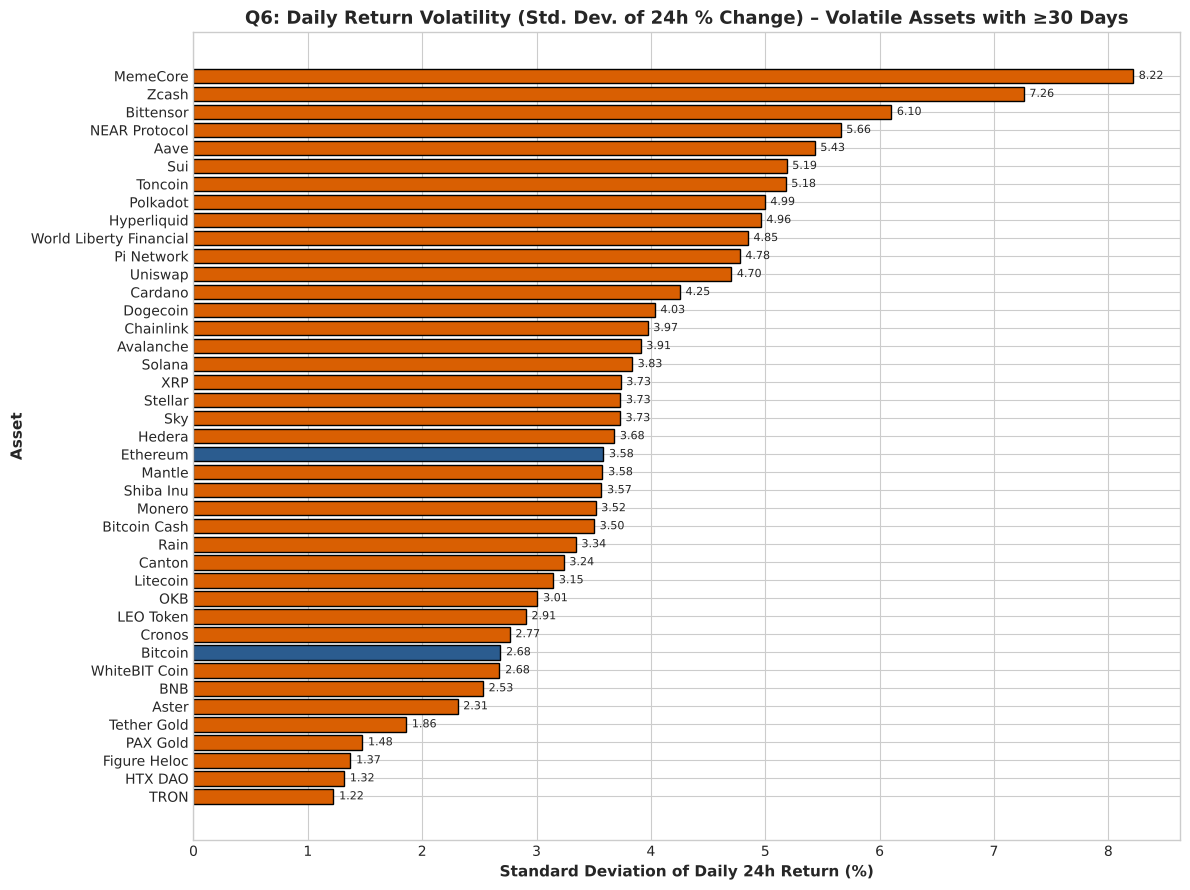

Excluded (fewer than 30 daily observations): ['Bitget Token', 'Coinbase Wrapped BTC', 'Internet Computer', 'Lido Staked Ether', 'Ondo', 'Pepe', 'RaveDAO', 'Siren', 'WETH', 'Wrapped Beacon ETH', 'Wrapped Bitcoin', 'Wrapped eETH', 'Wrapped stETH']


,days,daily_sd,mean_ret,annualised_vol_%
name,,,,
MemeCore,107,8.2160,1.0072,156.9661
Zcash,108,7.2599,0.7354,138.6996
Bittensor,97,6.1007,0.4925,116.5547
NEAR Protocol,59,5.6582,1.3537,108.0996
Aave,46,5.4315,-0.1004,103.7679
Sui,108,5.1861,-0.1060,99.0799
Toncoin,108,5.1774,0.4056,98.9145
Polkadot,108,4.9944,-0.1412,95.4169


,days,daily_sd,mean_ret,annualised_vol_%
name,,,,
WhiteBIT Coin,116,2.6755,0.0696,51.1153
BNB,183,2.5310,-0.1383,48.3539
Aster,68,2.3090,0.2416,44.1136
Tether Gold,108,1.8599,-0.1151,35.5324
PAX Gold,100,1.4765,-0.1014,28.2078
Figure Heloc,183,1.3721,0.1429,26.2147
HTX DAO,30,1.3177,0.1397,25.1738
TRON,183,1.2238,0.0564,23.3801


In [22]:
vol_by_asset = (daily[daily['asset_type'] == 'Volatile']
                .groupby('name')['chg_24h'].agg(days='count', daily_sd='std', mean_ret='mean'))
excluded = vol_by_asset[vol_by_asset['days'] < 30]
vol_by_asset = vol_by_asset[vol_by_asset['days'] >= 30].sort_values('daily_sd', ascending=False)
vol_by_asset['annualised_vol_%'] = vol_by_asset['daily_sd'] * np.sqrt(365)

plt.figure(figsize=(12, 9))
colors = [ORANGE if n_ not in ['Bitcoin', 'Ethereum'] else BLUE for n_ in vol_by_asset.index]
bars = plt.barh(vol_by_asset.index[::-1], vol_by_asset['daily_sd'][::-1], color=colors[::-1], edgecolor='black')
for b in bars:
    plt.text(b.get_width()+0.05, b.get_y()+b.get_height()/2, f"{b.get_width():.2f}", va='center', fontsize=8)
plt.title("Q6: Daily Return Volatility (Std. Dev. of 24h % Change) – Volatile Assets with ≥30 Days")
plt.xlabel("Standard Deviation of Daily 24h Return (%)"); plt.ylabel("Asset")
plt.tight_layout(); plt.show()

print("Excluded (fewer than 30 daily observations):", excluded.index.tolist())
display(vol_by_asset.head(8)); display(vol_by_asset.tail(8))

* **Interpretation:**
  - Most volatile (daily SD): **MemeCore 8.22 %** (≈157 % annualised), Zcash 7.26 %, Bittensor 6.10 %, NEAR Protocol 5.66 %, Aave 5.43 %.
  - Least volatile among Volatile assets: **TRON 1.22 %**, HTX DAO 1.32 %, Figure Heloc 1.37 %, PAX Gold 1.48 %, Tether Gold 1.86 % — the gold-backed tokens track gold rather than crypto.
  - Bitcoin's daily SD is 2.68 % (≈51 % annualised) and Ethereum's 3.58 %.
  - 13 assets were excluded for having fewer than 30 daily observations (e.g. RaveDAO, Siren, and the wrapped BTC/ETH tokens that left the list in early February).
* **Implication:** the riskiest assets have roughly 3× Bitcoin's daily volatility; equal-sized positions across assets would therefore carry very unequal risk.

### Q7. How different is the volatility of Stable-value vs. Volatile tokens? *(A/B comparison)*
* **Justification:** Stable-value tokens are used as the "cash" leg of crypto trading. Quantifying how stable they really are versus volatile tokens is the basis for treating them as low-risk collateral.
* **Variables:** `abs_chg_24h`, `asset_type`.
* **Method:** Group A = Stable-value, Group B = Volatile. Compare the distribution of daily |24h change| (box plot, log scale) and per-asset mean |change|. Formal test in **Hypothesis Test 2**.

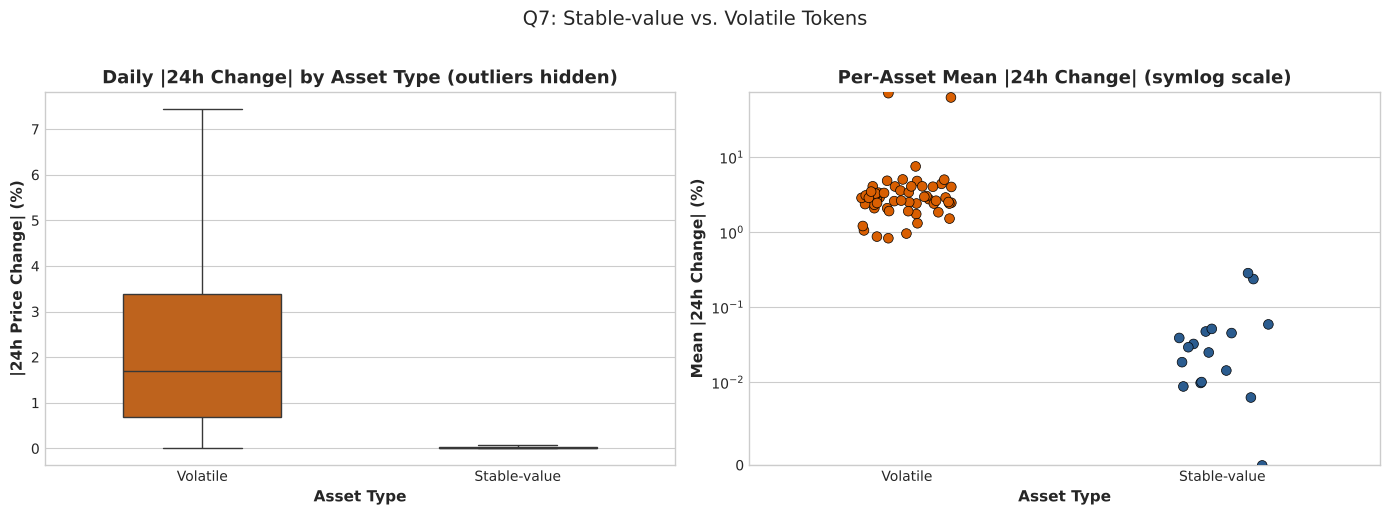

,count,mean,std,min,25%,50%,75%,max
asset_type,,,,,,,,
Stable-value,"1,184.0000",0.0262,0.0648,0.0000,0.0000,0.0100,0.0300,1.0900
Volatile,"4,216.0000",2.7579,4.9297,0.0000,0.6800,1.6900,3.3900,181.7900


,count,mean,std,min,25%,50%,75%,max
asset_type,,,,,,,,
Stable-value,17.0000,0.0539,0.0798,0.0000,0.0100,0.0292,0.0472,0.2833
Volatile,54.0000,5.2692,12.2534,0.8277,2.3246,2.8052,3.8904,71.1050


In [23]:
q7_asset = daily50.groupby(['name', 'asset_type'])['abs_chg_24h'].mean().reset_index(name='mean_abs_chg')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=daily50, x='asset_type', y='abs_chg_24h', palette=PALETTE_TYPE, ax=axes[0], showfliers=False, width=0.5)
axes[0].set_title("Daily |24h Change| by Asset Type (outliers hidden)")
axes[0].set_xlabel("Asset Type"); axes[0].set_ylabel("|24h Price Change| (%)")

sns.stripplot(data=q7_asset, x='asset_type', y='mean_abs_chg', palette=PALETTE_TYPE, ax=axes[1], size=7, jitter=0.15, edgecolor='black', linewidth=0.5)
axes[1].set_yscale('symlog', linthresh=0.01); axes[1].set_ylim(bottom=0)
axes[1].set_title("Per-Asset Mean |24h Change| (symlog scale)")
axes[1].set_xlabel("Asset Type"); axes[1].set_ylabel("Mean |24h Change| (%)")
plt.suptitle("Q7: Stable-value vs. Volatile Tokens", y=1.02)
plt.tight_layout(); plt.show()

display(daily50.groupby('asset_type')['abs_chg_24h'].describe())
display(q7_asset.groupby('asset_type')['mean_abs_chg'].describe())

* **Interpretation:**
  - Stable-value tokens: median daily |24h change| **0.01 %**, largest single move 1.09 %.
  - Volatile tokens: median **1.69 %**, mean 2.76 %, largest 181.79 %.
  - Per asset, the most volatile Stable-value token (mean |change| 0.28 %) is still calmer than the *least* volatile Volatile token (0.83 %): **the two groups do not overlap at all**.
* **Implication:** the data-driven split is clean and stable-value tokens behave as near-cash. Formal A/B test: Hypothesis Test 2.

### Q8. Are larger assets less volatile?
* **Justification:** A common belief is that bigger assets are "safer". If true, size can be used as a simple risk filter.
* **Variables:** `market_cap`, `chg_24h` (Volatile assets only — stable tokens would trivially distort the relationship).
* **Method:** Per-asset median market cap vs. per-asset daily return SD (assets with ≥30 days); Spearman rank correlation; size-quartile comparison.

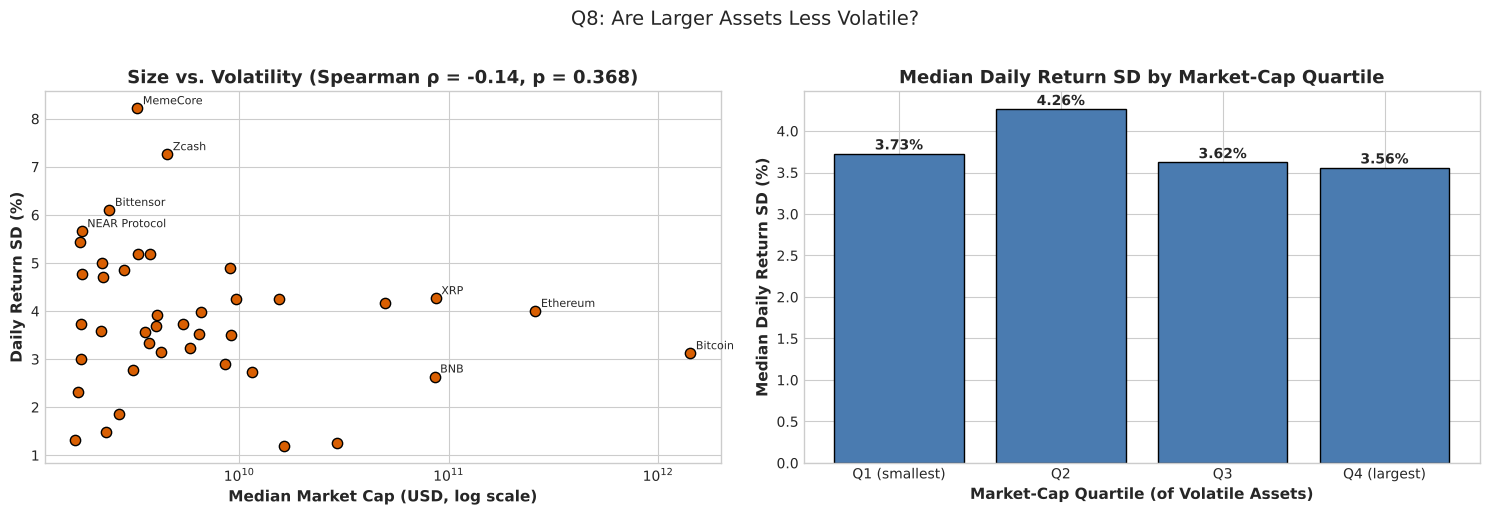

,mean,median,count
size_quartile,,,
Q1 (smallest),3.7252,3.7284,11
Q2,4.4741,4.2630,10
Q3,4.0070,3.6239,10
Q4 (largest),3.1898,3.5594,10


Spearman rho = -0.144, p-value = 0.3676, n = 41 assets


In [24]:
size_vol = (daily50[daily50['asset_type'] == 'Volatile']
            .groupby('name').agg(days=('chg_24h', 'count'), med_mcap=('market_cap', 'median'), daily_sd=('chg_24h', 'std')))
size_vol = size_vol[size_vol['days'] >= 30].copy()
size_vol['size_quartile'] = pd.qcut(size_vol['med_mcap'], 4, labels=['Q1 (smallest)', 'Q2', 'Q3', 'Q4 (largest)'])
rho8, p8 = stats.spearmanr(size_vol['med_mcap'], size_vol['daily_sd'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(size_vol['med_mcap'], size_vol['daily_sd'], color=ORANGE, edgecolor='black', s=55)
for n_, r_ in size_vol.iterrows():
    if r_['med_mcap'] > size_vol['med_mcap'].quantile(0.9) or r_['daily_sd'] > size_vol['daily_sd'].quantile(0.9):
        axes[0].annotate(n_, (r_['med_mcap'], r_['daily_sd']), fontsize=8, xytext=(4, 3), textcoords='offset points')
axes[0].set_xscale('log')
axes[0].set_title(f"Size vs. Volatility (Spearman ρ = {rho8:.2f}, p = {p8:.3f})")
axes[0].set_xlabel("Median Market Cap (USD, log scale)"); axes[0].set_ylabel("Daily Return SD (%)")

qv = size_vol.groupby('size_quartile', observed=True)['daily_sd'].agg(['mean', 'median', 'count'])
bars = axes[1].bar(qv.index.astype(str), qv['median'], color=LIGHT, edgecolor='black')
for b in bars:
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+0.05, f"{b.get_height():.2f}%", ha='center', fontweight='bold')
axes[1].set_title("Median Daily Return SD by Market-Cap Quartile")
axes[1].set_xlabel("Market-Cap Quartile (of Volatile Assets)"); axes[1].set_ylabel("Median Daily Return SD (%)")
plt.suptitle("Q8: Are Larger Assets Less Volatile?", y=1.02)
plt.tight_layout(); plt.show()

display(qv)
print(f"Spearman rho = {rho8:.3f}, p-value = {p8:.4f}, n = {len(size_vol)} assets")

* **Interpretation:**
  - Across 41 Volatile assets, the rank correlation between size and volatility is weak and **not significant (Spearman ρ = −0.144, p = 0.368)**.
  - Median daily SD by size quartile: 3.73 % (smallest), 4.26 %, 3.62 %, 3.56 % (largest) — the largest quartile is only marginally calmer, and the second quartile is the most volatile.
  - The calmest Volatile assets (TRON, gold tokens, Figure Heloc — Q6) are not the largest; large assets such as Ethereum (3.58 %) and XRP are not calm.
* **Implication:** within the top 50, **market cap is not a reliable proxy for risk**; volatility should be measured directly. (A related, small effect on big-move frequency is tested in Hypothesis Test 6.)

### Q9. How did Bitcoin's price evolve and what was its worst drawdown?
* **Justification:** Drawdown (fall from the running peak) is what investors actually experience as loss; it complements volatility.
* **Variables:** Bitcoin `price_usd`, `timestamp` (full period, all snapshots — Bitcoin is present in every snapshot).
* **Method:** Price line, running maximum, drawdown = price / running max − 1; monthly closing prices.

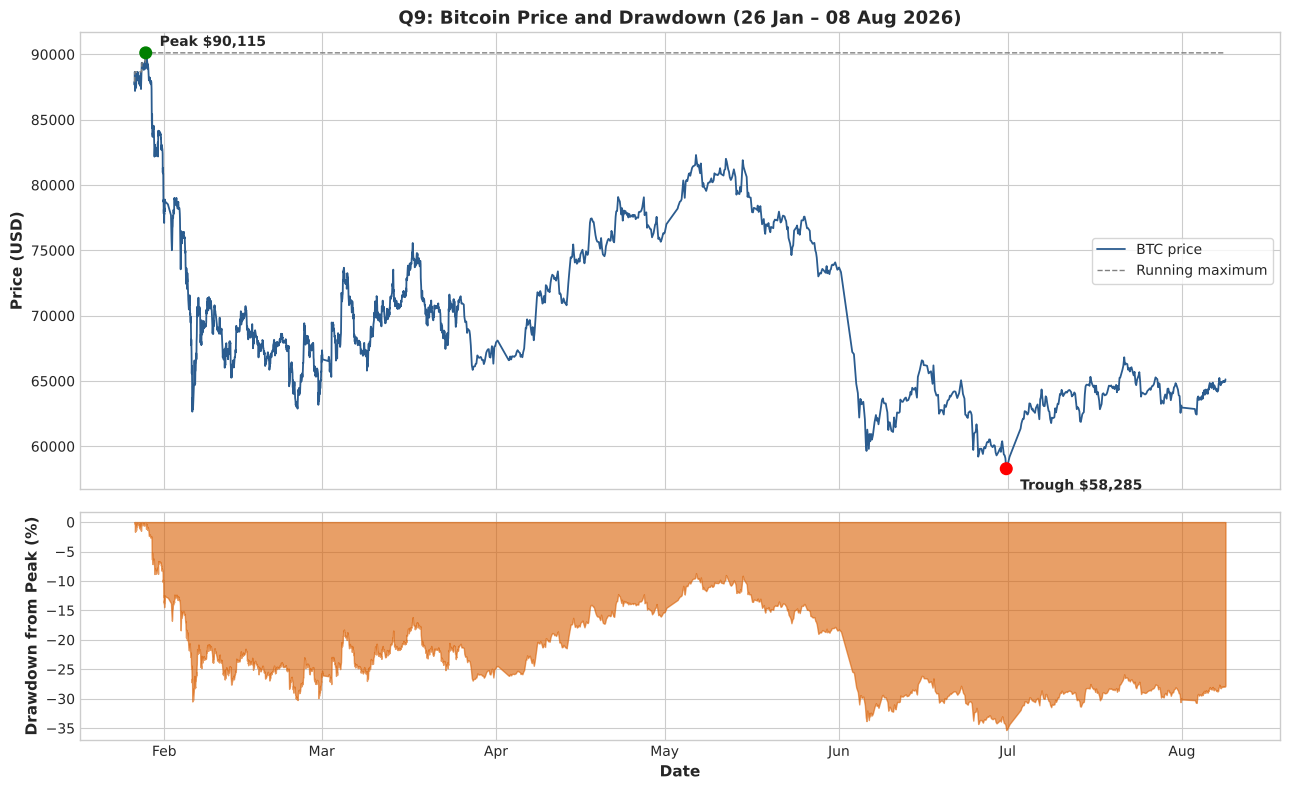

,first,last,min,max,change_%
timestamp,,,,,
Jan 2026,"87,888.0000","77,480.0000","77,093.0000","90,115.0000",-11.8423
Feb 2026,"77,823.0000","66,984.0000","62,652.0000","79,014.0000",-13.9278
Mar 2026,"66,492.0000","67,668.0000","65,312.0000","75,560.0000",1.7686
Apr 2026,"67,963.0000","76,273.0000","66,588.0000","79,080.0000",12.2272
May 2026,"76,364.0000","73,583.0000","73,003.0000","82,298.0000",-3.6418
Jun 2026,"73,687.0000","58,411.0000","58,285.0000","73,687.0000",-20.7309
Jul 2026,"58,632.0000","63,125.0000","58,632.0000","66,815.0000",7.6631
Aug 2026,"62,951.0000","65,125.0000","62,430.0000","65,230.0000",3.4535


Start: $87,888 (2026-01-26 16:54:46) | End: $65,125 (2026-08-08 18:00:38) | Period change: -25.90%
Max drawdown: -35.32% (peak 2026-01-28 17:00:49 -> trough 2026-06-30 18:22:03)


In [25]:
btc_all = df[df['name'] == 'Bitcoin'].set_index('timestamp')['price_usd'].sort_index()
run_max = btc_all.cummax()
drawdown = (btc_all / run_max - 1) * 100
trough_t = drawdown.idxmin(); peak_t = btc_all[:trough_t].idxmax()

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
axes[0].plot(btc_all.index, btc_all.values, color=BLUE, lw=1.3, label='BTC price')
axes[0].plot(run_max.index, run_max.values, color='grey', lw=1, ls='--', label='Running maximum')
axes[0].scatter([peak_t, trough_t], [btc_all[peak_t], btc_all[trough_t]], color=[ 'green', 'red'], s=70, zorder=5)
axes[0].annotate(f"Peak ${btc_all[peak_t]:,.0f}", (peak_t, btc_all[peak_t]), xytext=(10, 5), textcoords='offset points', fontweight='bold')
axes[0].annotate(f"Trough ${btc_all[trough_t]:,.0f}", (trough_t, btc_all[trough_t]), xytext=(10, -15), textcoords='offset points', fontweight='bold')
axes[0].set_title("Q9: Bitcoin Price and Drawdown (26 Jan – 08 Aug 2026)")
axes[0].set_ylabel("Price (USD)"); axes[0].legend(loc='center right', frameon=True)
axes[1].fill_between(drawdown.index, drawdown.values, 0, color=ORANGE, alpha=0.6)
axes[1].set_ylabel("Drawdown from Peak (%)"); axes[1].set_xlabel("Date")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
plt.tight_layout(); plt.show()

monthly = btc_all.resample('ME').agg(['first', 'last', 'min', 'max'])
monthly['change_%'] = (monthly['last'] / monthly['first'] - 1) * 100
monthly.index = monthly.index.strftime('%b %Y')
display(monthly)
print(f"Start: ${btc_all.iloc[0]:,.0f} ({btc_all.index[0]}) | End: ${btc_all.iloc[-1]:,.0f} ({btc_all.index[-1]}) | "
      f"Period change: {(btc_all.iloc[-1]/btc_all.iloc[0]-1)*100:.2f}%")
print(f"Max drawdown: {drawdown.min():.2f}% (peak {peak_t} -> trough {trough_t})")

* **Interpretation:**
  - Bitcoin fell from \$87,888 (26 Jan) to \$65,125 (08 Aug): **−25.90 %** over the period.
  - The running peak of **\$90,115** (28 Jan) was followed by a maximum drawdown of **−35.32 %**, reaching the trough of **\$58,285** on 30 Jun. The price never regained the January peak.
  - Monthly pattern: sharp declines in January (−11.8 %), February (−13.9 %) and June (−20.7 %); a recovery in April (+12.2 %); smaller moves in other months.
* **Implication:** a buyer at the late-January peak was at one point down more than a third — volatility (Q6) alone understates the losses actually experienced.

### Q10. How strongly do major assets' daily returns move together?
* **Justification:** If all major assets move together, holding several of them reduces risk very little.
* **Variables:** daily `chg_24h` of Volatile assets present on **every** day of the 50-asset panel.
* **Method:** Pivot to a date × asset matrix, Pearson correlation matrix (clustered heatmap ordering by hierarchical clustering), average pairwise correlation.

Assets present on all 108 days: 31


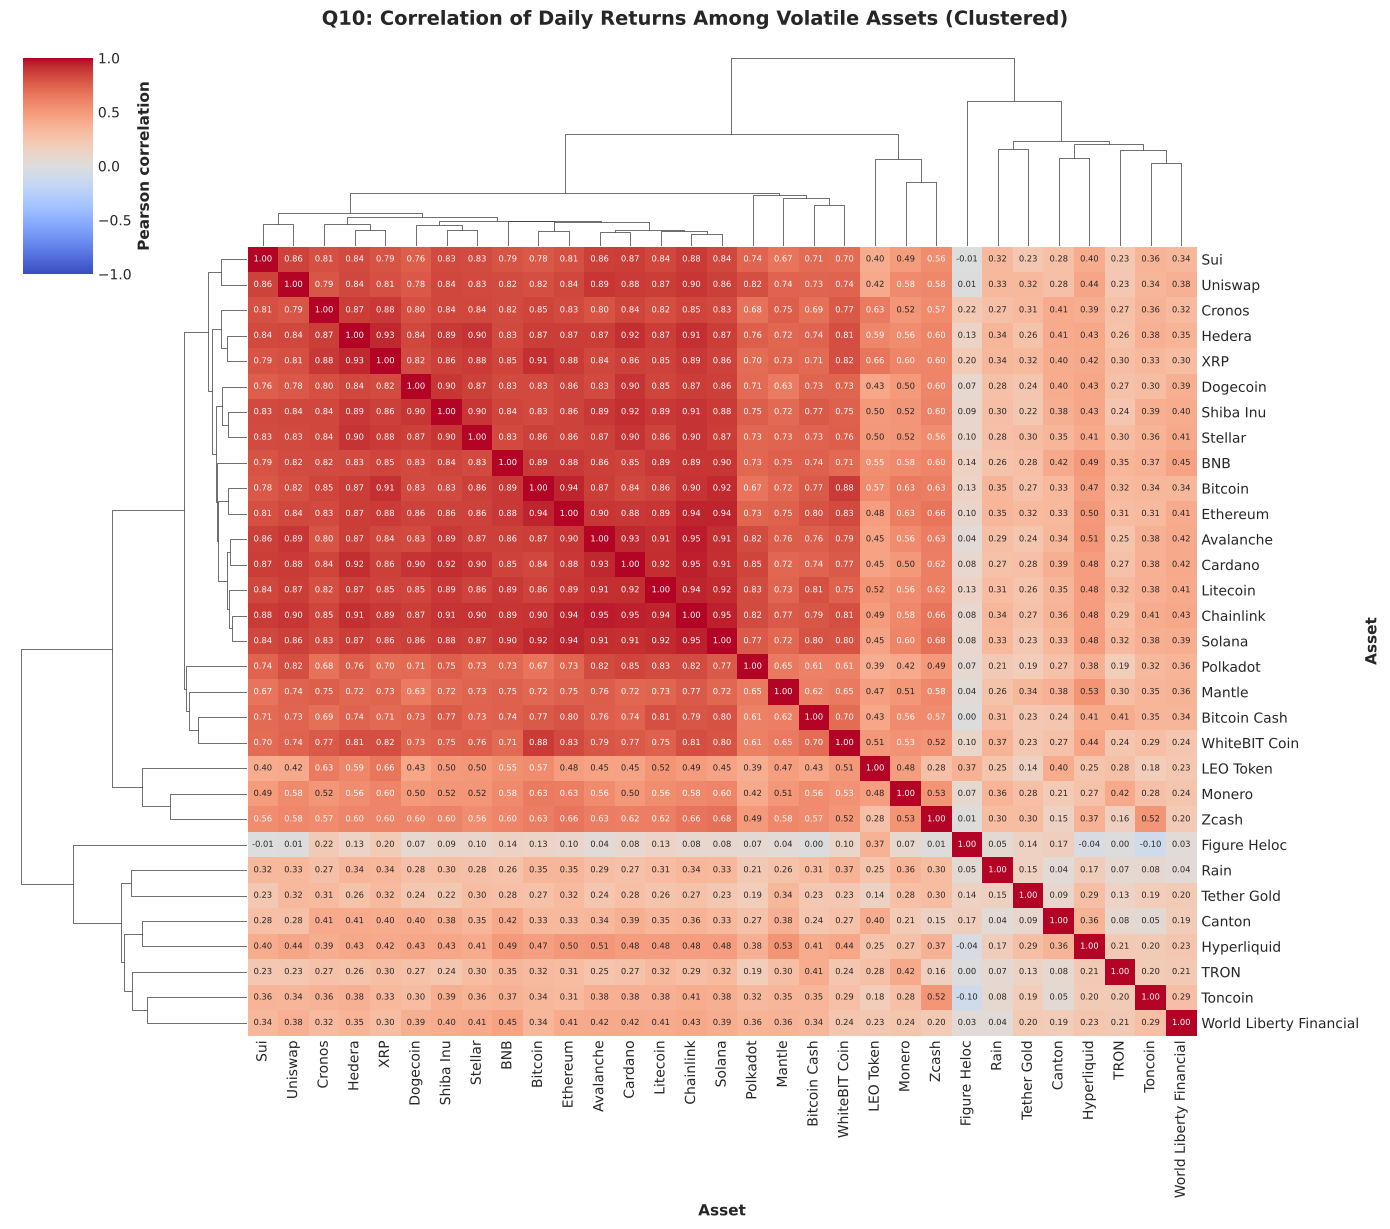

Average pairwise correlation: 0.536 | median: 0.516
Share of pairs with r > 0.5: 51.4%
Most correlated pairs:


,,r
name,name,
Avalanche,Chainlink,0.9536
Chainlink,Solana,0.9496
Cardano,Chainlink,0.9471
Bitcoin,Ethereum,0.9440
Chainlink,Ethereum,0.9435


Least correlated pairs:


r
name         name                
Figure Heloc Toncoin      -0.0995
             Hyperliquid  -0.0374
             Sui          -0.0055
             TRON          0.0021
Bitcoin Cash Figure Heloc  0.0045

Average correlation of each asset with all others (lowest 5):


,avg r
name,
Figure Heloc,0.0835
Tether Gold,0.2416
TRON,0.2466
Rain,0.2544
Canton,0.2881


In [26]:
ret_wide = daily50[daily50['asset_type'] == 'Volatile'].pivot(index='date', columns='name', values='chg_24h')
full_cols = ret_wide.columns[ret_wide.notna().all()]
ret_wide = ret_wide[full_cols]
print(f"Assets present on all {len(ret_wide)} days: {len(full_cols)}")
corr_ret = ret_wide.corr()

cg = sns.clustermap(corr_ret, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 6},
                    figsize=(14, 12), cbar_kws={'label': 'Pearson correlation'})
cg.fig.suptitle("Q10: Correlation of Daily Returns Among Volatile Assets (Clustered)", y=1.02, fontweight='bold')
cg.ax_heatmap.set_xlabel("Asset"); cg.ax_heatmap.set_ylabel("Asset")
plt.show()

upper = corr_ret.where(np.triu(np.ones(corr_ret.shape, dtype=bool), k=1)).stack().dropna()
print(f"Average pairwise correlation: {upper.mean():.3f} | median: {upper.median():.3f}")
print(f"Share of pairs with r > 0.5: {(upper > 0.5).mean()*100:.1f}%")
print("Most correlated pairs:"); display(upper.sort_values(ascending=False).head(5).to_frame('r'))
print("Least correlated pairs:"); display(upper.sort_values().head(5).to_frame('r'))
print("Average correlation of each asset with all others (lowest 5):")
display(corr_ret.apply(lambda c: c.drop(c.name).mean()).sort_values().head(5).to_frame('avg r'))

* **Interpretation:**
  - Among the 31 Volatile assets present on all 108 days, the average pairwise correlation of daily returns is **0.536** (median 0.516), and **51.4 %** of pairs exceed 0.5.
  - The clustered heatmap shows one large block of major assets moving almost in lockstep: Avalanche–Chainlink r = 0.954, Chainlink–Solana 0.950, **Bitcoin–Ethereum 0.944**.
  - A small group is only loosely connected to the rest: Figure Heloc (average r = 0.08), Tether Gold (0.24), TRON (0.25), Rain (0.25), Canton (0.29).
* **Implication:** holding many large crypto assets gives much less diversification than the number of holdings suggests; genuine diversifiers in this dataset are the gold-backed and a few idiosyncratic tokens.

### Q11. How sensitive is each asset to Bitcoin (beta)?
* **Justification:** Beta tells how much an asset moves for a 1 % move in Bitcoin. β > 1 means the asset amplifies Bitcoin's moves; β < 1 dampens them.
* **Variables:** daily `chg_24h` of each asset and of Bitcoin (same days).
* **Method:** Simple linear regression per asset, $r_{i,t} = \alpha_i + \beta_i\, r_{BTC,t} + \varepsilon$ (OLS slope), plus $R^2$ = share of the asset's daily variance explained by Bitcoin.

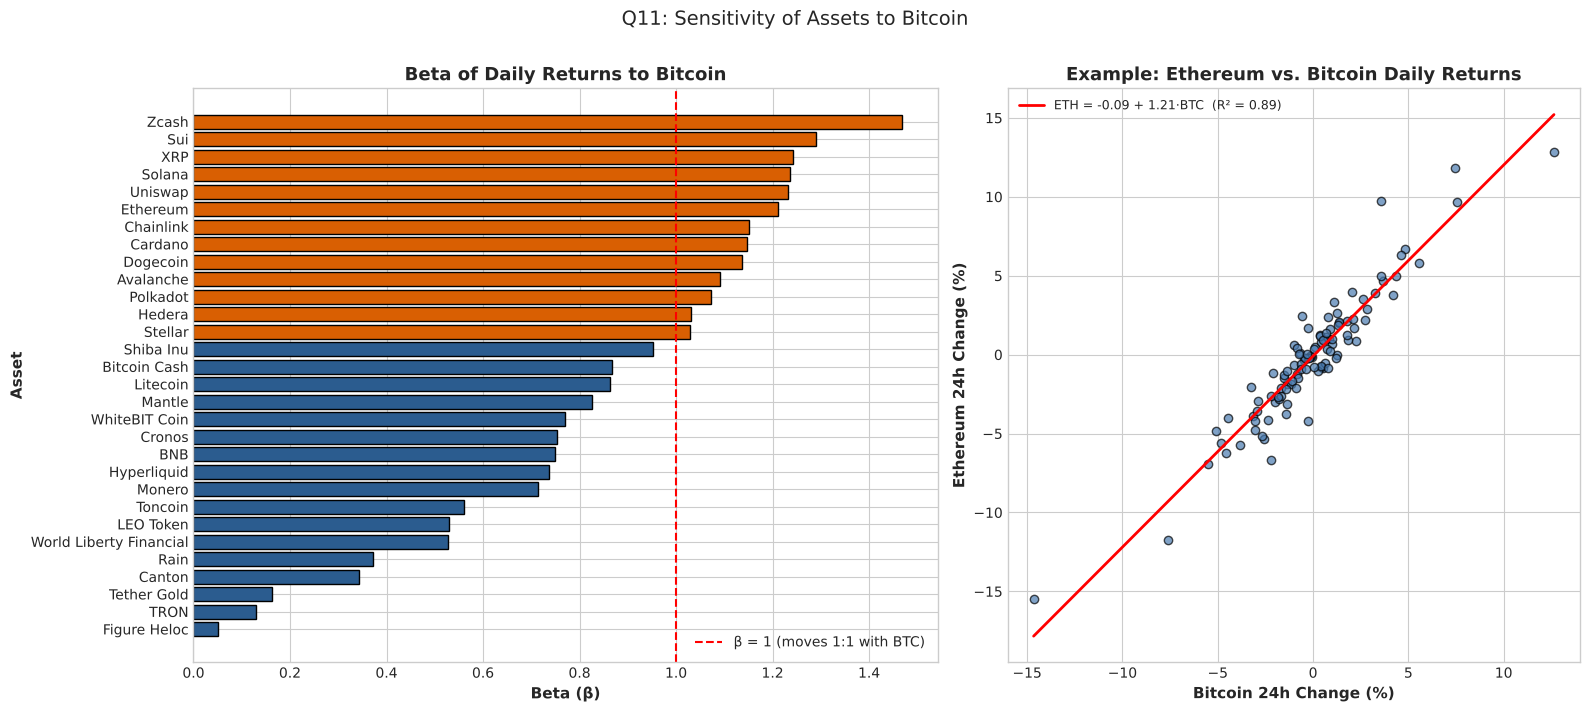

,asset,beta,alpha_%,R2,p_value
29,Zcash,1.4685,0.8267,0.3982,0.0000
21,Sui,1.2906,-0.0257,0.6027,0.0000
28,XRP,1.2425,-0.0759,0.8267,0.0000
19,Solana,1.2359,-0.1149,0.8526,0.0000
25,Uniswap,1.2315,0.0142,0.6676,0.0000
8,Ethereum,1.2103,-0.0904,0.8912,0.0000
5,Chainlink,1.1514,0.0378,0.8180,0.0000
4,Cardano,1.1474,-0.1393,0.7083,0.0000
7,Dogecoin,1.1376,0.0104,0.6948,0.0000
0,Avalanche,1.0902,-0.0410,0.7566,0.0000


Assets with beta > 1: 13 of 30 | median beta = 0.866 | median R² = 0.635


In [27]:
btc_series = ret_wide['Bitcoin']
beta_rows = []
for a in ret_wide.columns.drop('Bitcoin'):
    res = stats.linregress(btc_series, ret_wide[a])
    beta_rows.append({'asset': a, 'beta': res.slope, 'alpha_%': res.intercept, 'R2': res.rvalue**2, 'p_value': res.pvalue})
beta_df = pd.DataFrame(beta_rows).sort_values('beta', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.3, 1]})
cols_ = [ORANGE if b > 1 else BLUE for b in beta_df['beta']]
axes[0].barh(beta_df['asset'][::-1], beta_df['beta'][::-1], color=cols_[::-1], edgecolor='black')
axes[0].axvline(1, color='red', ls='--', label='β = 1 (moves 1:1 with BTC)')
axes[0].set_title("Beta of Daily Returns to Bitcoin")
axes[0].set_xlabel("Beta (β)"); axes[0].set_ylabel("Asset"); axes[0].legend(loc='lower right')

eth = ret_wide['Ethereum']
res_e = stats.linregress(btc_series, eth)
axes[1].scatter(btc_series, eth, color=LIGHT, edgecolor='black', alpha=0.7)
xx = np.linspace(btc_series.min(), btc_series.max(), 100)
axes[1].plot(xx, res_e.intercept + res_e.slope*xx, 'r-', lw=2, label=f"ETH = {res_e.intercept:.2f} + {res_e.slope:.2f}·BTC  (R² = {res_e.rvalue**2:.2f})")
axes[1].set_title("Example: Ethereum vs. Bitcoin Daily Returns")
axes[1].set_xlabel("Bitcoin 24h Change (%)"); axes[1].set_ylabel("Ethereum 24h Change (%)"); axes[1].legend(fontsize=9)
plt.suptitle("Q11: Sensitivity of Assets to Bitcoin", y=1.01)
plt.tight_layout(); plt.show()

display(beta_df.round(4))
print(f"Assets with beta > 1: {(beta_df['beta'] > 1).sum()} of {len(beta_df)} | median beta = {beta_df['beta'].median():.3f} | median R² = {beta_df['R2'].median():.3f}")

* **Interpretation:**
  - **13 of 30** assets have β > 1, i.e. they amplify Bitcoin's moves; the median β is 0.866 and the median R² is 0.635 (Bitcoin explains about two-thirds of a typical asset's daily variance).
  - Highest betas: Zcash 1.47 (but R² only 0.40 — large own-moves too), Sui 1.29, XRP 1.24, Solana 1.24, Uniswap 1.23, **Ethereum 1.21 with R² = 0.89** (ETH ≈ −0.09 + 1.21 × BTC).
  - Lowest: Figure Heloc β = 0.05 (not significant, p = 0.18), TRON 0.13, Tether Gold 0.16, Canton 0.34, Rain 0.37. All other betas are significant at 5 %.
* **Implication:** for most major assets, a view on Bitcoin is effectively a leveraged view on the asset; position sizing should be done in "Bitcoin-equivalent" (β-adjusted) terms.

### Q12. Does market activity or Bitcoin's return differ by day of the week?
* **Justification:** Crypto trades every day, but institutional desks and traditional markets are closed at weekends. Calendar effects matter for trade timing and staffing.
* **Variables:** daily total 24h volume of the 50 tracked assets; Bitcoin `chg_24h`; `day_of_week`.
* **Method:** Group means/medians by weekday; bar charts with the overall mean line. Formal tests: **Hypothesis Tests 1 and 5**.

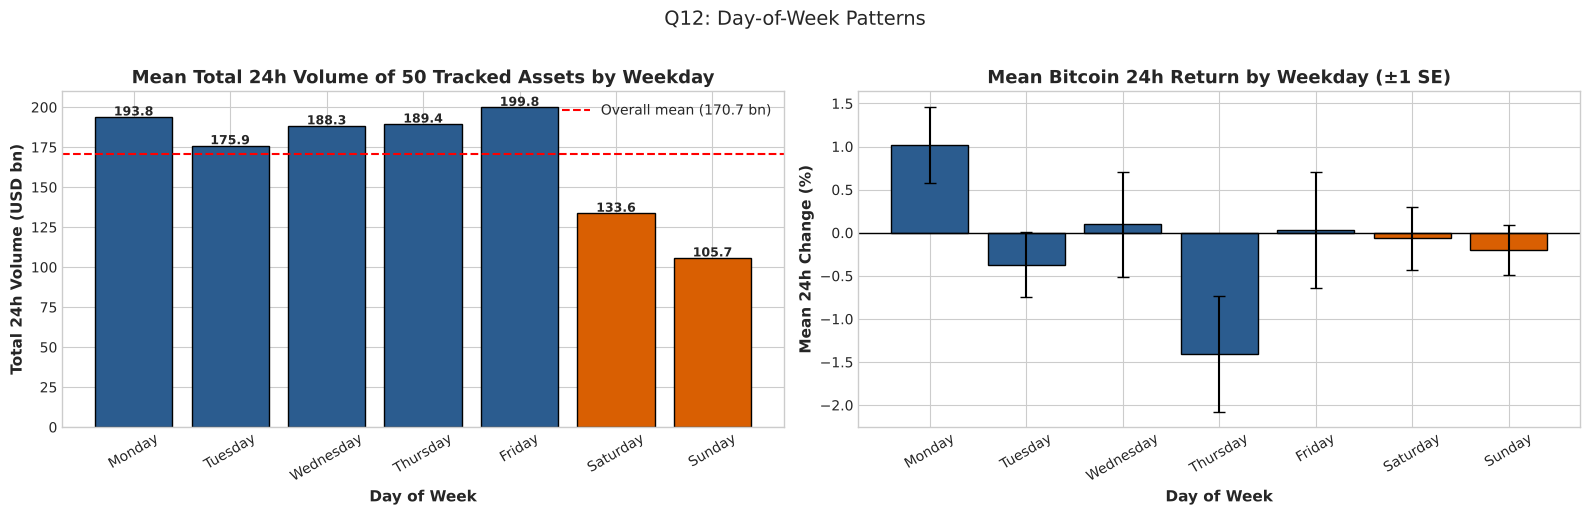

,mean,median,count
day_of_week,,,
Monday,193.8300,193.5500,17
Tuesday,175.8800,166.8600,17
Wednesday,188.2700,180.4000,15
Thursday,189.3900,165.3700,15
Friday,199.8200,162.3700,15
Saturday,133.6300,97.7200,15
Sunday,105.6800,93.0400,14


,mean,median,std,count
day_of_week,,,,
Monday,1.0200,1.1000,2.2960,27
Tuesday,-0.3690,-0.7600,1.9520,27
Wednesday,0.0960,-0.2900,3.1190,26
Thursday,-1.4040,-1.3000,3.4340,26
Friday,0.0300,0.0600,3.5100,27
Saturday,-0.0660,0.1950,1.8710,26
Sunday,-0.2020,-0.2600,1.4340,24


In [28]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
mkt_daily = daily50.groupby('date').agg(total_vol_usd=('vol_24h', 'sum'), total_mcap=('market_cap', 'sum')).reset_index()
mkt_daily['day_of_week'] = mkt_daily['date'].dt.day_name()
mkt_daily['is_weekend'] = mkt_daily['date'].dt.dayofweek >= 5
mkt_daily['total_vol_bn'] = mkt_daily['total_vol_usd'] / 1e9
mkt_daily['market_turnover_%'] = mkt_daily['total_vol_usd'] / mkt_daily['total_mcap'] * 100

btc_daily = daily[daily['name'] == 'Bitcoin'][['date', 'chg_24h']].copy()
btc_daily['day_of_week'] = btc_daily['date'].dt.day_name()

vol_dow = mkt_daily.groupby('day_of_week')['total_vol_bn'].agg(['mean', 'median', 'count']).reindex(order)
ret_dow = btc_daily.groupby('day_of_week')['chg_24h'].agg(['mean', 'median', 'std', 'count']).reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
cols_ = [ORANGE if d in ['Saturday', 'Sunday'] else BLUE for d in order]
bars = axes[0].bar(order, vol_dow['mean'], color=cols_, edgecolor='black')
axes[0].axhline(mkt_daily['total_vol_bn'].mean(), color='red', ls='--', label=f"Overall mean ({mkt_daily['total_vol_bn'].mean():.1f} bn)")
for b in bars:
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+1, f"{b.get_height():.1f}", ha='center', fontweight='bold', fontsize=9)
axes[0].set_title("Mean Total 24h Volume of 50 Tracked Assets by Weekday")
axes[0].set_xlabel("Day of Week"); axes[0].set_ylabel("Total 24h Volume (USD bn)"); axes[0].legend()
axes[0].tick_params(axis='x', rotation=30)

bars = axes[1].bar(order, ret_dow['mean'], color=cols_, edgecolor='black', yerr=ret_dow['std']/np.sqrt(ret_dow['count']), capsize=4)
axes[1].axhline(0, color='black', lw=1)
axes[1].set_title("Mean Bitcoin 24h Return by Weekday (±1 SE)")
axes[1].set_xlabel("Day of Week"); axes[1].set_ylabel("Mean 24h Change (%)")
axes[1].tick_params(axis='x', rotation=30)
plt.suptitle("Q12: Day-of-Week Patterns", y=1.02)
plt.tight_layout(); plt.show()

display(vol_dow.round(2)); display(ret_dow.round(3))

* **Interpretation:**
  - **Volume:** weekday means range from \$175.9 bn (Tue) to \$199.8 bn (Fri), but **Saturday (\$133.6 bn) and Sunday (\$105.7 bn)** are clearly lower than every weekday.
  - **Bitcoin returns:** Monday has the highest mean (+1.02 %, median +1.10 %) and Thursday the lowest (−1.40 %, median −1.30 %); other days lie between −0.37 % and +0.10 %. Each day has only 24–27 observations and the error bars are wide, so these differences need a formal test.
* **Implication:** the weekend volume gap looks large and consistent (tested in Hypothesis Test 1); the weekday return pattern is weaker and is tested in Hypothesis Test 5.

### Q13. Is total market volume lower at weekends? *(A/B framing)*
* **Justification:** Directly actionable for exchanges (fee promotions, maintenance windows) and traders (slippage risk).
* **Variables:** `total_vol_bn` per day, `is_weekend`.
* **Method:** Group A = weekdays, Group B = weekend days. Compare distributions (box + strip plot) and the relative difference in means and medians. Formal A/B test: **Hypothesis Test 1**.

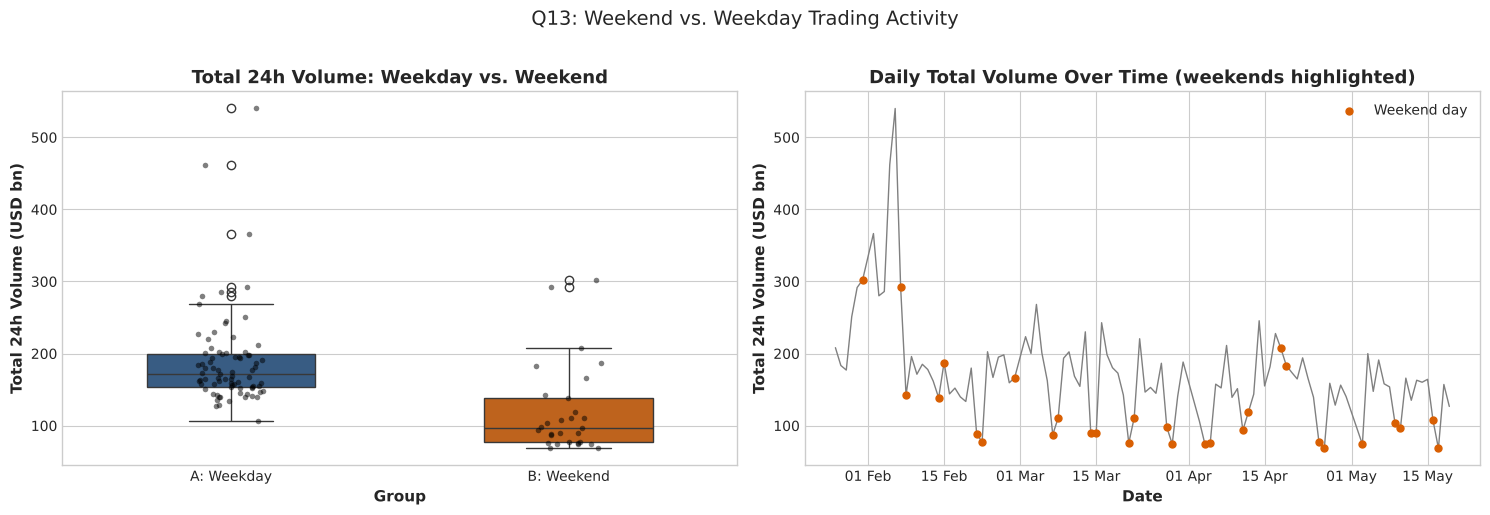

,count,mean,median,std
Group,,,,
A: Weekday,79,189.2000,171.3300,66.7400
B: Weekend,29,120.1400,96.4300,61.9200


Weekend mean is -36.5% vs weekday mean; weekend median is -43.7% vs weekday median


In [29]:
mkt_daily['Group'] = np.where(mkt_daily['is_weekend'], 'B: Weekend', 'A: Weekday')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=mkt_daily, x='Group', y='total_vol_bn', palette=[BLUE, ORANGE], ax=axes[0], width=0.5, order=['A: Weekday', 'B: Weekend'])
sns.stripplot(data=mkt_daily, x='Group', y='total_vol_bn', color='black', alpha=0.5, size=4, ax=axes[0], order=['A: Weekday', 'B: Weekend'])
axes[0].set_title("Total 24h Volume: Weekday vs. Weekend")
axes[0].set_xlabel("Group"); axes[0].set_ylabel("Total 24h Volume (USD bn)")

axes[1].plot(mkt_daily['date'], mkt_daily['total_vol_bn'], color='grey', lw=1)
wk = mkt_daily[mkt_daily['is_weekend']]
axes[1].scatter(wk['date'], wk['total_vol_bn'], color=ORANGE, zorder=5, s=25, label='Weekend day')
axes[1].set_title("Daily Total Volume Over Time (weekends highlighted)")
axes[1].set_xlabel("Date"); axes[1].set_ylabel("Total 24h Volume (USD bn)"); axes[1].legend()
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
plt.suptitle("Q13: Weekend vs. Weekday Trading Activity", y=1.02)
plt.tight_layout(); plt.show()

q13 = mkt_daily.groupby('Group')['total_vol_bn'].agg(['count', 'mean', 'median', 'std'])
display(q13.round(2))
print(f"Weekend mean is {(q13.loc['B: Weekend','mean']/q13.loc['A: Weekday','mean']-1)*100:.1f}% vs weekday mean; "
      f"weekend median is {(q13.loc['B: Weekend','median']/q13.loc['A: Weekday','median']-1)*100:.1f}% vs weekday median")

* **Interpretation:**
  - Group A (weekdays, n = 79): mean **\$189.2 bn**, median \$171.3 bn. Group B (weekend days, n = 29): mean **\$120.1 bn**, median \$96.4 bn.
  - Weekend volume is **36.5 % lower on average** (43.7 % lower at the median). The time series shows weekend days sitting near the bottom of the weekly cycle through most of the period (the exceptions are 31 Jan and 7 Feb, during the high-volume episode at the start of the period, when weekend volume exceeded \$290 bn).
* **Implication:** liquidity is thinner at weekends, so large orders placed then face higher price impact; exchanges can schedule maintenance for weekends with less disruption.

### Q14. Is trading activity related to the size of price moves?
* **Justification:** The volume–volatility relation is a well-known market regularity: big price moves attract trading. If present, unusual volume can serve as an early warning of large moves (or vice versa).
* **Variables:** `abs_chg_24h`, `turnover_pct` (Volatile assets).
* **Method:** To remove differences *between* assets (some coins always trade more), each asset's turnover and |return| are converted to **within-asset z-scores**; then pooled Spearman correlation + binned means. Also per-asset Spearman correlations.

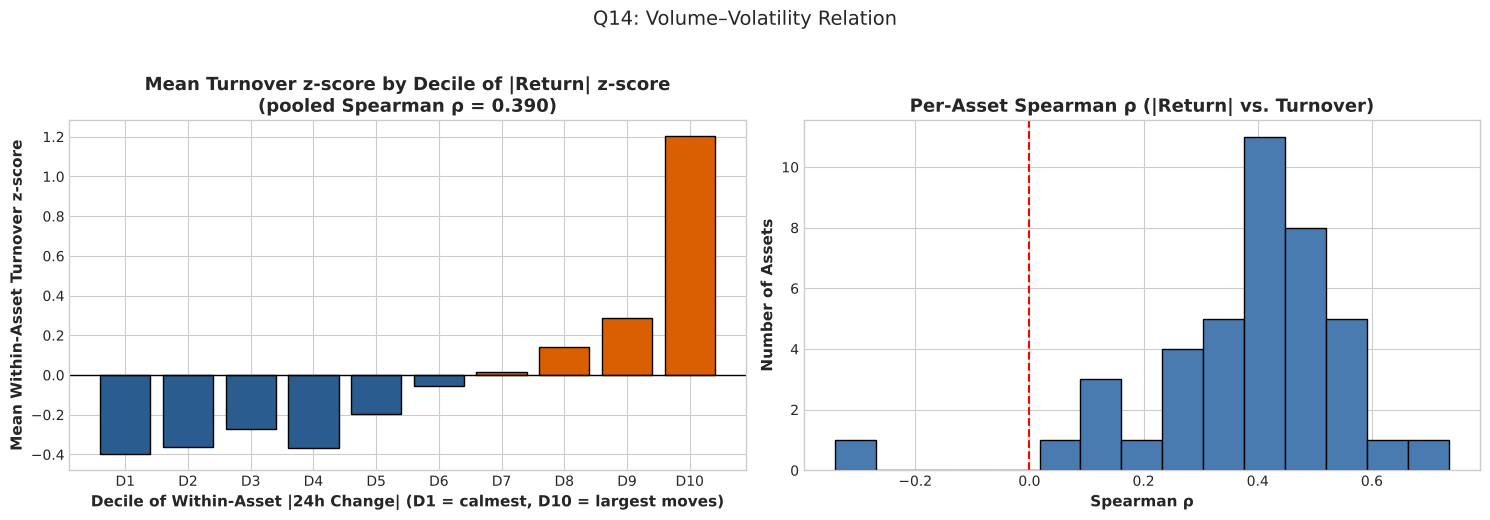

move_bin,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
mean turnover z,-0.4000,-0.3600,-0.2690,-0.3690,-0.1950,-0.0550,0.0150,0.1400,0.2890,1.2040


Pooled within-asset Spearman rho = 0.3899 (p = 3.762e-153, n = 4,216)
Per-asset rho: 41 assets, median = 0.420, positive for 40 assets


In [30]:
v = daily50[(daily50['asset_type'] == 'Volatile') & (daily50['vol_24h'] > 0)].copy()
v['log_turnover'] = np.log10(v['turnover_pct'])
for c in ['log_turnover', 'abs_chg_24h']:
    v[c + '_z'] = v.groupby('name')[c].transform(lambda s: (s - s.mean()) / s.std())
v = v.dropna(subset=['log_turnover_z', 'abs_chg_24h_z'])
rho14, p14 = stats.spearmanr(v['abs_chg_24h_z'], v['log_turnover_z'])

per_asset = v.groupby('name').apply(lambda g: stats.spearmanr(g['abs_chg_24h'], g['turnover_pct'])[0] if len(g) >= 30 else np.nan).dropna()

v['move_bin'] = pd.qcut(v['abs_chg_24h_z'], 10, labels=[f'D{i}' for i in range(1, 11)])
binned = v.groupby('move_bin', observed=True)['log_turnover_z'].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bars = axes[0].bar(binned.index.astype(str), binned.values, color=[ORANGE if b > 0 else BLUE for b in binned.values], edgecolor='black')
axes[0].axhline(0, color='black', lw=1)
axes[0].set_title(f"Mean Turnover z-score by Decile of |Return| z-score\n(pooled Spearman ρ = {rho14:.3f})")
axes[0].set_xlabel("Decile of Within-Asset |24h Change| (D1 = calmest, D10 = largest moves)")
axes[0].set_ylabel("Mean Within-Asset Turnover z-score")

axes[1].hist(per_asset, bins=15, color=LIGHT, edgecolor='black')
axes[1].axvline(0, color='red', ls='--')
axes[1].set_title("Per-Asset Spearman ρ (|Return| vs. Turnover)")
axes[1].set_xlabel("Spearman ρ"); axes[1].set_ylabel("Number of Assets")
plt.suptitle("Q14: Volume–Volatility Relation", y=1.03)
plt.tight_layout(); plt.show()

display(binned.to_frame('mean turnover z').T.round(3))
print(f"Pooled within-asset Spearman rho = {rho14:.4f} (p = {p14:.3e}, n = {len(v):,})")
print(f"Per-asset rho: {len(per_asset)} assets, median = {per_asset.median():.3f}, positive for {(per_asset > 0).sum()} assets")

* **Interpretation:**
  - Within each asset, turnover rises steadily with the size of the day's move: the calmest decile has a mean turnover z-score of −0.40, the largest-move decile **+1.20**.
  - Pooled within-asset **Spearman ρ = 0.390** (p ≈ 4 × 10⁻¹⁵³, n = 4,216 asset-days); per asset, ρ is positive for **40 of 41** assets (median 0.42).
* **Implication:** the classic volume–volatility relation holds very consistently in crypto. Unusually high turnover is a useful flag that a large move is under way. (Contemporaneous association — this does not show which causes which.)

### Q15. When Bitcoin moves, does the rest of the market follow (market breadth)?
* **Justification:** "Breadth" = % of assets rising on a day. If breadth tracks Bitcoin closely, Bitcoin's direction is a near-sufficient signal for the whole market.
* **Variables:** sign of `chg_24h` for non-Bitcoin Volatile assets; Bitcoin `chg_24h`.
* **Method:** Daily % of other Volatile assets with positive 24h change; scatter vs. Bitcoin's return; agreement table (BTC up/down vs. majority up/down).

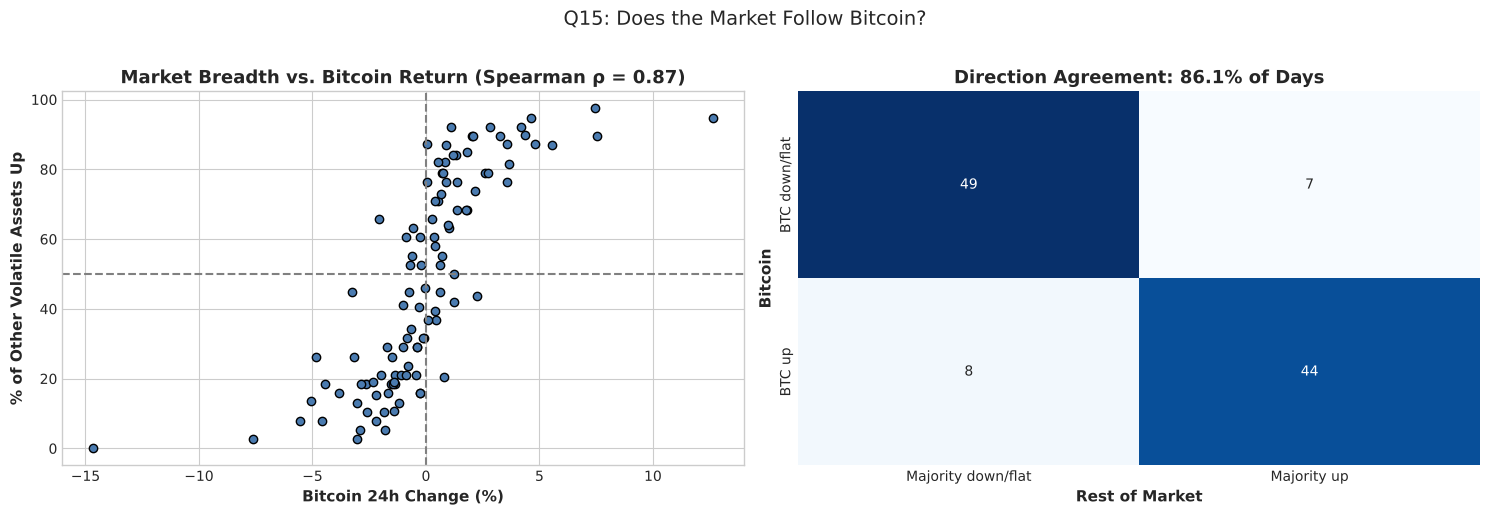

Market majority,Majority down/flat,Majority up
BTC direction,,
BTC down/flat,49,7
BTC up,8,44


Days: 108 | Spearman rho = 0.868 (p = 4.942e-34) | direction agreement = 86.1%
Mean % up on BTC-up days: 73.0% | on BTC-down/flat days: 25.3%


In [31]:
others = daily50[(daily50['asset_type'] == 'Volatile') & (daily50['name'] != 'Bitcoin')]
breadth = others.groupby('date')['chg_24h'].apply(lambda s: (s > 0).mean()*100).rename('pct_up')
b15 = pd.concat([breadth, ret_wide['Bitcoin'].rename('btc_ret')], axis=1).dropna()
rho15, p15 = stats.spearmanr(b15['btc_ret'], b15['pct_up'])

b15['BTC direction'] = np.where(b15['btc_ret'] > 0, 'BTC up', 'BTC down/flat')
b15['Market majority'] = np.where(b15['pct_up'] > 50, 'Majority up', 'Majority down/flat')
agree_tab = pd.crosstab(b15['BTC direction'], b15['Market majority'])
agreement = (np.diag(agree_tab.loc[['BTC down/flat', 'BTC up'], ['Majority down/flat', 'Majority up']]).sum() / len(b15)) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(b15['btc_ret'], b15['pct_up'], color=LIGHT, edgecolor='black')
axes[0].axhline(50, color='grey', ls='--'); axes[0].axvline(0, color='grey', ls='--')
axes[0].set_title(f"Market Breadth vs. Bitcoin Return (Spearman ρ = {rho15:.2f})")
axes[0].set_xlabel("Bitcoin 24h Change (%)"); axes[0].set_ylabel("% of Other Volatile Assets Up")

sns.heatmap(agree_tab, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_title(f"Direction Agreement: {agreement:.1f}% of Days")
axes[1].set_xlabel("Rest of Market"); axes[1].set_ylabel("Bitcoin")
plt.suptitle("Q15: Does the Market Follow Bitcoin?", y=1.02)
plt.tight_layout(); plt.show()

display(agree_tab)
print(f"Days: {len(b15)} | Spearman rho = {rho15:.3f} (p = {p15:.3e}) | direction agreement = {agreement:.1f}%")
print(f"Mean % up on BTC-up days: {b15.loc[b15['btc_ret']>0,'pct_up'].mean():.1f}% | on BTC-down/flat days: {b15.loc[b15['btc_ret']<=0,'pct_up'].mean():.1f}%")

* **Interpretation:**
  - Market breadth tracks Bitcoin closely (**Spearman ρ = 0.868**, 108 days). On Bitcoin-up days, on average **73.0 %** of the other Volatile assets also rose; on Bitcoin-down/flat days, only 25.3 % did.
  - Bitcoin's direction matched the majority direction on **86.1 %** of days (49 + 44 of 108).
* **Implication:** Bitcoin's daily direction is close to a market-wide signal; days where breadth diverges from Bitcoin (the 15 off-diagonal days) are the exception rather than the rule.

## 8. Statistical Hypothesis Testing and A/B Testing

For every test: research question → choice of test (justified) → $H_0$ / $H_1$ → $\alpha = 0.05$ → assumption checks → statistic & p-value → effect size → decision → interpretation. All results are collected programmatically into a summary table at the end (so the table always matches the computed values).

**Independence note:** tests use the daily panel (one observation per asset per day) or per-asset aggregates — never the raw overlapping hourly rows (see §5.7).

In [32]:
test_results = []
def record(no, question, test, stat_label, stat, p, effect_label, effect, decision_override=None):
    decision = decision_override or ('Reject H0' if p < ALPHA else 'Fail to reject H0')
    test_results.append({'Test': no, 'Question': question, 'Statistical test': test,
                         'Statistic': f"{stat_label} = {stat:.4f}", 'p-value': p,
                         'Effect size': f"{effect_label} = {effect:.4f}" if effect is not None else '—',
                         'Decision (α = 0.05)': decision})
    print(f"Decision: {decision} (p = {p:.4e})")

def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na-1)*np.var(a, ddof=1) + (nb-1)*np.var(b, ddof=1)) / (na+nb-2))
    return (np.mean(a) - np.mean(b)) / sp

### Hypothesis Test 1 (A/B Test): Weekend vs. Weekday Total Market Volume
* **Question:** Is the total 24h trading volume of the 50 tracked assets different at weekends?
* **Groups:** A = weekdays (control), B = weekend days (treatment).
* **Hypotheses:** $H_0: \mu_{weekend} = \mu_{weekday}$  vs.  $H_1: \mu_{weekend} \ne \mu_{weekday}$.
* **Tests:** Shapiro-Wilk (normality per group) and Levene (equal variances) → **Welch's t-test** (no equal-variance assumption) + **Mann-Whitney U** (non-parametric) + **permutation test** (10,000 label shuffles, assumption-free) + bootstrap 95% CI for the difference in means. Effect size: Cohen's d.

n_A (weekday) = 79, mean = 189.20 bn, median = 171.33 bn
n_B (weekend) = 29, mean = 120.14 bn, median = 96.43 bn

Shapiro-Wilk weekday p = 0.0000 | weekend p = 0.0000
Levene p = 0.9291



Difference in means (B - A) = -69.06 bn (-36.5% of weekday mean)
Bootstrap 95% CI for difference: [-94.75, -42.50] bn
Welch t = -5.0288, p = 5.8952e-06
Mann-Whitney U = 368.0, p = 7.1946e-08
Permutation test: 0 of 10,000 shuffled differences were as extreme -> p = 0.00010 (i.e. p < 0.001)
Cohen's d = -1.0544


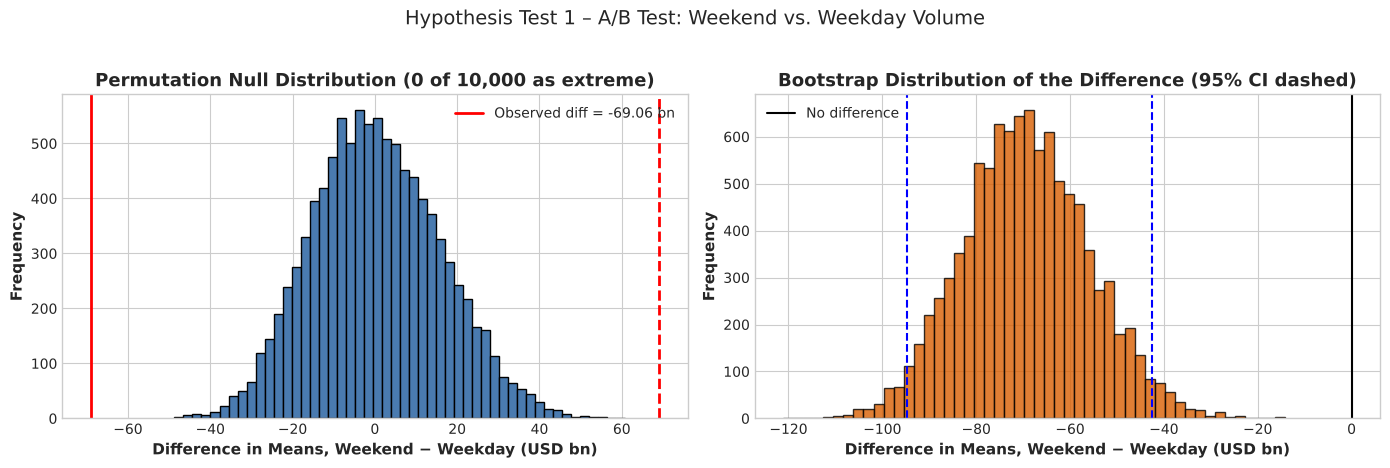

Decision: Reject H0 (p = 5.8952e-06)


In [33]:
A = mkt_daily.loc[~mkt_daily['is_weekend'], 'total_vol_bn'].values
B = mkt_daily.loc[mkt_daily['is_weekend'], 'total_vol_bn'].values
print(f"n_A (weekday) = {len(A)}, mean = {A.mean():.2f} bn, median = {np.median(A):.2f} bn")
print(f"n_B (weekend) = {len(B)}, mean = {B.mean():.2f} bn, median = {np.median(B):.2f} bn")

sw_A, sw_B = stats.shapiro(A), stats.shapiro(B)
lev = stats.levene(A, B)
print(f"\nShapiro-Wilk weekday p = {sw_A.pvalue:.4f} | weekend p = {sw_B.pvalue:.4f}")
print(f"Levene p = {lev.pvalue:.4f}")

t1 = stats.ttest_ind(B, A, equal_var=False)
u1 = stats.mannwhitneyu(B, A, alternative='two-sided')
obs_diff = B.mean() - A.mean()
pooled = np.concatenate([A, B]); perm_diffs = np.empty(10000)
for i in range(10000):
    rng.shuffle(pooled)
    perm_diffs[i] = pooled[:len(B)].mean() - pooled[len(B):].mean()
n_extreme = int((np.abs(perm_diffs) >= abs(obs_diff)).sum())
p_perm = (n_extreme + 1) / (len(perm_diffs) + 1)   # add-one estimator: never reports an impossible p = 0
boot_d = np.array([rng.choice(B, len(B)).mean() - rng.choice(A, len(A)).mean() for _ in range(10000)])
ci_d = np.percentile(boot_d, [2.5, 97.5])
d1 = cohens_d(B, A)

print(f"\nDifference in means (B - A) = {obs_diff:.2f} bn ({obs_diff/A.mean()*100:.1f}% of weekday mean)")
print(f"Bootstrap 95% CI for difference: [{ci_d[0]:.2f}, {ci_d[1]:.2f}] bn")
print(f"Welch t = {t1.statistic:.4f}, p = {t1.pvalue:.4e}")
print(f"Mann-Whitney U = {u1.statistic:.1f}, p = {u1.pvalue:.4e}")
print(f"Permutation test: {n_extreme} of 10,000 shuffled differences were as extreme -> p = {p_perm:.5f} (i.e. p < 0.001)" if n_extreme == 0 else f"Permutation test p = {p_perm:.5f}")
print(f"Cohen's d = {d1:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(perm_diffs, bins=50, color=LIGHT, edgecolor='black')
axes[0].axvline(obs_diff, color='red', lw=2, label=f'Observed diff = {obs_diff:.2f} bn')
axes[0].axvline(-obs_diff, color='red', lw=2, ls='--')
axes[0].set_title(f"Permutation Null Distribution ({n_extreme} of 10,000 as extreme)")
axes[0].set_xlabel("Difference in Means, Weekend − Weekday (USD bn)"); axes[0].set_ylabel("Frequency"); axes[0].legend()
axes[1].hist(boot_d, bins=50, color=ORANGE, edgecolor='black', alpha=0.8)
axes[1].axvline(0, color='black', lw=1.5, label='No difference')
for c_ in ci_d: axes[1].axvline(c_, color='blue', ls='--')
axes[1].set_title("Bootstrap Distribution of the Difference (95% CI dashed)")
axes[1].set_xlabel("Difference in Means, Weekend − Weekday (USD bn)"); axes[1].set_ylabel("Frequency"); axes[1].legend()
plt.suptitle("Hypothesis Test 1 – A/B Test: Weekend vs. Weekday Volume", y=1.03)
plt.tight_layout(); plt.show()

record(1, 'Weekend vs weekday total volume (A/B)', "Welch t (+ Mann-Whitney, permutation)", 't', t1.statistic, t1.pvalue, "Cohen's d", d1)

* **Assumptions:** Shapiro-Wilk rejects normality in both groups (p < 0.001), so the Welch t-test relies on the CLT (n = 79 and 29); because of this, the **assumption-free permutation test** and the Mann-Whitney test are reported as well. Levene p = 0.93 (variances similar).
* **Statistical decision:** Welch t = −5.03, **p = 5.9 × 10⁻⁶**; Mann-Whitney p = 7.2 × 10⁻⁸; none of 10,000 label shuffles produced a difference as large as observed (p < 0.001). All three agree → **reject H₀**.
* **Effect size:** weekend volume is **\$69.1 bn lower** per day (−36.5 %), bootstrap 95 % CI **[−\$94.8 bn, −\$42.5 bn]** — the whole interval is far from 0. Cohen's d = −1.05 (**large**).
* **Business interpretation:** the weekend effect in trading activity is real and large. Exchanges and market makers should expect roughly one-third less volume (and correspondingly thinner order books) at weekends.

### Hypothesis Test 2 (A/B Test): Stable-value vs. Volatile Tokens — Volatility
* **Question:** Do Volatile tokens have larger typical daily moves than Stable-value tokens?
* **Unit of analysis:** one value per asset = its mean |24h change| over the 50-asset panel (assets are independent units; repeated days of the same asset are not).
* **Hypotheses:** $H_0$: the distributions of mean |24h change| are the same for both groups; $H_1$: Volatile > Stable-value (one-sided).
* **Test:** groups are small and extremely non-normal ⇒ **Mann-Whitney U** (one-sided). Effect size: rank-biserial correlation $r_{rb} = 1 - 2U_{min}/(n_1 n_2)$ ⇒ here $r_{rb}=2U/(n_1n_2)-1$ for U of the Volatile group. Variance difference checked with **Levene** on daily |changes|.

Volatile: n = 54, median mean|chg| = 2.8052%
Stable-value: n = 17, median mean|chg| = 0.0292%
Shapiro-Wilk p: Volatile = 6.5864e-15, Stable = 1.0198e-05

Mann-Whitney U = 918.0, one-sided p = 3.2476e-10
Rank-biserial r = 1.0000
Levene (daily chg_24h variance) W = 362.69, p = 2.5719e-78
Daily chg_24h SD: Volatile = 5.6476%, Stable-value = 0.0698%


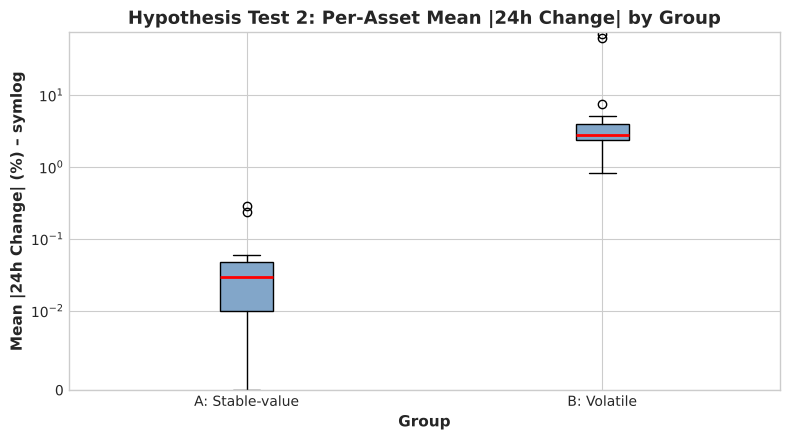

Decision: Reject H0 (p = 3.2476e-10)


In [34]:
grpV = q7_asset.loc[q7_asset['asset_type'] == 'Volatile', 'mean_abs_chg'].values
grpS = q7_asset.loc[q7_asset['asset_type'] == 'Stable-value', 'mean_abs_chg'].values
print(f"Volatile: n = {len(grpV)}, median mean|chg| = {np.median(grpV):.4f}%")
print(f"Stable-value: n = {len(grpS)}, median mean|chg| = {np.median(grpS):.4f}%")
print(f"Shapiro-Wilk p: Volatile = {stats.shapiro(grpV).pvalue:.4e}, Stable = {stats.shapiro(grpS).pvalue:.4e}")

u2 = stats.mannwhitneyu(grpV, grpS, alternative='greater')
r_rb = 2*u2.statistic/(len(grpV)*len(grpS)) - 1
lev2 = stats.levene(daily50.loc[daily50['asset_type']=='Volatile','chg_24h'], daily50.loc[daily50['asset_type']=='Stable-value','chg_24h'])
print(f"\nMann-Whitney U = {u2.statistic:.1f}, one-sided p = {u2.pvalue:.4e}")
print(f"Rank-biserial r = {r_rb:.4f}")
print(f"Levene (daily chg_24h variance) W = {lev2.statistic:.2f}, p = {lev2.pvalue:.4e}")
print(f"Daily chg_24h SD: Volatile = {daily50.loc[daily50['asset_type']=='Volatile','chg_24h'].std():.4f}%, "
      f"Stable-value = {daily50.loc[daily50['asset_type']=='Stable-value','chg_24h'].std():.4f}%")

plt.figure(figsize=(8, 4.5))
plt.boxplot([grpS, grpV], patch_artist=True,
            boxprops=dict(facecolor='#82a6c9'), medianprops=dict(color='red', lw=2))
plt.xticks([1, 2], ['A: Stable-value', 'B: Volatile'])
plt.yscale('symlog', linthresh=0.01); plt.ylim(bottom=0)
plt.title("Hypothesis Test 2: Per-Asset Mean |24h Change| by Group")
plt.xlabel("Group"); plt.ylabel("Mean |24h Change| (%) – symlog")
plt.tight_layout(); plt.show()

record(2, 'Volatile vs stable-value token volatility (A/B)', 'Mann-Whitney U (one-sided) + Levene', 'U', u2.statistic, u2.pvalue, 'Rank-biserial r', r_rb)

* **Statistical decision:** Mann-Whitney U = 918, one-sided **p = 3.2 × 10⁻¹⁰** → **reject H₀**. Levene's test on daily changes (W = 362.7, p ≈ 10⁻⁷⁸) confirms that the variances also differ (daily SD 5.65 % vs 0.07 %).
* **Effect size:** rank-biserial r = **1.00**, the maximum possible: U = 918 = 54 × 17, meaning *every* Volatile asset is more volatile than *every* Stable-value asset.
* **Interpretation:** the separation is complete, which validates the data-driven classification (§5.6) and justifies treating stable-value tokens as near-cash collateral in risk calculations — subject to the liquidity caveat in Q4 (some of them hardly trade).

### Hypothesis Test 3: Are Bitcoin's Daily Returns Normally Distributed?
* **Question:** Can Bitcoin's daily returns be modelled as normal?
* **Hypotheses:** $H_0$: returns come from a normal distribution; $H_1$: they do not.
* **Tests:** **Shapiro-Wilk** (powerful for n < 5000), **Jarque-Bera** (based on skewness & kurtosis), **D'Agostino-Pearson K²**.

n = 183 | skewness = -0.2281 | excess kurtosis = 7.0710
Shapiro-Wilk W = 0.9107, p = 4.3671e-09
Jarque-Bera JB = 358.9934, p = 1.1107e-78
D'Agostino K² = 36.7286, p = 1.0580e-08


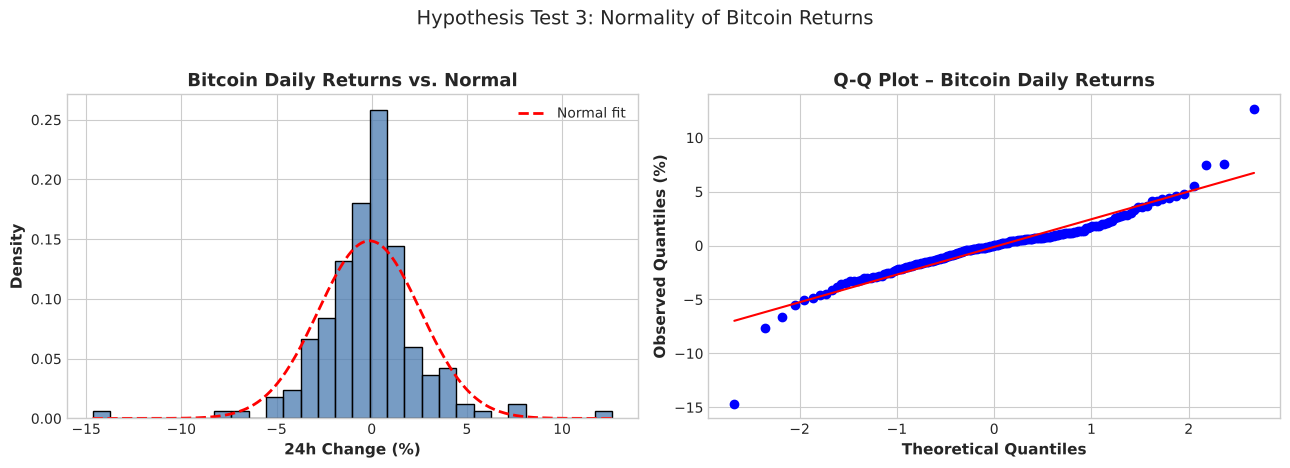

Decision: Reject H0 (p = 4.3671e-09)


In [35]:
sw3 = stats.shapiro(btc_ret); jb3 = stats.jarque_bera(btc_ret); k3 = stats.normaltest(btc_ret)
print(f"n = {len(btc_ret)} | skewness = {btc_ret.skew():.4f} | excess kurtosis = {btc_ret.kurtosis():.4f}")
print(f"Shapiro-Wilk W = {sw3.statistic:.4f}, p = {sw3.pvalue:.4e}")
print(f"Jarque-Bera JB = {jb3.statistic:.4f}, p = {jb3.pvalue:.4e}")
print(f"D'Agostino K² = {k3.statistic:.4f}, p = {k3.pvalue:.4e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(btc_ret, bins=30, stat='density', ax=axes[0], color=LIGHT)
xs = np.linspace(btc_ret.min(), btc_ret.max(), 200)
axes[0].plot(xs, stats.norm.pdf(xs, btc_ret.mean(), btc_ret.std()), 'r--', lw=2, label='Normal fit')
axes[0].set_title("Bitcoin Daily Returns vs. Normal"); axes[0].set_xlabel("24h Change (%)"); axes[0].set_ylabel("Density"); axes[0].legend()
stats.probplot(btc_ret, dist='norm', plot=axes[1])
axes[1].set_title("Q-Q Plot – Bitcoin Daily Returns"); axes[1].set_xlabel("Theoretical Quantiles"); axes[1].set_ylabel("Observed Quantiles (%)")
plt.suptitle("Hypothesis Test 3: Normality of Bitcoin Returns", y=1.03)
plt.tight_layout(); plt.show()

record(3, 'Normality of BTC daily returns', 'Shapiro-Wilk (+ Jarque-Bera, K²)', 'W', sw3.statistic, sw3.pvalue, 'Excess kurtosis', btc_ret.kurtosis())

* **Statistical decision:** all three tests reject normality — Shapiro-Wilk W = 0.911, **p = 4.4 × 10⁻⁹**; Jarque-Bera p ≈ 10⁻⁷⁸; D'Agostino p = 1.1 × 10⁻⁸ → **reject H₀**.
* **Interpretation:** skewness is small (−0.23) but excess kurtosis is **7.07**: the problem is fat tails, visible in the Q-Q plot as points far off the line at both ends (e.g. −14.7 %, +12.6 %).
* **Consequence for this study:** tests that assume normal data on small groups (e.g. ANOVA in Test 5) are backed up with non-parametric alternatives; normal-based risk measures would understate Bitcoin's extreme days.

### Hypothesis Test 4: Did Bitcoin Have a Non-Zero Average Daily Return?
* **Question:** Over the study period, was Bitcoin's mean daily return significantly different from 0 (i.e. a statistically reliable trend)?
* **Hypotheses:** $H_0: \mu = 0$; $H_1: \mu \ne 0$.
* **Test:** **One-sample t-test** — justified by the CLT (n is large, §6.4) even though returns are non-normal (Test 3); cross-checked with the **Wilcoxon signed-rank test** (median = 0). Effect size: $d = \bar x / s$.

In [36]:
t4 = stats.ttest_1samp(btc_ret, 0)
w4 = stats.wilcoxon(btc_ret)
d4 = btc_ret.mean() / btc_ret.std()
print(f"n = {len(btc_ret)}, mean = {btc_ret.mean():.4f}%, median = {btc_ret.median():.4f}%")
print(f"One-sample t = {t4.statistic:.4f}, p = {t4.pvalue:.4f}")
print(f"Wilcoxon W = {w4.statistic:.1f}, p = {w4.pvalue:.4f}")
print(f"95% CI for mean (from §6.5): [{ci_t[0]:.4f}%, {ci_t[1]:.4f}%]")
print(f"Effect size d = {d4:.4f}")
record(4, 'BTC mean daily return = 0?', 'One-sample t (+ Wilcoxon)', 't', t4.statistic, t4.pvalue, "Cohen's d", d4)

n = 183, mean = -0.1212%, median = 0.0200%
One-sample t = -0.6109, p = 0.5420
Wilcoxon W = 7903.5, p = 0.5523
95% CI for mean (from §6.5): [-0.5126%, 0.2702%]
Effect size d = -0.0452
Decision: Fail to reject H0 (p = 5.4201e-01)


* **Statistical decision:** t = −0.61, **p = 0.542**; Wilcoxon p = 0.552 → **fail to reject H₀**.
* **Effect size:** d = −0.045 (negligible). The 95 % CI for the mean daily return, [−0.51 %, +0.27 %], includes 0.
* **Interpretation:** although Bitcoin lost about 26 % over the period (Q9), that decline is small compared with day-to-day noise; the data do **not** show a statistically reliable average daily drift. "Failing to reject" does not prove the mean is zero — with this volatility, about 183 days are simply too few to detect a drift of this size.

### Hypothesis Test 5: Day-of-Week Effect on Bitcoin Returns
* **Question:** Does Bitcoin's mean daily return differ across the 7 weekdays?
* **Hypotheses:** $H_0: \mu_{Mon} = \dots = \mu_{Sun}$; $H_1$: at least one differs.
* **Primary test: Kruskal-Wallis H** — Hypothesis Test 3 shows Bitcoin returns are strongly non-normal (heavy tails), and each weekday group has only ~26 observations, so the normality assumption of ANOVA cannot be relied on. **One-way ANOVA** (with Levene check) is reported alongside for reference. Effect sizes: $\eta^2 = SS_{between}/SS_{total}$ (ANOVA) and $\varepsilon^2 = H/(n-1)$ (Kruskal-Wallis).
* **Post-hoc:** if $H_0$ is rejected, pairwise Mann-Whitney tests with **Bonferroni** correction (21 pairs) identify which days differ.

n per weekday: {'Monday': 27, 'Tuesday': 27, 'Wednesday': 26, 'Thursday': 26, 'Friday': 27, 'Saturday': 26, 'Sunday': 24}
Levene p = 0.1633
ANOVA F = 1.9499, p = 0.0753
Kruskal-Wallis H = 15.3741, p = 0.0175
Eta squared = 0.0623
Epsilon squared (KW) = 0.0845
Post-hoc pairwise Mann-Whitney (5 smallest p-values):


,Pair,Median 1,Median 2,raw p,Bonferroni p
2,Monday vs Thursday,1.1000,-1.3000,0.0016,0.0334
5,Monday vs Sunday,1.1000,-0.2600,0.0068,0.1421
0,Monday vs Tuesday,1.1000,-0.7600,0.0121,0.2546
3,Monday vs Friday,1.1000,0.0600,0.0140,0.2944
4,Monday vs Saturday,1.1000,0.1950,0.0222,0.4669


Pairs significant after Bonferroni: 1 of 21


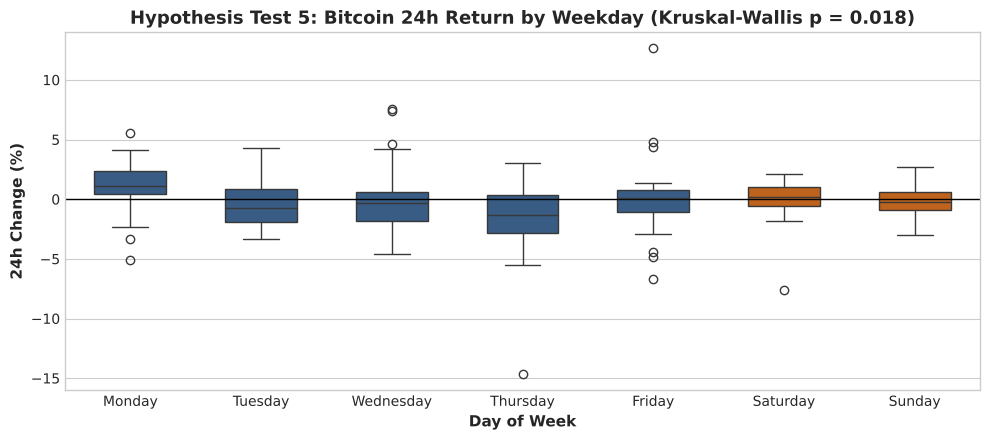

Decision: Reject H0 (p = 1.7538e-02)


In [37]:
groups5 = [btc_daily.loc[btc_daily['day_of_week'] == d, 'chg_24h'].values for d in order]
print("n per weekday:", dict(zip(order, [len(g) for g in groups5])))
lev5 = stats.levene(*groups5)
f5 = stats.f_oneway(*groups5)
kw5 = stats.kruskal(*groups5)
grand = btc_daily['chg_24h'].mean()
ss_between = sum(len(g)*(g.mean()-grand)**2 for g in groups5)
ss_total = ((btc_daily['chg_24h'] - grand)**2).sum()
eta2 = ss_between / ss_total
print(f"Levene p = {lev5.pvalue:.4f}")
print(f"ANOVA F = {f5.statistic:.4f}, p = {f5.pvalue:.4f}")
print(f"Kruskal-Wallis H = {kw5.statistic:.4f}, p = {kw5.pvalue:.4f}")
print(f"Eta squared = {eta2:.4f}")
eps2 = kw5.statistic / (len(btc_daily) - 1)
print(f"Epsilon squared (KW) = {eps2:.4f}")

from itertools import combinations
post = []
for d1_, d2_ in combinations(order, 2):
    g1_ = btc_daily.loc[btc_daily['day_of_week'] == d1_, 'chg_24h']; g2_ = btc_daily.loc[btc_daily['day_of_week'] == d2_, 'chg_24h']
    p_ = stats.mannwhitneyu(g1_, g2_, alternative='two-sided').pvalue
    post.append({'Pair': f"{d1_} vs {d2_}", 'Median 1': g1_.median(), 'Median 2': g2_.median(), 'raw p': p_, 'Bonferroni p': min(p_*21, 1.0)})
post = pd.DataFrame(post).sort_values('raw p')
print("Post-hoc pairwise Mann-Whitney (5 smallest p-values):")
display(post.head(5))
print(f"Pairs significant after Bonferroni: {(post['Bonferroni p'] < ALPHA).sum()} of 21")

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=btc_daily, x='day_of_week', y='chg_24h', order=order, palette=[BLUE]*5 + [ORANGE]*2, width=0.55)
plt.axhline(0, color='black', lw=1)
plt.title(f"Hypothesis Test 5: Bitcoin 24h Return by Weekday (Kruskal-Wallis p = {kw5.pvalue:.3f})")
plt.xlabel("Day of Week"); plt.ylabel("24h Change (%)")
plt.tight_layout(); plt.show()

record(5, 'Day-of-week effect on BTC returns', 'Kruskal-Wallis (+ ANOVA, Bonferroni post-hoc)', 'H', kw5.statistic, kw5.pvalue, 'Epsilon²', eps2)

* **Statistical decision (primary, Kruskal-Wallis):** H = 15.37, **p = 0.0175 < 0.05** → **reject H₀**: at least one weekday's return distribution differs.
* **Reference (ANOVA):** F = 1.95, p = 0.075 — not significant. The two tests disagree because ANOVA compares means and is sensitive to the fat-tailed outliers (Test 3), while Kruskal-Wallis compares ranks.
* **Post-hoc:** only **Monday vs Thursday** remains significant after Bonferroni correction (Bonferroni p = 0.033; medians +1.10 % vs −1.30 %); the other 20 pairs are not.
* **Effect size:** ε² = 0.085 (η² = 0.062) — weekday explains only ~6–8 % of the variation in daily returns.
* **Interpretation:** there is **weak, fragile evidence** of a Monday-vs-Thursday difference in this sample. With one significant pair out of 21, small groups (24–27 days) and a borderline overall p-value, this should be treated as a hypothesis to re-check on more data, not as a trading rule.

### Hypothesis Test 6: Is a "Big-Move Day" Independent of Asset Size? (Chi-square)
* **Question:** Is the chance that a Volatile asset moves more than **5 %** in a day independent of its market-cap tier?
* **Variables:** `size_tier` (asset's median market cap in tertiles: Small / Mid / Large), `big_move` = |24h change| > 5 %.
* **Hypotheses:** $H_0$: big-move occurrence and size tier are independent; $H_1$: they are associated.
* **Test:** **Pearson χ² test of independence**, expected counts ≥ 5 checked; effect size **Cramér's V**.
* **Caveat:** asset-days of the same asset are not fully independent, so the p-value is optimistic; the effect size is the more reliable read.

big_move,Big move (>5%),Normal day
size_tier,,
Small,155,976
Mid,268,1373
Large,151,1293


Expected counts under H0:


big_move,Big move (>5%),Normal day
size_tier,,
Small,154.0000,977.0000
Mid,223.4000,"1,417.6000"
Large,196.6000,"1,247.4000"


Min expected count = 154.0 (OK)
Chi² = 22.5480, df = 2, p = 1.2699e-05, Cramér's V = 0.0731


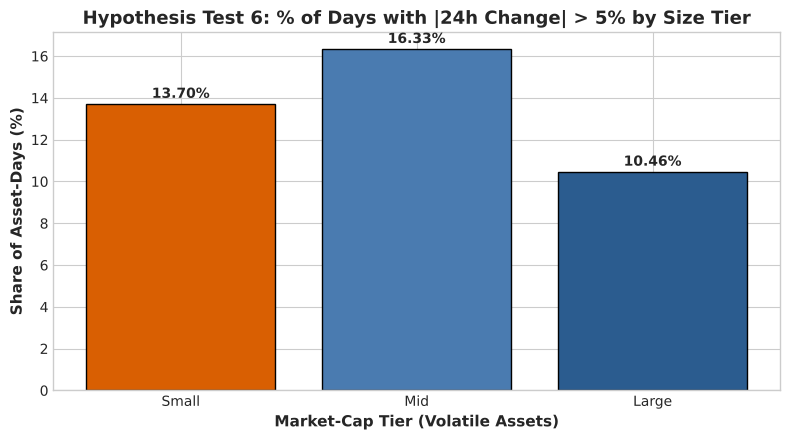

Assets per tier: {'Small': 18, 'Mid': 18, 'Large': 18}
Decision: Reject H0 (p = 1.2699e-05)


In [38]:
vol_only = daily50[daily50['asset_type'] == 'Volatile'].copy()
asset_size = vol_only.groupby('name')['market_cap'].median()
tiers = pd.qcut(asset_size, 3, labels=['Small', 'Mid', 'Large'])
vol_only['size_tier'] = vol_only['name'].map(tiers)
vol_only['big_move'] = np.where(vol_only['abs_chg_24h'] > 5, 'Big move (>5%)', 'Normal day')
ct6 = pd.crosstab(vol_only['size_tier'], vol_only['big_move'])
chi2_6, p6, dof6, exp6 = stats.chi2_contingency(ct6)
V6 = np.sqrt(chi2_6 / (ct6.values.sum() * (min(ct6.shape) - 1)))

display(ct6)
print("Expected counts under H0:"); display(pd.DataFrame(exp6, index=ct6.index, columns=ct6.columns).round(1))
print(f"Min expected count = {exp6.min():.1f} ({'OK' if exp6.min() >= 5 else 'VIOLATED'})")
print(f"Chi² = {chi2_6:.4f}, df = {dof6}, p = {p6:.4e}, Cramér's V = {V6:.4f}")
rate6 = pd.crosstab(vol_only['size_tier'], vol_only['big_move'], normalize='index')['Big move (>5%)']*100

plt.figure(figsize=(8, 4.5))
bars = plt.bar(rate6.index.astype(str), rate6.values, color=[ORANGE, LIGHT, BLUE], edgecolor='black')
for b in bars:
    plt.text(b.get_x()+b.get_width()/2, b.get_height()+0.3, f"{b.get_height():.2f}%", ha='center', fontweight='bold')
plt.title("Hypothesis Test 6: % of Days with |24h Change| > 5% by Size Tier")
plt.xlabel("Market-Cap Tier (Volatile Assets)"); plt.ylabel("Share of Asset-Days (%)")
plt.tight_layout(); plt.show()
print("Assets per tier:", tiers.value_counts().to_dict())

record(6, 'Big-move days vs size tier', 'Pearson χ² independence', 'χ²', chi2_6, p6, "Cramér's V", V6)

* **Assumption check:** all expected counts ≥ 154 (well above 5).
* **Statistical decision:** χ² = 22.55, df = 2, **p = 1.3 × 10⁻⁵** → **reject H₀**.
* **Effect size:** Cramér's V = **0.073** — a **very weak** association.
* **Interpretation:** the share of days with a >5 % move is 13.70 % (Small), **16.33 % (Mid)** and **10.46 % (Large)**. Large assets have big-move days less often, but the relationship is not monotonic (mid-sized assets are the most jumpy). Combined with the non-significant size–volatility correlation in Q8 and the caveat that asset-days are not fully independent, the practical conclusion is that size has only a **small** effect on the frequency of big moves.

### Hypothesis Test 7: Is Bitcoin's Trading Volume Correlated With the Size of Its Daily Move?
* **Question:** On days when Bitcoin moves more (in either direction), is its 24h volume higher?
* **Hypotheses:** $H_0: \rho_s = 0$; $H_1: \rho_s > 0$ (one-sided; volume–volatility theory predicts a positive link).
* **Test:** **Spearman rank correlation** (robust to the heavy tails and to the skew of volume). Pearson on log volume reported for comparison.

n = 183 days
Spearman rho = 0.4619, one-sided p = 2.3239e-11
Pearson r (|chg| vs log10 vol) = 0.5571, p = 2.5968e-16


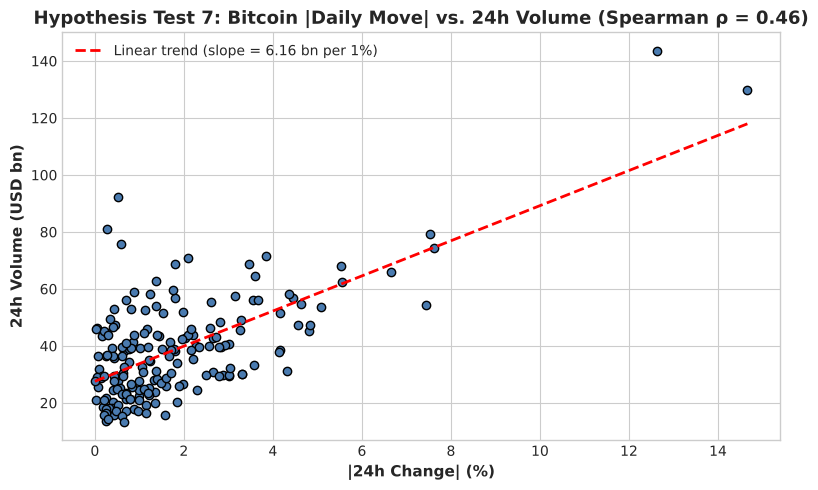

Decision: Reject H0 (p = 2.3239e-11)


In [39]:
btc_v = daily[daily['name'] == 'Bitcoin'][['date', 'abs_chg_24h', 'vol_24h']].dropna()
rho7, p7_two = stats.spearmanr(btc_v['abs_chg_24h'], btc_v['vol_24h'])
p7 = p7_two/2 if rho7 > 0 else 1 - p7_two/2
pr7 = stats.pearsonr(btc_v['abs_chg_24h'], np.log10(btc_v['vol_24h']))
print(f"n = {len(btc_v)} days")
print(f"Spearman rho = {rho7:.4f}, one-sided p = {p7:.4e}")
print(f"Pearson r (|chg| vs log10 vol) = {pr7.statistic:.4f}, p = {pr7.pvalue:.4e}")

plt.figure(figsize=(8, 5))
plt.scatter(btc_v['abs_chg_24h'], btc_v['vol_24h']/1e9, color=LIGHT, edgecolor='black')
z = np.polyfit(btc_v['abs_chg_24h'], btc_v['vol_24h']/1e9, 1)
xx = np.linspace(0, btc_v['abs_chg_24h'].max(), 50)
plt.plot(xx, np.polyval(z, xx), 'r--', lw=2, label=f'Linear trend (slope = {z[0]:.2f} bn per 1%)')
plt.title(f"Hypothesis Test 7: Bitcoin |Daily Move| vs. 24h Volume (Spearman ρ = {rho7:.2f})")
plt.xlabel("|24h Change| (%)"); plt.ylabel("24h Volume (USD bn)"); plt.legend()
plt.tight_layout(); plt.show()

record(7, 'BTC |move| vs volume', 'Spearman rank correlation (one-sided)', 'ρ', rho7, p7, 'Spearman ρ', rho7)

* **Statistical decision:** Spearman **ρ = 0.462**, one-sided **p = 2.3 × 10⁻¹¹** (n = 183 days) → **reject H₀**. Pearson r between |move| and log volume is 0.557.
* **Interpretation:** on days when Bitcoin moves more, its volume is clearly higher (linear trend ≈ +\$6.2 bn of volume per extra 1 % of absolute move). This is a moderate positive association and agrees with the cross-asset result in Q14.

### Summary of all hypothesis tests (generated from the computed results)

In [40]:
summary_tests = pd.DataFrame(test_results)
summary_tests['p-value'] = summary_tests['p-value'].map(lambda p: f"{p:.3e}")
display(summary_tests.set_index('Test'))

,Question,Statistical test,Statistic,p-value,Effect size,Decision (α = 0.05)
Test,,,,,,
1,Weekend vs weekday total volume (A/B),"Welch t (+ Mann-Whitney, permutation)",t = -5.0288,5.895e-06,Cohen's d = -1.0544,Reject H0
2,Volatile vs stable-value token volatility (A/B),Mann-Whitney U (one-sided) + Levene,U = 918.0000,3.248e-10,Rank-biserial r = 1.0000,Reject H0
3,Normality of BTC daily returns,"Shapiro-Wilk (+ Jarque-Bera, K²)",W = 0.9107,4.367e-09,Excess kurtosis = 7.0710,Reject H0
4,BTC mean daily return = 0?,One-sample t (+ Wilcoxon),t = -0.6109,5.420e-01,Cohen's d = -0.0452,Fail to reject H0
5,Day-of-week effect on BTC returns,"Kruskal-Wallis (+ ANOVA, Bonferroni post-hoc)",H = 15.3741,1.754e-02,Epsilon² = 0.0845,Reject H0
6,Big-move days vs size tier,Pearson χ² independence,χ² = 22.5480,1.270e-05,Cramér's V = 0.0731,Reject H0
7,BTC |move| vs volume,Spearman rank correlation (one-sided),ρ = 0.4619,2.324e-11,Spearman ρ = 0.4619,Reject H0


**Overall:** 6 of 7 null hypotheses are rejected. The strongest, most practically important results are the **weekend volume drop** (Test 1, large effect), the **complete volatility separation of stable-value tokens** (Test 2), **fat-tailed Bitcoin returns** (Test 3) and the **volume–volatility link** (Test 7). Test 6 is statistically significant but practically very weak (V = 0.07), Test 5 is borderline and driven by one weekday pair, and Test 4 finds no reliable daily drift in Bitcoin.

## 9. Regression & Prediction: Estimating an Asset's 24h Trading Volume

### 9.1 Why regression, and why this target?
* **Technique chosen: Multiple Linear Regression (OLS)**, benchmarked against a Random Forest regressor.
* **Target:** $\log_{10}$(24h volume). Volume is a continuous quantity, so this is a **regression** problem. The log is used because volume spans ~6 orders of magnitude and is extremely right-skewed (§6.2); on the log scale the relationship with log market cap is close to linear and coefficients become **elasticities**.
* **Use case:** given an asset's size, the size of its recent moves, its type and the day type, estimate the volume it *should* trade. Large positive residuals flag **abnormal trading activity** (useful for exchanges/risk teams).
* **Why OLS first:** coefficients are directly interpretable and come with standard errors, confidence intervals and p-values; the Random Forest checks whether a flexible non-linear model does materially better.

### 9.2 Model specification
$$\log_{10}(\text{Vol}_{i,t}) = \beta_0 + \beta_1 \log_{10}(\text{MCap}_{i,t}) + \beta_2 \ln(1+|\Delta_{24h}|_{i,t}) + \beta_3 \ln(1+|\Delta_{7d}|_{i,t}) + \beta_4\,\text{Stable}_i + \beta_5\,\text{Weekend}_t + \varepsilon_{i,t}$$

**Why $\ln(1+|\Delta|)$ instead of raw $|\Delta|$:** the absolute moves are extremely heavy-tailed (|7d| change up to 6,038 % for RaveDAO in the panel, §5.5). With raw values, a handful of such rows act as high-leverage points; in a trial run with raw features, holding out the assets containing them gave a cross-validated $R^2$ of −62. The log1p transform keeps the ordering of moves, handles zeros, and removes that leverage (the transform choice was made on this diagnostic, not on test-set performance).

**Data:** 50-asset daily panel; rows with zero volume removed (BlackRock BUIDL reports no exchange volume — log undefined).
**Split:** **time-based** — the earliest 80 % of days for training, the latest 20 % for testing. A random split would leak information because the same asset appears on adjacent days in both sets.

> **Scope note:** $|\Delta_{24h}|$ is observed over the same 24h window as the volume, so this is an *explanatory / nowcasting* model (what volume is consistent with today's conditions), not a forecast of tomorrow's volume.

In [41]:
features = ['log_mcap', 'log1p_abs_chg_24h', 'log1p_abs_chg_7d', 'is_stable', 'is_weekend_int']
reg = daily50[daily50['vol_24h'] > 0].copy()
reg['log1p_abs_chg_24h'] = np.log1p(reg['abs_chg_24h'])
reg['log1p_abs_chg_7d'] = np.log1p(reg['abs_chg_7d'])
reg['is_stable'] = (reg['asset_type'] == 'Stable-value').astype(int)
reg['is_weekend_int'] = reg['is_weekend'].astype(int)
reg = reg.dropna(subset=features + ['log_vol']).sort_values('date')

dates_sorted = np.sort(reg['date'].unique())
cutoff = dates_sorted[int(len(dates_sorted)*0.8)]
train, test = reg[reg['date'] < cutoff], reg[reg['date'] >= cutoff]
X_train, y_train = train[features], train['log_vol']
X_test, y_test = test[features], test['log_vol']
print(f"Rows used: {len(reg):,} (removed {int((daily50['vol_24h']==0).sum())} zero-volume rows)")
print(f"Train: {len(train):,} rows, {train['date'].nunique()} days ({train['date'].min().date()} -> {train['date'].max().date()})")
print(f"Test : {len(test):,} rows, {test['date'].nunique()} days ({test['date'].min().date()} -> {test['date'].max().date()})")
display(reg[features + ['log_vol']].describe().T)

Rows used: 5,300 (removed 100 zero-volume rows)
Train: 4,222 rows, 86 days (2026-01-26 -> 2026-04-25)
Test : 1,078 rows, 22 days (2026-04-26 -> 2026-05-19)


,count,mean,std,min,25%,50%,75%,max
log_mcap,"5,300.0000",9.8576,0.6365,9.1743,9.4208,9.6383,10.0168,12.2515
log1p_abs_chg_24h,"5,300.0000",0.8409,0.7284,0.0000,0.1398,0.7348,1.3507,5.2083
log1p_abs_chg_7d,"5,300.0000",1.3135,1.0164,0.0000,0.3293,1.2988,2.0451,8.7060
is_stable,"5,300.0000",0.2045,0.4034,0.0000,0.0000,0.0000,0.0000,1.0000
is_weekend_int,"5,300.0000",0.2683,0.4431,0.0000,0.0000,0.0000,1.0000,1.0000
log_vol,"5,300.0000",8.1798,1.1450,0.7490,7.6012,8.1920,8.6948,11.3636


### 9.3 Assumption checks before fitting
1. **Linearity** – scatter of the target against each continuous predictor.
2. **Multicollinearity** – Variance Inflation Factor (VIF < 5 acceptable).

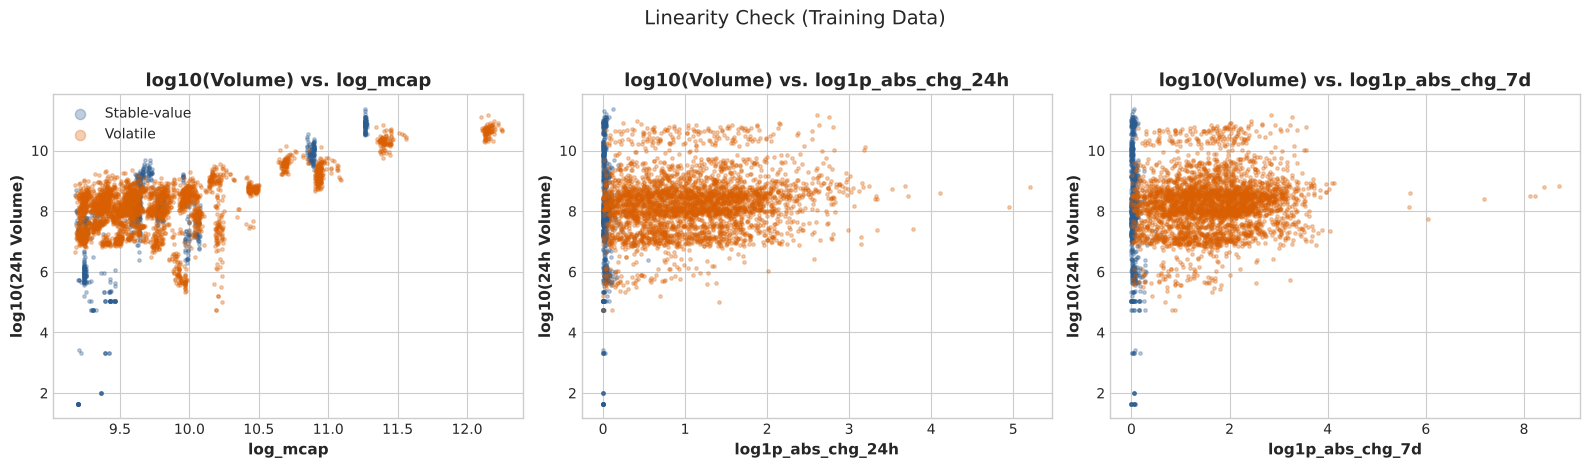

,Feature,VIF
1,log_mcap,1.0071
2,log1p_abs_chg_24h,1.7231
3,log1p_abs_chg_7d,1.9383
4,is_stable,1.8686
5,is_weekend_int,1.0072


In [42]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, f in zip(axes, ['log_mcap', 'log1p_abs_chg_24h', 'log1p_abs_chg_7d']):
    for t, g in train.groupby('asset_type'):
        ax.scatter(g[f], g['log_vol'], s=6, alpha=0.3, color=PALETTE_TYPE[t], label=t)
    ax.set_title(f"log10(Volume) vs. {f}")
    ax.set_xlabel(f); ax.set_ylabel("log10(24h Volume)")
axes[0].legend(markerscale=3)
plt.suptitle("Linearity Check (Training Data)", y=1.03)
plt.tight_layout(); plt.show()

Xc = sm.add_constant(X_train.astype(float))
vif = pd.DataFrame({'Feature': Xc.columns, 'VIF': [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]})
display(vif[vif['Feature'] != 'const'])

**Assumption checks:**
* **Linearity:** log10 volume rises roughly linearly with log10 market cap. The two move features show a weaker, noisy but positive relationship (examined via the coefficients below).
* **Multicollinearity:** all VIFs are below 2 (max 1.94), well under the threshold of 5 — each predictor carries separate information.

### 9.4 Fitting the OLS model (statsmodels) — coefficients, CIs and p-values

In [43]:
ols = sm.OLS(y_train, Xc).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                log_vol   R-squared:                       0.462
Model:                            OLS   Adj. R-squared:                  0.461
Method:                 Least Squares   F-statistic:                     724.2
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:04:29   Log-Likelihood:                -5276.8
No. Observations:                4222   AIC:                         1.057e+04
Df Residuals:                    4216   BIC:                         1.060e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -4.0275      0.20

,coef,CI low,CI high,p-value,Interpretation
log_mcap,1.2037,1.1634,1.2439,0.0000,1% higher market cap -> 1.204% higher volume (...
log1p_abs_chg_24h,0.1969,0.1519,0.2419,0.0000,Doubling (1+|24h move|) -> volume x1.369
log1p_abs_chg_7d,0.1397,0.1048,0.1746,0.0000,Doubling (1+|7d move|) -> volume x1.250
is_stable,0.1768,0.0903,0.2633,0.0001,Stable-value token -> volume x1.50 vs. a volat...
is_weekend_int,-0.1355,-0.1933,-0.0777,0.0000,Weekend -> volume x0.732


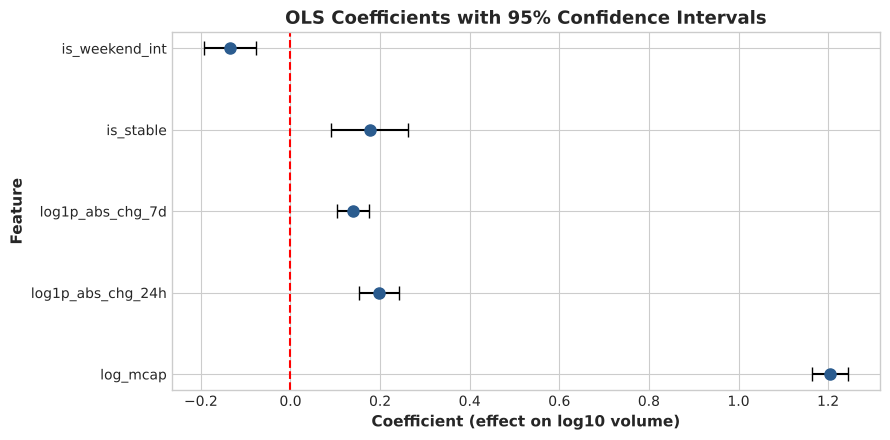

In [44]:
coef = pd.DataFrame({'coef': ols.params, 'CI low': ols.conf_int()[0], 'CI high': ols.conf_int()[1], 'p-value': ols.pvalues}).drop('const')
coef['Interpretation'] = [
    f"1% higher market cap -> {coef.loc['log_mcap','coef']:.3f}% higher volume (elasticity)",
    f"Doubling (1+|24h move|) -> volume x{10**(coef.loc['log1p_abs_chg_24h','coef']*np.log(2)):.3f}",
    f"Doubling (1+|7d move|) -> volume x{10**(coef.loc['log1p_abs_chg_7d','coef']*np.log(2)):.3f}",
    f"Stable-value token -> volume x{10**coef.loc['is_stable','coef']:.2f} vs. a volatile token of equal size",
    f"Weekend -> volume x{10**coef.loc['is_weekend_int','coef']:.3f}",
]
display(coef)

plt.figure(figsize=(9, 4.5))
plt.errorbar(coef['coef'], coef.index, xerr=[coef['coef']-coef['CI low'], coef['CI high']-coef['coef']],
             fmt='o', color=BLUE, ecolor='black', capsize=5, markersize=8)
plt.axvline(0, color='red', ls='--')
plt.title("OLS Coefficients with 95% Confidence Intervals")
plt.xlabel("Coefficient (effect on log10 volume)"); plt.ylabel("Feature")
plt.tight_layout(); plt.show()

**Interpretation of the fitted model (training data, n = 4,222):**
* The model explains **R² = 0.462** of the variation in log volume (F = 724, p ≈ 0); all five coefficients are significant at p ≤ 0.0001.
* **Size (β = 1.204, 95 % CI [1.163, 1.244]):** a 1 % larger market cap goes with about **1.2 % higher volume**. Because the elasticity is slightly above 1, larger assets trade slightly more than proportionally to their size, holding the other variables constant.
* **Size of moves:** doubling (1 + |24h change|) multiplies expected volume by **1.37**; doubling (1 + |7d change|) multiplies it by **1.25**. This is the volume–volatility effect of Q14/Test 7, now controlled for size.
* **Weekend (β = −0.136):** volume is about **27 % lower** at weekends (×0.73), other factors equal — consistent with Test 1.
* **Stable-value (β = +0.177, ×1.50):** this must be read *together with* the move terms. Stable tokens have near-zero moves, so the move terms predict very low volume for them; the positive dummy offsets that. It does **not** mean every stablecoin trades heavily — Q4 showed the group is split between very liquid and almost untraded tokens.

### 9.5 Residual diagnostics
* **Homoscedasticity:** residuals vs. fitted should show constant spread.
* **Normality of residuals:** Q-Q plot.
* **Independence:** Durbin-Watson statistic (≈2 means no autocorrelation).

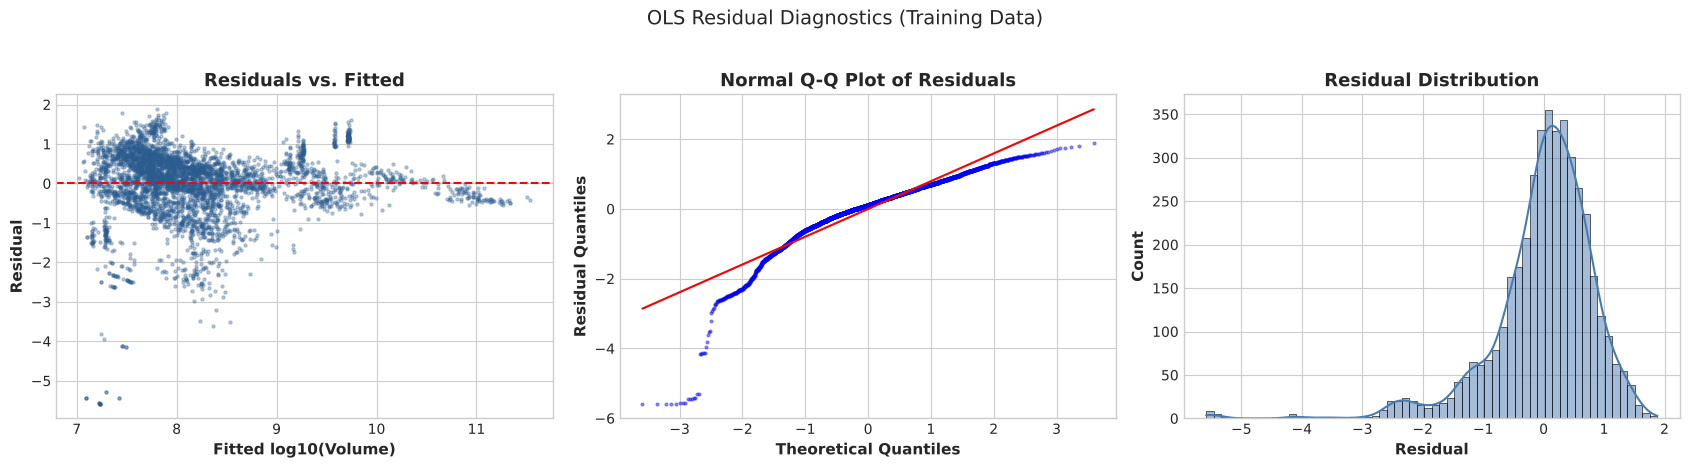

Durbin-Watson = 1.892
Residual skewness = -1.820, excess kurtosis = 7.320


In [45]:
resid, fitted = ols.resid, ols.fittedvalues
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(fitted, resid, s=5, alpha=0.3, color=BLUE); axes[0].axhline(0, color='red', ls='--')
axes[0].set_title("Residuals vs. Fitted"); axes[0].set_xlabel("Fitted log10(Volume)"); axes[0].set_ylabel("Residual")
stats.probplot(resid, dist='norm', plot=axes[1]); axes[1].get_lines()[0].set(markersize=2, alpha=0.4)
axes[1].set_title("Normal Q-Q Plot of Residuals"); axes[1].set_xlabel("Theoretical Quantiles"); axes[1].set_ylabel("Residual Quantiles")
sns.histplot(resid, bins=60, ax=axes[2], color=LIGHT, kde=True)
axes[2].set_title("Residual Distribution"); axes[2].set_xlabel("Residual"); axes[2].set_ylabel("Count")
plt.suptitle("OLS Residual Diagnostics (Training Data)", y=1.03)
plt.tight_layout(); plt.show()

dw = durbin_watson(resid.values)
print(f"Durbin-Watson = {dw:.3f}")
print(f"Residual skewness = {stats.skew(resid):.3f}, excess kurtosis = {stats.kurtosis(resid):.3f}")

**Diagnostics:**
* **Independence:** Durbin-Watson = 1.89, close to 2 — little residual autocorrelation in row order.
* **Normality:** residuals are **left-skewed** (skewness −1.82, excess kurtosis 7.32). The Q-Q plot shows a long lower tail: a group of assets trade far *less* than the model expects (the residual-vs-fitted plot shows these at fitted values around 7–8; §9.8 identifies them).
* **Homoscedasticity:** spread is not constant — it is larger at lower fitted values.
* **Consequence:** with n = 4,222 the coefficient estimates remain unbiased and the CLT supports the inference, but p-values should be taken as approximate. These violations also suggest that a single linear equation cannot fit the very different kinds of tokens in the dataset — which the Random Forest comparison below tests.

### 9.6 Prediction on the held-out (later) period and model comparison
Metrics on the log10 scale: $R^2$, RMSE, MAE. Because an error of 0.3 on log10 scale = a factor of 10^0.3 ≈ 2×, we also report the **median multiplicative error** $10^{\text{median}|e|}$.
Baseline = predict the training mean for everyone.

In [46]:
lin = LinearRegression().fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(X_train, y_train)

preds = {'Baseline (train mean)': np.full(len(y_test), y_train.mean()),
         'Linear Regression (OLS)': lin.predict(X_test),
         'Random Forest': rf.predict(X_test)}
rows = []
for name_, p_ in preds.items():
    e = y_test.values - p_
    rows.append({'Model': name_, 'R² (test)': r2_score(y_test, p_),
                 'RMSE (log10)': np.sqrt(mean_squared_error(y_test, p_)),
                 'MAE (log10)': mean_absolute_error(y_test, p_),
                 'Median multiplicative error (×)': 10**np.median(np.abs(e))})
metrics = pd.DataFrame(rows).set_index('Model')
metrics.loc['Linear Regression (OLS)', 'R² (train)'] = r2_score(y_train, lin.predict(X_train))
metrics.loc['Random Forest', 'R² (train)'] = r2_score(y_train, rf.predict(X_train))
display(metrics)

,R² (test),RMSE (log10),MAE (log10),Median multiplicative error (×),R² (train)
Model,,,,,
Baseline (train mean),-0.0021,1.1196,0.7963,3.5414,NaN
Linear Regression (OLS),0.4865,0.8015,0.5701,2.7089,0.4620
Random Forest,0.6732,0.6394,0.4284,1.9291,0.8485


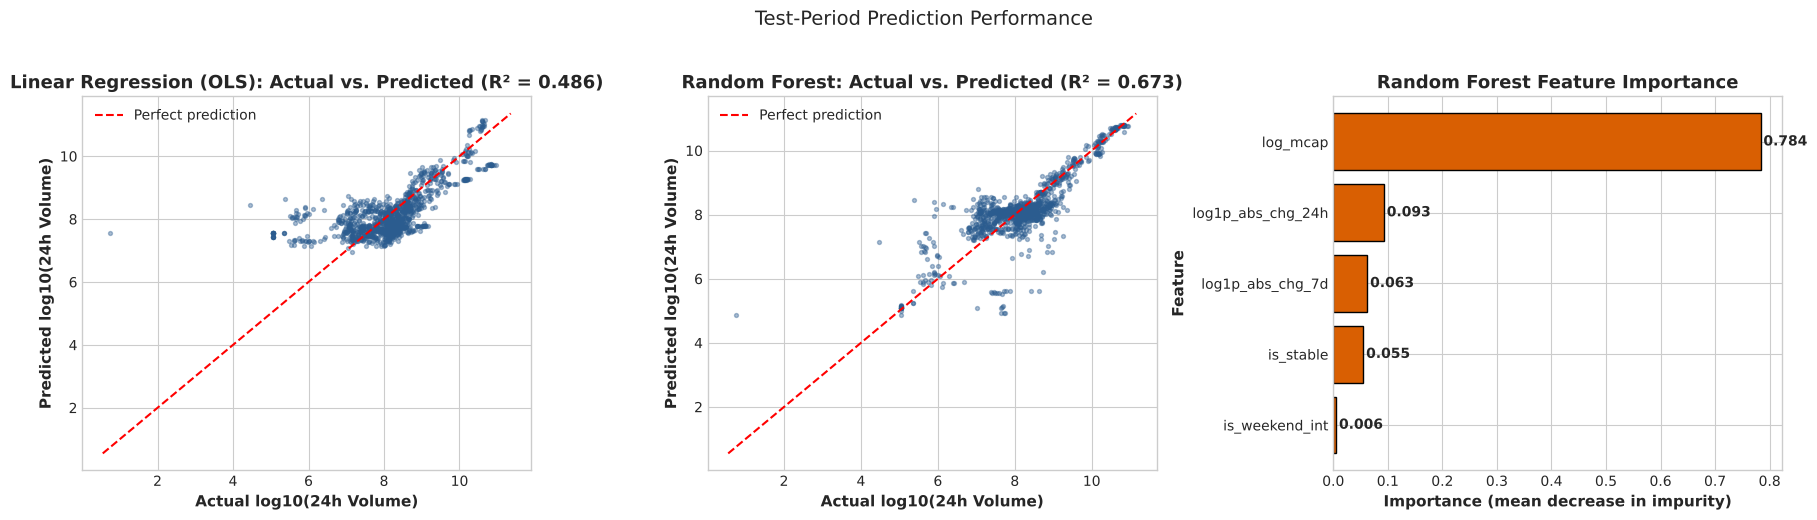

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name_, p_) in zip(axes[:2], list(preds.items())[1:]):
    ax.scatter(y_test, p_, s=8, alpha=0.4, color=BLUE)
    lim = [min(y_test.min(), p_.min())-0.2, max(y_test.max(), p_.max())+0.2]
    ax.plot(lim, lim, 'r--', lw=1.5, label='Perfect prediction')
    ax.set_title(f"{name_}: Actual vs. Predicted (R² = {r2_score(y_test, p_):.3f})")
    ax.set_xlabel("Actual log10(24h Volume)"); ax.set_ylabel("Predicted log10(24h Volume)"); ax.legend()

imp = pd.Series(rf.feature_importances_, index=features).sort_values()
axes[2].barh(imp.index, imp.values, color=ORANGE, edgecolor='black')
for i_, v_ in enumerate(imp.values): axes[2].text(v_+0.005, i_, f"{v_:.3f}", va='center', fontweight='bold')
axes[2].set_title("Random Forest Feature Importance"); axes[2].set_xlabel("Importance (mean decrease in impurity)"); axes[2].set_ylabel("Feature")
plt.suptitle("Test-Period Prediction Performance", y=1.03)
plt.tight_layout(); plt.show()

**Prediction results on the later, unseen period (26 Apr → 19 May, 1,078 asset-days):**
| Model | Test R² | RMSE (log10) | Median error factor |
|:---|:---:|:---:|:---:|
| Baseline (train mean) | −0.002 | 1.120 | 3.54× |
| **Linear Regression (OLS)** | **0.487** | 0.802 | 2.71× |
| Random Forest | **0.673** | 0.639 | 1.93× |

* OLS clearly beats the baseline, and its test R² (0.487) is as good as its training R² (0.462): **no overfitting**, the relationships held in the later period.
* The Random Forest is more accurate on the test period (median prediction within a factor of 1.93 of the actual volume) but fits the training data much more closely (train R² 0.849 vs test 0.673).
* RF importance confirms the OLS story: **market cap dominates (0.784)**, followed by the 24h move (0.093), the 7d move (0.063), asset type (0.055) and weekend (0.006).

### 9.7 Robustness: can the model generalise to *unseen assets*?
The time split still shows the model the same assets it trained on. **GroupKFold (5 folds, grouped by asset)** holds out entire assets, which is the harder, more honest test of generalisation. RMSE is reported next to $R^2$ because $R^2$ depends on how varied the held-out assets are (a fold of similar assets has a small Var(y), which makes $R^2$ look poor even when errors are moderate).

In [48]:
gkf = GroupKFold(n_splits=5)
rf_cv = RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1)
cv_rows = []
for k, (tr_i, te_i) in enumerate(gkf.split(reg, groups=reg['name'])):
    tr_, te_ = reg.iloc[tr_i], reg.iloc[te_i]
    row = {'Fold': k+1, 'Held-out assets': te_['name'].nunique(), 'Var(y) in fold': te_['log_vol'].var()}
    for lbl, mdl in [('LR', LinearRegression()), ('RF', rf_cv)]:
        p_ = mdl.fit(tr_[features], tr_['log_vol']).predict(te_[features])
        row[f'{lbl} R²'] = r2_score(te_['log_vol'], p_)
        row[f'{lbl} RMSE'] = np.sqrt(mean_squared_error(te_['log_vol'], p_))
    cv_rows.append(row)
cv_tab = pd.DataFrame(cv_rows).set_index('Fold')
cv_tab.loc['Mean'] = cv_tab.mean()
display(cv_tab)

,Held-out assets,Var(y) in fold,LR R²,LR RMSE,RF R²,RF RMSE
Fold,,,,,,
1,14.0000,1.8715,0.6686,0.7872,0.5852,0.8806
2,13.0000,2.4548,0.4716,1.1384,0.4340,1.1782
3,14.0000,1.1266,0.0610,1.0280,0.0689,1.0237
4,14.0000,0.4298,-0.0326,0.6659,-2.0526,1.1449
5,15.0000,0.3725,-0.0678,0.6304,-0.3124,0.6989
Mean,14.0000,1.2511,0.2201,0.8500,-0.2554,0.9853


**Interpretation:**
* On **unseen assets** the ranking flips: Linear Regression has mean R² = 0.220 and mean RMSE 0.850, while the Random Forest has mean R² = −0.255 and RMSE 0.985 (fold 4: R² = −2.05).
* Explanation: the Random Forest largely learns *which asset is which* from its near-constant market cap, so it predicts known assets well over time (§9.6) but transfers poorly to new ones. The simpler linear model captures a general size–volume relationship that carries over better.
* Performance also varies a lot between folds (OLS R² from −0.07 to 0.67), so for a brand-new asset the model gives only a rough, order-of-magnitude estimate.
* **Model choice:** Random Forest for monitoring *existing* assets; Linear Regression for interpretation and for estimating volume of *new* assets.

### 9.8 Using the model: assets trading far above / below their expected volume (test period)

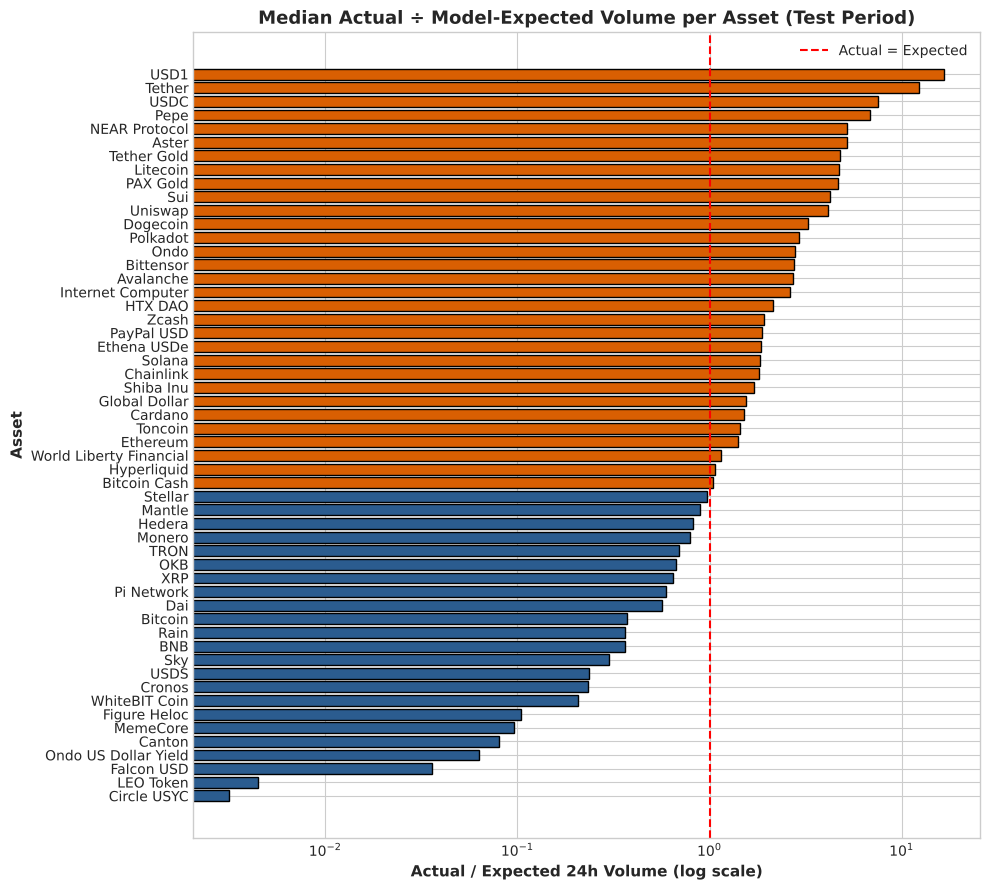

,median actual/expected
name,
NEAR Protocol,5.2050
Pepe,6.8389
USDC,7.5133
Tether,12.2576
USD1,16.6496


,median actual/expected
name,
Circle USYC,0.0032
LEO Token,0.0045
Falcon USD,0.0359
Ondo US Dollar Yield,0.0633
Canton,0.0801


In [49]:
test_res = test[['date', 'name']].copy()
test_res['actual_vol_bn'] = 10**y_test / 1e9
test_res['expected_vol_bn'] = 10**lin.predict(X_test) / 1e9
test_res['ratio_actual_to_expected'] = test_res['actual_vol_bn'] / test_res['expected_vol_bn']
by_asset = test_res.groupby('name')['ratio_actual_to_expected'].median().sort_values()

fig, ax = plt.subplots(figsize=(10, 9))
cols_ = [ORANGE if r_ > 1 else BLUE for r_ in by_asset.values]
ax.barh(by_asset.index, by_asset.values, color=cols_, edgecolor='black')
ax.axvline(1, color='red', ls='--', label='Actual = Expected')
ax.set_xscale('log')
ax.set_title("Median Actual ÷ Model-Expected Volume per Asset (Test Period)")
ax.set_xlabel("Actual / Expected 24h Volume (log scale)"); ax.set_ylabel("Asset"); ax.legend()
plt.tight_layout(); plt.show()
display(by_asset.tail(5).to_frame('median actual/expected')); display(by_asset.head(5).to_frame('median actual/expected'))

**Interpretation:**
* Trading **far above** expectation in the test period (median ratio): USD1 16.6×, Tether 12.3×, USDC 7.5×, Pepe 6.8×, NEAR Protocol 5.2× — the trading stablecoins and some speculative tokens.
* Trading **far below** expectation: Circle USYC (0.003×), LEO Token (0.005×), Falcon USD (0.04×), Ondo US Dollar Yield (0.06×), Canton (0.08×) — yield-bearing/institutional tokens and exchange tokens that are mainly held, not traded.
* These are the same groups responsible for the large residuals in §9.5. A useful next step is to add an explicit token-category feature (trading stablecoin, yield token, exchange token, etc.), which the current dataset does not contain.

## 10. Summary Visualisation Dashboard (Python)
A single-figure overview suitable for the presentation.

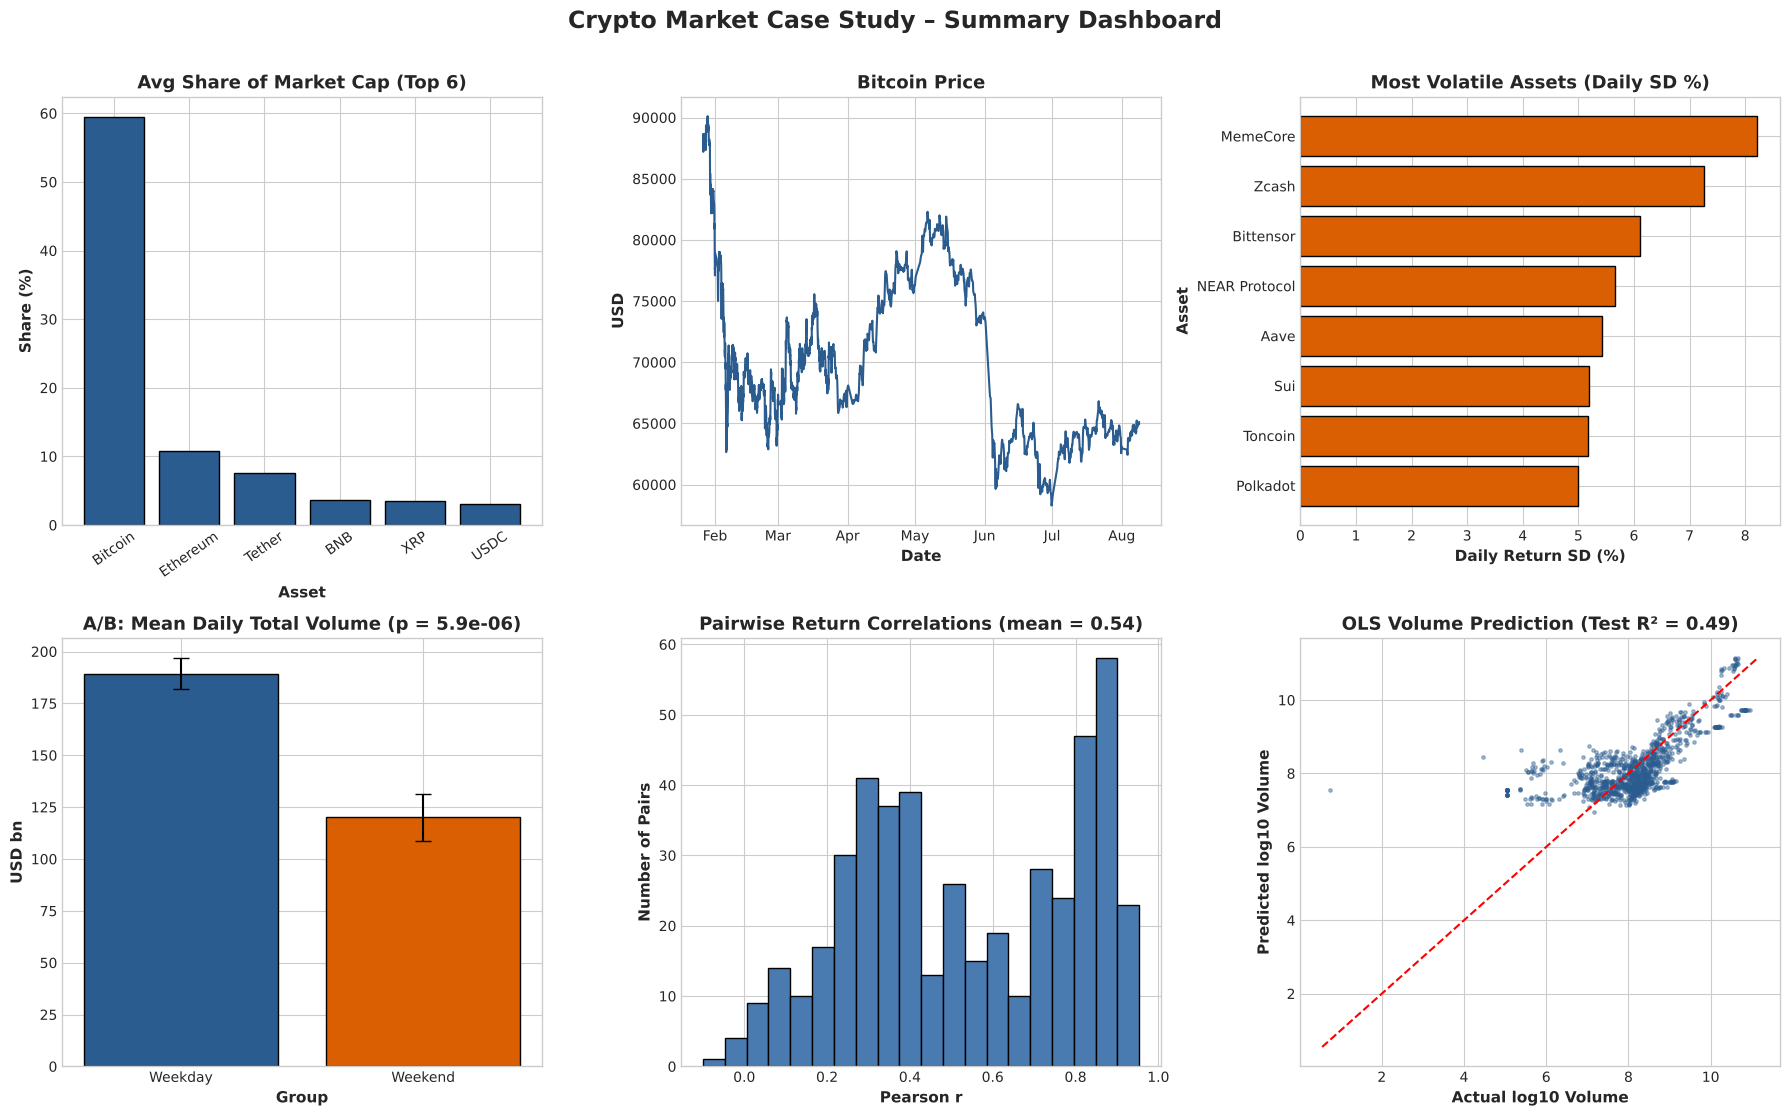

In [50]:
fig = plt.figure(figsize=(18, 11))
gs = fig.add_gridspec(2, 3)

ax = fig.add_subplot(gs[0, 0])
ax.bar(top.index[:6], top.values[:6], color=BLUE, edgecolor='black')
ax.set_title("Avg Share of Market Cap (Top 6)"); ax.set_ylabel("Share (%)"); ax.set_xlabel("Asset"); ax.tick_params(axis='x', rotation=35)

ax = fig.add_subplot(gs[0, 1])
ax.plot(btc_all.index, btc_all.values, color=BLUE); ax.set_title("Bitcoin Price"); ax.set_ylabel("USD"); ax.set_xlabel("Date")
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

ax = fig.add_subplot(gs[0, 2])
sv = vol_by_asset['daily_sd'].sort_values(ascending=False).head(8)
ax.barh(sv.index[::-1], sv.values[::-1], color=ORANGE, edgecolor='black')
ax.set_title("Most Volatile Assets (Daily SD %)"); ax.set_xlabel("Daily Return SD (%)"); ax.set_ylabel("Asset")

ax = fig.add_subplot(gs[1, 0])
ax.bar(['Weekday', 'Weekend'], [A.mean(), B.mean()], color=[BLUE, ORANGE], edgecolor='black',
       yerr=[A.std()/np.sqrt(len(A)), B.std()/np.sqrt(len(B))], capsize=6)
ax.set_title(f"A/B: Mean Daily Total Volume (p = {t1.pvalue:.1e})"); ax.set_ylabel("USD bn"); ax.set_xlabel("Group")

ax = fig.add_subplot(gs[1, 1])
ax.hist(upper.values, bins=20, color=LIGHT, edgecolor='black')
ax.set_title(f"Pairwise Return Correlations (mean = {upper.mean():.2f})"); ax.set_xlabel("Pearson r"); ax.set_ylabel("Number of Pairs")

ax = fig.add_subplot(gs[1, 2])
p_lin = preds['Linear Regression (OLS)']
ax.scatter(y_test, p_lin, s=6, alpha=0.4, color=BLUE)
lim = [y_test.min()-0.2, y_test.max()+0.2]; ax.plot(lim, lim, 'r--')
ax.set_title(f"OLS Volume Prediction (Test R² = {r2_score(y_test, p_lin):.2f})")
ax.set_xlabel("Actual log10 Volume"); ax.set_ylabel("Predicted log10 Volume")

plt.suptitle("Crypto Market Case Study – Summary Dashboard", fontsize=17, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

## 11. Key Findings, Conclusions, Limitations and Future Enhancements

### 11.1 Data preprocessing summary
* 109,130 snapshots, 71 assets, no missing values or duplicates. `total_vol` was **verified** to be a % share of volume; the two label-encoded columns were redundant and dropped.
* Detected and handled: a **change in coverage** (50 → 10 assets on 20 May 2026), **sub-cent prices rounded to \$0** (Shiba Inu, Pepe, HTX DAO), an asset with **no reported volume** (BlackRock BUIDL), and extreme but genuine moves (RaveDAO, Siren).
* Overlapping rolling-24h rows were reduced to an **end-of-day daily panel** (6,150 asset-days; 5,400 in the 50-asset period) so that statistical tests use approximately independent observations.

### 11.2 Key findings
1. **Extreme concentration:** Bitcoin holds 59.5 % of tracked market cap; the top 10 hold 92.9 % (HHI ≈ 3,750).
2. **Stablecoins dominate trading:** Tether alone accounts for 43.9 % of all volume; Bitcoin, with 59.5 % of the value, has only 26.7 % of the volume.
3. **Fat tails:** daily returns are strongly non-normal (Bitcoin excess kurtosis 7.1; across volatile assets, >3σ days occur 3.4× more often than normal theory predicts).
4. **Stable-value vs volatile tokens:** completely separated (rank-biserial r = 1.00).
5. **Size is not safety:** no significant size–volatility correlation (ρ = −0.14, p = 0.37); only a very weak size effect on big-move days (V = 0.07).
6. **Herd behaviour:** average pairwise return correlation 0.54; 13 of 30 assets have β > 1 to Bitcoin; Bitcoin's direction matches the market majority on 86 % of days.
7. **Weekend effect:** total volume is 36.5 % lower at weekends (p < 10⁻⁵, d = 1.05).
8. **Volume–volatility link:** bigger moves come with more trading (ρ = 0.39 within assets; ρ = 0.46 for Bitcoin).
9. **Bitcoin over the period:** −25.9 %, maximum drawdown −35.3 %, but no statistically reliable daily drift (p = 0.54).
10. **Regression:** log volume is explained mainly by size (elasticity ≈ 1.2), then by the size of recent moves and the weekend. OLS achieves test R² = 0.49; Random Forest reaches 0.67 on known assets but generalises worse to unseen assets.

### 11.3 Conclusion
The tracked crypto market behaves largely as **one Bitcoin-driven system**: value is concentrated in Bitcoin, most assets move with it, and diversification across large tokens is limited. Trading activity is concentrated in stablecoins, drops sharply at weekends and rises on volatile days. A simple, interpretable log-log regression explains about half of the variation in daily trading volume and can flag assets whose activity is abnormally high or low relative to their size.

### 11.4 Limitations
* **Short and uneven window:** about 6.5 months in total, and only 108 days with the full 50-asset coverage; collection density varies strongly by month.
* **Survivorship / selection:** the dataset contains only assets that were in the top 50 (later top 10) at the time; assets that fell out are lost, and newcomers appear only briefly.
* **Rounding:** 2-decimal prices make price-based calculations impossible for sub-cent assets.
* **Rolling windows:** `vol_24h` and `chg_24h` are 24-hour rolling values, and snapshot times vary, so daily figures are approximate.
* **Single-period observations:** results such as the weekday return pattern or the Bitcoin drawdown describe this period only and may not repeat.
* **Associations, not causes:** correlations (e.g. volume vs. volatility) do not establish causality.
* **Regression:** residuals are skewed and heteroscedastic; the model has no token-category information and transfers only roughly to unseen assets.

### 11.5 Future enhancements
* Collect a longer, evenly spaced history (e.g. a fixed hourly or daily schedule) with full precision prices.
* Add token-category metadata (stablecoin type, layer-1, exchange token, meme, real-world asset) as model features.
* Use time-series models (e.g. GARCH for volatility clustering, ARIMA/LSTM for forecasting next-day volume) and lagged features for true forecasting.
* Use robust/clustered standard errors or mixed-effects models to handle repeated observations of the same asset.
* Build an interactive dashboard (Tableau / Power BI) on top of the daily panel.

### 11.6 References
* Dataset: `cleaned_crypto.csv` https://www.kaggle.com/datasets/adrianjuliusaluoch/hourly-crypto-stocks-market-data.
* pandas documentation — https://pandas.pydata.org/docs/
* SciPy statistical functions (`scipy.stats`) — https://docs.scipy.org/doc/scipy/reference/stats.html
* statsmodels OLS regression — https://www.statsmodels.org/stable/regression.html
* scikit-learn user guide (LinearRegression, RandomForestRegressor, GroupKFold) — https://scikit-learn.org/stable/user_guide.html
* Matplotlib & Seaborn documentation — https://matplotlib.org/stable/ , https://seaborn.pydata.org/